# Лабораторна робота №4
## Дослідження дерев рішень та ансамблів за наявності пропусків
**Мулявко Софія Марківна, Феі-46. N = 18; SEED = 42 + N = 60.**

Мета: порівняти DT, RF і XGBoost на Annealing, перевірити користь індикаторів пропусків, оцінити процедуру налаштування без витоку та пояснити прогнози. Основна метрика - macro F1. Параметри експерименту визначені до перегляду test: holdout 20%, спільні 5×3 CV, зовнішня CV 5 блоків, внутрішня 3, по 30 випробувань Optuna. Модель для докладної test-оцінки обирається за середньою nested CV.

Джерело вимог: надана методичка ML-Practice-4.pdf, с. 1-10. Дані завантажуються викликом fetch_openml(name='anneal', version=1, as_frame=True); у комплекті є точна локальна копія результату для автономного відтворення. Код не використовує наперед обчислені метрики чи моделі: Restart & Run All повторює експерименти.


In [1]:
from pathlib import Path
import os, json, time, random, platform, importlib.metadata as md
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
import joblib, optuna, shap
from sklearn.datasets import fetch_openml
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
    StratifiedKFold, cross_validate, cross_val_score, cross_val_predict)
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from scipy.stats import t, chi2_contingency, fisher_exact, MonteCarloMethod
SEED = 42 + 18
random.seed(SEED); np.random.seed(SEED)
N_TRIALS = 30
RESUME = os.environ.get("LAB4_RESUME") == "1"
NAMES = ['DT','RF','XGB']
ROOT = Path.cwd()
PROJECT = ROOT if (ROOT/'lab.py').exists() else ROOT/'project'
PROJECT.mkdir(exist_ok=True)
RESULT = PROJECT/'results'; RESULT.mkdir(exist_ok=True)
optuna.logging.set_verbosity(optuna.logging.WARNING)
plt.rcParams.update({'figure.figsize':(8,4.8), 'figure.dpi':120,
 'savefig.dpi':180, 'font.size':10, 'axes.spines.top':False,
 'axes.spines.right':False, 'axes.grid':False})
# Використання спільного стилю під час виконання в навчальному середовищі.
try:
 from mpl_style import apply
 apply()
except ImportError:
 pass
versions={p:md.version(p) for p in ['numpy','pandas','scipy','scikit-learn',
 'matplotlib','optuna','xgboost','shap','joblib','nbformat','nbclient','ipykernel']}
print('Python:',platform.python_version(), 'SEED:',SEED)
display(pd.Series(versions,name='версія').to_frame())
(PROJECT/'requirements.txt').write_text('\n'.join(f'{p}=={v}' for p,v in versions.items())+'\n')
def note(s): display(Markdown(s))
def table(n, title, df):
 note(f'У таблиці {n} наведено {title.lower()}.\n\n**Таблиця {n}. {title}**')
 display(df); df.to_csv(RESULT/f'table_{n}.csv',index=True)
fig_no=0
def showfig(fig, title):
 global fig_no
 fig_no+=1
 note(f'На рисунку {fig_no} показано {title.lower()}.')
 fig.tight_layout(); fig.savefig(RESULT/f'figure_{fig_no:02}.png',bbox_inches='tight')
 display(Image(filename=str(RESULT/f'figure_{fig_no:02}.png'))); plt.close(fig)
 note(f'**Рисунок {fig_no}. {title}**')
def bar(values, title, xlabel, top=None):
 s=pd.Series(values).sort_values()
 if top: s=s.tail(top)
 fig,ax=plt.subplots(figsize=(8,max(3,len(s)*.23+1)))
 ax.barh(s.index.astype(str),s.values,color='#4477AA')
 ax.set_xlabel(xlabel); ax.set_title(title)
 ax.grid(axis='x',alpha=.2); showfig(fig,title)


/work/scratch/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.14.4 SEED: 60


,версія
numpy,2.3.5
pandas,2.3.3
scipy,1.18.1
scikit-learn,1.9.1
matplotlib,3.11.2
optuna,5.0.0
xgboost,3.4.1
shap,0.54.1
joblib,1.6.0
nbformat,5.11.1


## 1. Аудит даних і пропусків
Окремо відрізняємо відсутній клас, порожні ознаки і сталі непорожні значення. Видалення технічно непридатних ознак та рідкісного класу змінює область застосування висновків. Для вибору ознак, що видаляються, після holdout використовується лише train; початковий аудит всього набору є описовим.


OpenML ID: 2 ; форма: (898, 38)
Типи: {'object': 26, 'float64': 8, 'int64': 4}
Фактичні класи: ['1', '2', '3', '5', 'U']
Невиявлені позначення серед 1,2,3,4,5,U: ['4']


/tmp/ipykernel_138/3076431200.py:10: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X0=X0.replace({None:np.nan})


,тип,пропуски_%,унікальних_без_NaN
family,object,85.968820,2
product-type,object,0.000000,1
steel,object,9.576837,7
carbon,int64,0.000000,10
hardness,int64,0.000000,7
temper_rolling,object,84.743875,1
condition,object,33.741648,2
formability,object,35.412027,4
strength,int64,0.000000,8
non-ageing,object,88.307350,1


На рисунку 1 показано розподіл класів annealing.

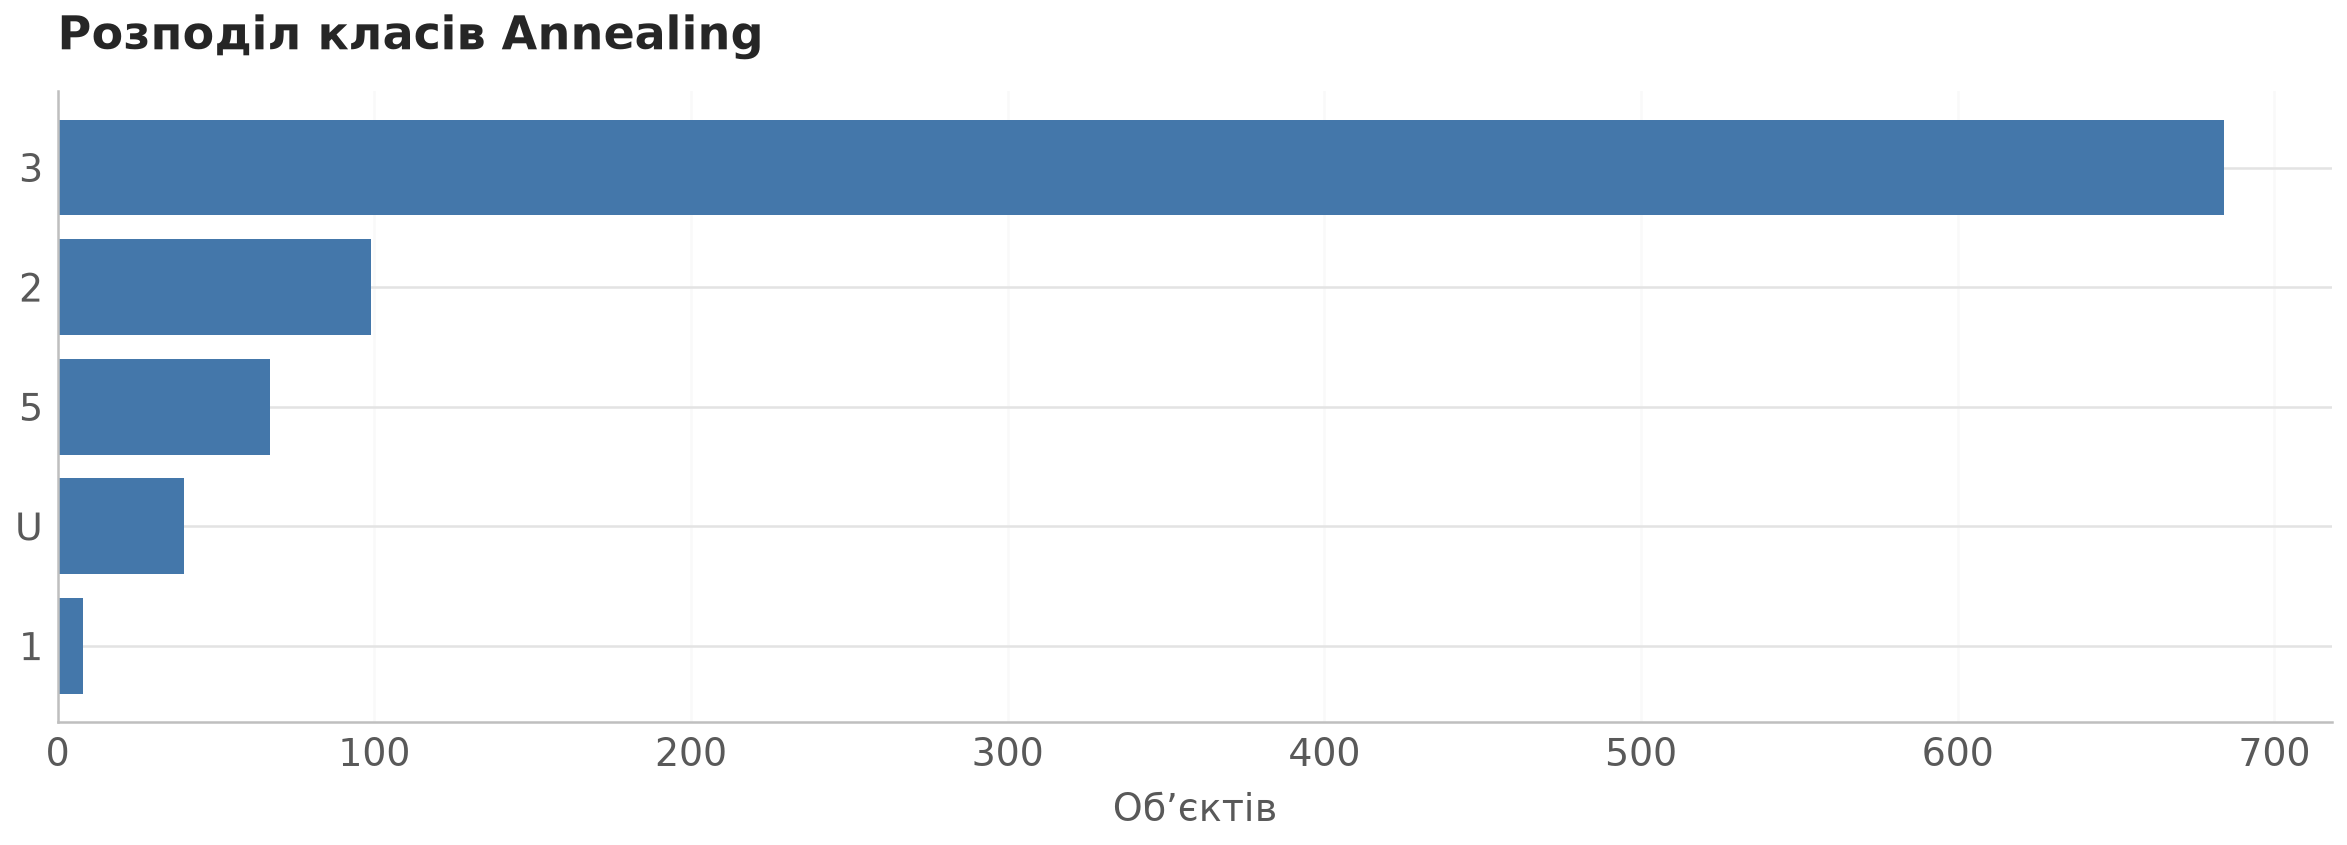

**Рисунок 1. Розподіл класів Annealing**

На рисунку 2 показано частка пропусків у початкових ознаках.

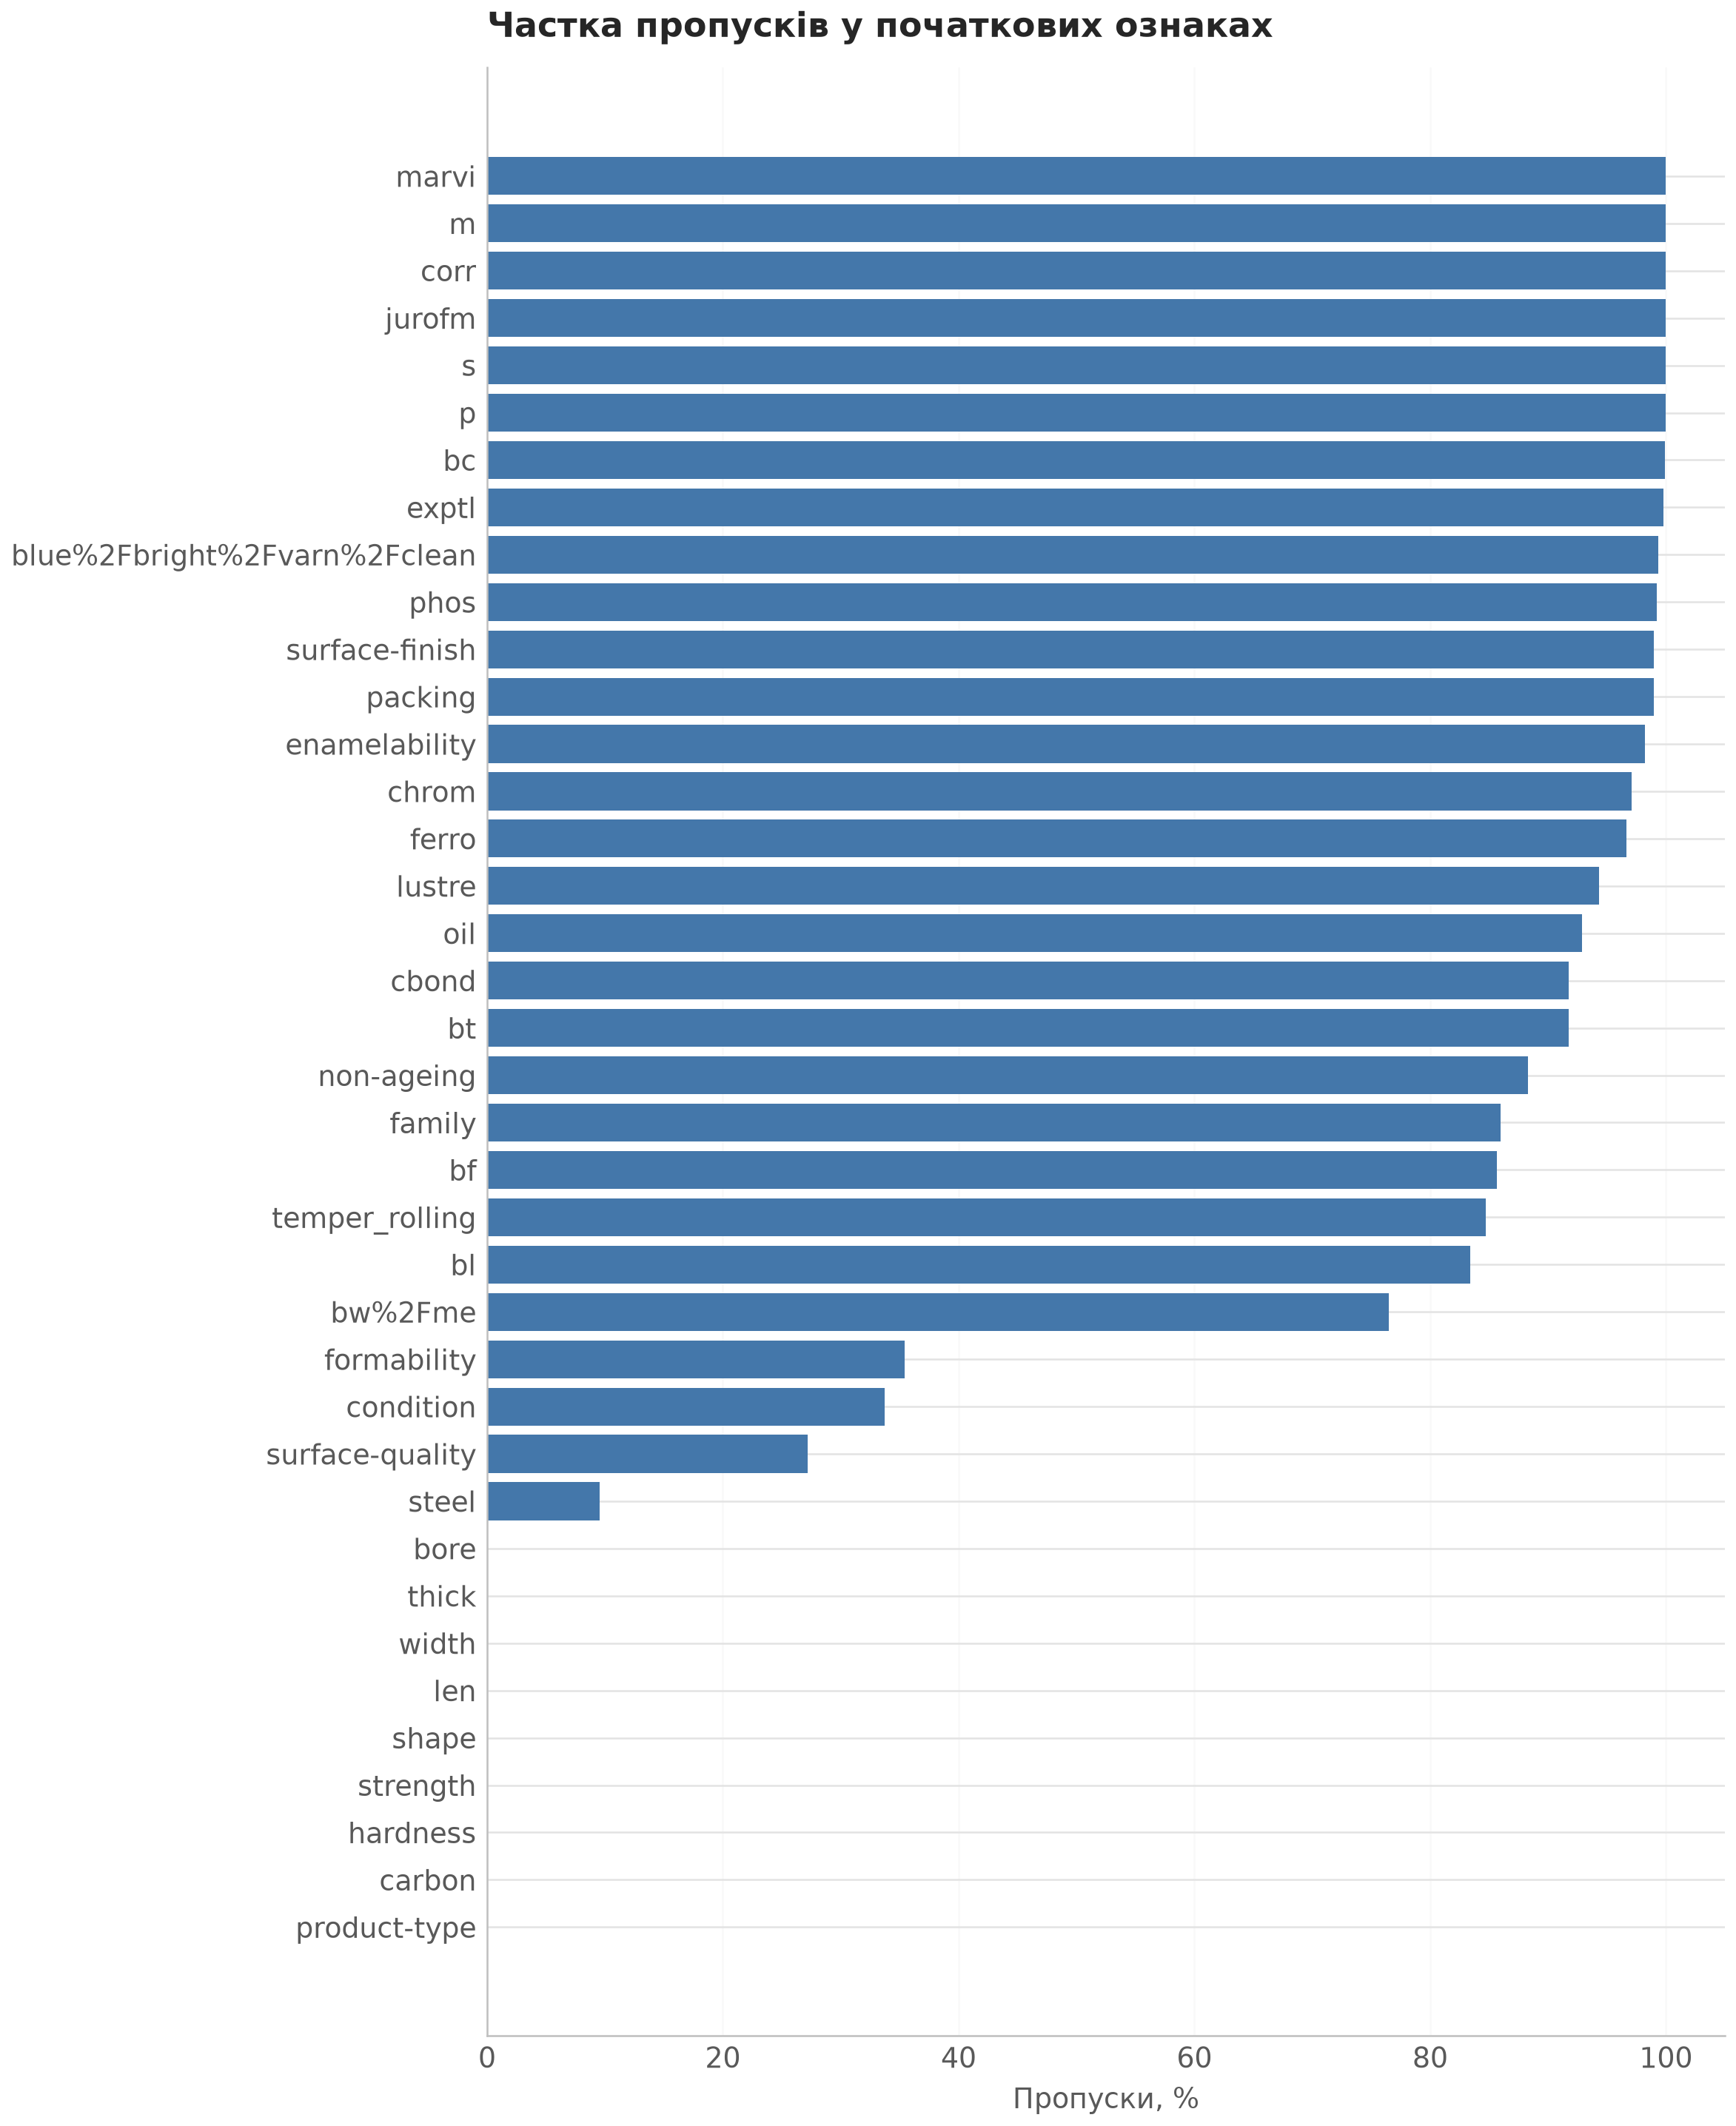

**Рисунок 2. Частка пропусків у початкових ознаках**

Видалені за train порожні/сталі ознаки: ['product-type', 'temper_rolling', 'non-ageing', 'surface-finish', 'bc', 'bf', 'bt', 'bl', 'm', 'chrom', 'phos', 'cbond', 'marvi', 'exptl', 'ferro', 'corr', 'lustre', 'jurofm', 's', 'p']
Виключені рідкісні класи: ['1'] ; їхні частоти: {'1': 8}
Кодування класів: {0: '2', 1: '3', 2: '5', 3: 'U'}


,train,test
2,79,20
3,547,137
5,54,13
U,32,8


Виключено класи ['1'] з частотами {'1': 8}: їх недостатньо для надійного багаторівневого розбиття. Об’єднання класів без предметного обґрунтування не виконувалося. Висновки стосуються лише залишених класів ['2', '3', '5', 'U']; якість для виключених класів не оцінюється. Після поділу є 712 train і 178 test об’єктів. Значення імпутації не оцінювалися до CV.

blue%2Fbright%2Fvarn%2Fclean


,2,3,5,U
blue%2Fbright%2Fvarn%2Fclean,,,,
False,3,1,0,0
True,76,546,54,32


... (6 outputs left out)

family


,2,3,5,U
family,,,,
False,0,38,54,9
True,79,509,0,23


,ознака,пропуски_%,метод,p,min_expected
0,blue%2Fbright%2Fvarn%2Fclean,99.438202,"Fisher RxC, Monte Carlo 9999",0.0154,0.179775
1,packing,98.876404,"Fisher RxC, Monte Carlo 9999",0.8633,0.359551
2,enamelability,98.174157,"Fisher RxC, Monte Carlo 9999",0.0003,0.584270
3,oil,92.556180,"Fisher RxC, Monte Carlo 9999",0.0003,2.382022
4,family,85.814607,"Fisher RxC, Monte Carlo 9999",0.0001,4.539326


На рівні 0,05 виявлено зв’язок пропусків із класом для 4 із 5 перевірених ознак. Це розвідувальні тести без поправки на множинність; Monte Carlo p має похибку. Залежність суперечить MCAR, але не доводить MAR чи MNAR. Невідхилення незалежності також не доводить MCAR; структурні пропуски можуть кодувати незастосовність параметра.

In [2]:
data_file=PROJECT/'anneal_openml.joblib'
if data_file.exists():
 data=joblib.load(data_file)
else:
 data=fetch_openml(name='anneal',version=1,as_frame=True)
 joblib.dump(data,data_file,compress=3)
X0=data.data.copy(); y0=data.target.astype(str)
for c in X0.select_dtypes(include=['category','string']).columns:
 X0[c]=X0[c].astype(object)
X0=X0.replace({None:np.nan})
print('OpenML ID:',data.details.get('id'),'; форма:',X0.shape)
print('Типи:',X0.dtypes.astype(str).value_counts().to_dict())
print('Фактичні класи:',sorted(y0.unique()))
print('Невиявлені позначення серед 1,2,3,4,5,U:',sorted(set(['1','2','3','4','5','U'])-set(y0.unique())))
audit=pd.DataFrame({'тип':X0.dtypes.astype(str),'пропуски_%':X0.isna().mean()*100,
 'унікальних_без_NaN':X0.nunique(dropna=True)})
display(audit)
audit.to_csv(RESULT/'data_audit.csv')
bar(y0.value_counts().sort_index(),'Розподіл класів Annealing','Об’єктів')
bar(X0.isna().mean()*100,'Частка пропусків у початкових ознаках','Пропуски, %')
# Мінімум 10 об'єктів - консервативне правило для holdout + зовнішніх 5 і внутрішніх 3 блоків.
counts=y0.value_counts(); rare=counts[counts<10].index.tolist()
mask=~y0.isin(rare)
X=X0.loc[mask].copy(); y_labels=y0.loc[mask]
encoder=LabelEncoder(); y=encoder.fit_transform(y_labels)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,stratify=y,random_state=SEED)
drop=X_train.columns[X_train.nunique(dropna=True)<=1].tolist()
X_train=X_train.drop(columns=drop); X_test=X_test.drop(columns=drop)
num=X_train.select_dtypes(include='number').columns.tolist()
cat=[c for c in X_train.columns if c not in num]
print('Видалені за train порожні/сталі ознаки:',drop)
print('Виключені рідкісні класи:',rare, '; їхні частоти:',counts.loc[rare].to_dict())
print('Кодування класів:',dict(enumerate(encoder.classes_)))
display(pd.DataFrame({'train':np.bincount(y_train),'test':np.bincount(y_test)},index=encoder.classes_))
note(f'Виключено класи {rare} з частотами {counts.loc[rare].to_dict()}: їх недостатньо для надійного багаторівневого розбиття. Об’єднання класів без предметного обґрунтування не виконувалося. Висновки стосуються лише залишених класів {encoder.classes_.tolist()}; якість для виключених класів не оцінюється. Після поділу є {len(X_train)} train і {len(X_test)} test об’єктів. Значення імпутації не оцінювалися до CV.')
# Вибір 5 найбільш пропущених непорожніх змінних тільки на train.
miss_features=X_train.isna().mean().loc[lambda z:(z>0)&(z<1)].nlargest(5).index
missing_tests=[]
for c in miss_features:
 ct=pd.crosstab(X_train[c].isna(),y_train).reindex(index=[False,True],fill_value=0)
 ct.columns=encoder.classes_
 print(c); display(ct)
 chi,p,dof,expected=chi2_contingency(ct)
 if expected.min()<5:
  p=fisher_exact(ct.to_numpy(),method=MonteCarloMethod(n_resamples=9999,
      rng=np.random.default_rng(SEED))).pvalue
  method='Fisher RxC, Monte Carlo 9999'
 else: method='χ² Pearson'
 missing_tests.append({'ознака':c,'пропуски_%':X_train[c].isna().mean()*100,
  'метод':method,'p':p,'min_expected':expected.min()})
missing_tests=pd.DataFrame(missing_tests); display(missing_tests)
missing_tests.to_csv(RESULT/'missing_tests.csv',index=False)
note(f'На рівні 0,05 виявлено зв’язок пропусків із класом для {(missing_tests.p<.05).sum()} із {len(missing_tests)} перевірених ознак. Це розвідувальні тести без поправки на множинність; Monte Carlo p має похибку. Залежність суперечить MCAR, але не доводить MAR чи MNAR. Невідхилення незалежності також не доводить MCAR; структурні пропуски можуть кодувати незастосовність параметра.')


## 2. Пайплайни A/B і спільна повторна CV
A: медіана числових, мода категоріальних, one-hot. B додатково формує індикатори тих колонок, де NaN були в поточному навчальному блоці. `error_on_new=False` дозволяє пропуск у новій колонці validation/test без помилки; новий індикатор при цьому не створюється. Імпутери, словник one-hot та індикатори навчаються всередині кожного fit Pipeline. Невідомі категорії кодуються нулями. Порожні в окремому блоці колонки зберігаються через keep_empty_features.


In [3]:
def build_preprocessor(with_indicators):
 trs=[('num',SimpleImputer(strategy='median',keep_empty_features=True),num),
 ('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent',keep_empty_features=True)),
 ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cat)]
 if with_indicators:
  trs.append(('miss',MissingIndicator(features='missing-only',error_on_new=False),list(X_train.columns)))
 return ColumnTransformer(trs)
def make_model(name,params=None):
 p=params or {}
 if name=='DT': return DecisionTreeClassifier(random_state=SEED,**p)
 if name=='RF': return RandomForestClassifier(random_state=SEED,n_jobs=1,**p)
 return XGBClassifier(random_state=SEED,n_jobs=1,eval_metric='mlogloss',**p)
def build_pipeline(name,with_indicators=True,params=None):
 return Pipeline([('prep',build_preprocessor(with_indicators)),('clf',make_model(name,params))])
folds=list(RepeatedStratifiedKFold(n_splits=5,n_repeats=3,random_state=SEED).split(X_train,y_train))
outer=list(StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED).split(X_train,y_train))
fold_checks=[]
def check_folds(splits,yy,level):
 for j,(tr,va) in enumerate(splits):
  a=np.bincount(yy[tr],minlength=len(encoder.classes_)); b=np.bincount(yy[va],minlength=len(encoder.classes_))
  assert a.min()>0 and b.min()>0
  assert not set(tr)&set(va)
  fold_checks.append({'рівень':level,'блок':j,'train_min':int(a.min()),'valid_min':int(b.min())})
check_folds(folds,y_train,'repeated')
check_folds(outer,y_train,'outer')
for j,(tr,va) in enumerate(outer):
 inner=list(StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED).split(X_train.iloc[tr],y_train[tr]))
 check_folds(inner,y_train[tr],f'inner_outer_{j}')
check_folds(list(StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED).split(X_train,y_train)),y_train,'inner_full')
fold_checks=pd.DataFrame(fold_checks); display(fold_checks.groupby('рівень')[['train_min','valid_min']].min())
fold_checks.to_csv(RESULT/'fold_checks.csv',index=False)
assert set(X_train.index).isdisjoint(X_test.index)
joblib.dump({'train_index':X_train.index,'test_index':X_test.index,'folds':folds,'outer':outer,
 'encoder':encoder,'dropped':drop},RESULT/'splits.joblib',compress=3)
scoring={'acc':'accuracy','f1m':'f1_macro','bacc':'balanced_accuracy'}
base={}; base_rows={}
for variant,flag in [('A',False),('B',True)]:
 rows=[]
 for name in NAMES:
  print('Baseline',variant,name,flush=True)
  res=cross_validate(build_pipeline(name,flag),X_train,y_train,cv=folds,scoring=scoring,error_score='raise')
  base[variant,name]=res
  rows.append({'модель':name,**{m:f'{res["test_"+m].mean():.4f} ± {res["test_"+m].std(ddof=1):.4f}' for m in scoring}})
 base_rows[variant]=pd.DataFrame(rows).set_index('модель')
 table(1 if variant=='A' else 2,f'Базова CV, варіант {variant}: середнє ± вибіркове SD',base_rows[variant])
joblib.dump(base,RESULT/'baseline.joblib',compress=3)
best_base=max(NAMES,key=lambda n:base['B',n]['test_f1m'].mean())
note(f'Найвище середнє базової B-CV має {best_base}: macro F1 = {base["B",best_base]["test_f1m"].mean():.4f}, SD = {base["B",best_base]["test_f1m"].std(ddof=1):.4f}. SD описує варіативність блоків, а не незалежну стандартну похибку: навчальні вибірки перекриваються. Усі шість порівнянь використовують збережений спільний список із {len(folds)} розбиттів.')


,train_min,valid_min
рівень,,
inner_full,21,10
inner_outer_0,17,8
inner_outer_1,16,8
inner_outer_2,16,8
inner_outer_3,17,8
inner_outer_4,17,8
outer,25,6
repeated,25,6


Baseline A DT


Baseline A RF


Baseline A XGB


У таблиці 1 наведено базова cv, варіант a: середнє ± вибіркове sd.

**Таблиця 1. Базова CV, варіант A: середнє ± вибіркове SD**

,acc,f1m,bacc
модель,,,
DT,0.9466 ± 0.0206,0.9253 ± 0.0255,0.9279 ± 0.0284
RF,0.9466 ± 0.0199,0.9213 ± 0.0271,0.9225 ± 0.0366
XGB,0.9489 ± 0.0159,0.9265 ± 0.0206,0.9232 ± 0.0275


... (2 outputs left out)

Baseline B XGB


У таблиці 2 наведено базова cv, варіант b: середнє ± вибіркове sd.

**Таблиця 2. Базова CV, варіант B: середнє ± вибіркове SD**

,acc,f1m,bacc
модель,,,
DT,0.9949 ± 0.0056,0.9905 ± 0.0110,0.9896 ± 0.0170
RF,0.9963 ± 0.0052,0.9923 ± 0.0112,0.9909 ± 0.0173
XGB,0.9934 ± 0.0077,0.9889 ± 0.0130,0.9891 ± 0.0174


Найвище середнє базової B-CV має RF: macro F1 = 0.9923, SD = 0.0112. SD описує варіативність блоків, а не незалежну стандартну похибку: навчальні вибірки перекриваються. Усі шість порівнянь використовують збережений спільний список із 15 розбиттів.

## 3. Optuna та вкладена оцінка
На кожному зовнішньому блоці починається нове дослідження TPE(seed=60). Об’єктивна функція отримує весь Pipeline, лише зовнішню train-частину та спільні внутрішні блоки. Кожне дослідження має 30 trials без прунінгу. Зовнішні оцінки характеризують процедуру вибору гіперпараметрів, а не одну фіксовану модель. Після nested CV окремі дослідження на всьому train дають остаточні параметри. Test у цьому розділі не використовується.

Під час підготовки цього комплекту завершені дослідження Optuna відновлено з контрольних точок після перезапуску сесії. Стовпець часу в таблиці 3 показує тривалість поточного виконання з відновленням і повторним fit, а не повну вартість пошуку. Усі 18 досліджень містять по 30 реально завершених trials. Звичайний Restart & Run All без LAB4_RESUME виконує пошук заново.


Nested DT 1


Nested DT 2


Nested DT 3


Nested DT 4


Nested DT 5


Final tune DT


... (16 outputs left out)

,max_depth,min_samples_split,min_samples_leaf,class_weight,n_estimators,max_features,learning_rate,subsample,colsample_bytree,min_child_weight
DT,10.0,3.0,1.0,не застосовується / None,не застосовується / None,не застосовується / None,не застосовується / None,не застосовується / None,не застосовується / None,не застосовується / None
RF,9.0,не застосовується / None,1,balanced_subsample,500,log2,не застосовується / None,не застосовується / None,не застосовується / None,не застосовується / None
XGB,8.0,не застосовується / None,не застосовується / None,не застосовується / None,216.0,не застосовується / None,0.012058,0.696894,0.663529,1.043548


За nested CV обрано RF: 0.9934 ± 0.0104. Різниця best_value - nested для неї = +0.0024. Ці оцінки отримані на різних навчальних обсягах і блоках: знак різниці в окремому експерименті не гарантований. Максимум внутрішньої CV не є незалежною оцінкою узагальнення.

/tmp/ipykernel_138/1734775700.py:56: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax=optuna.visualization.matplotlib.plot_optimization_history(studies[name])


На рисунку 3 показано dt: історія оптимізації macro f1.

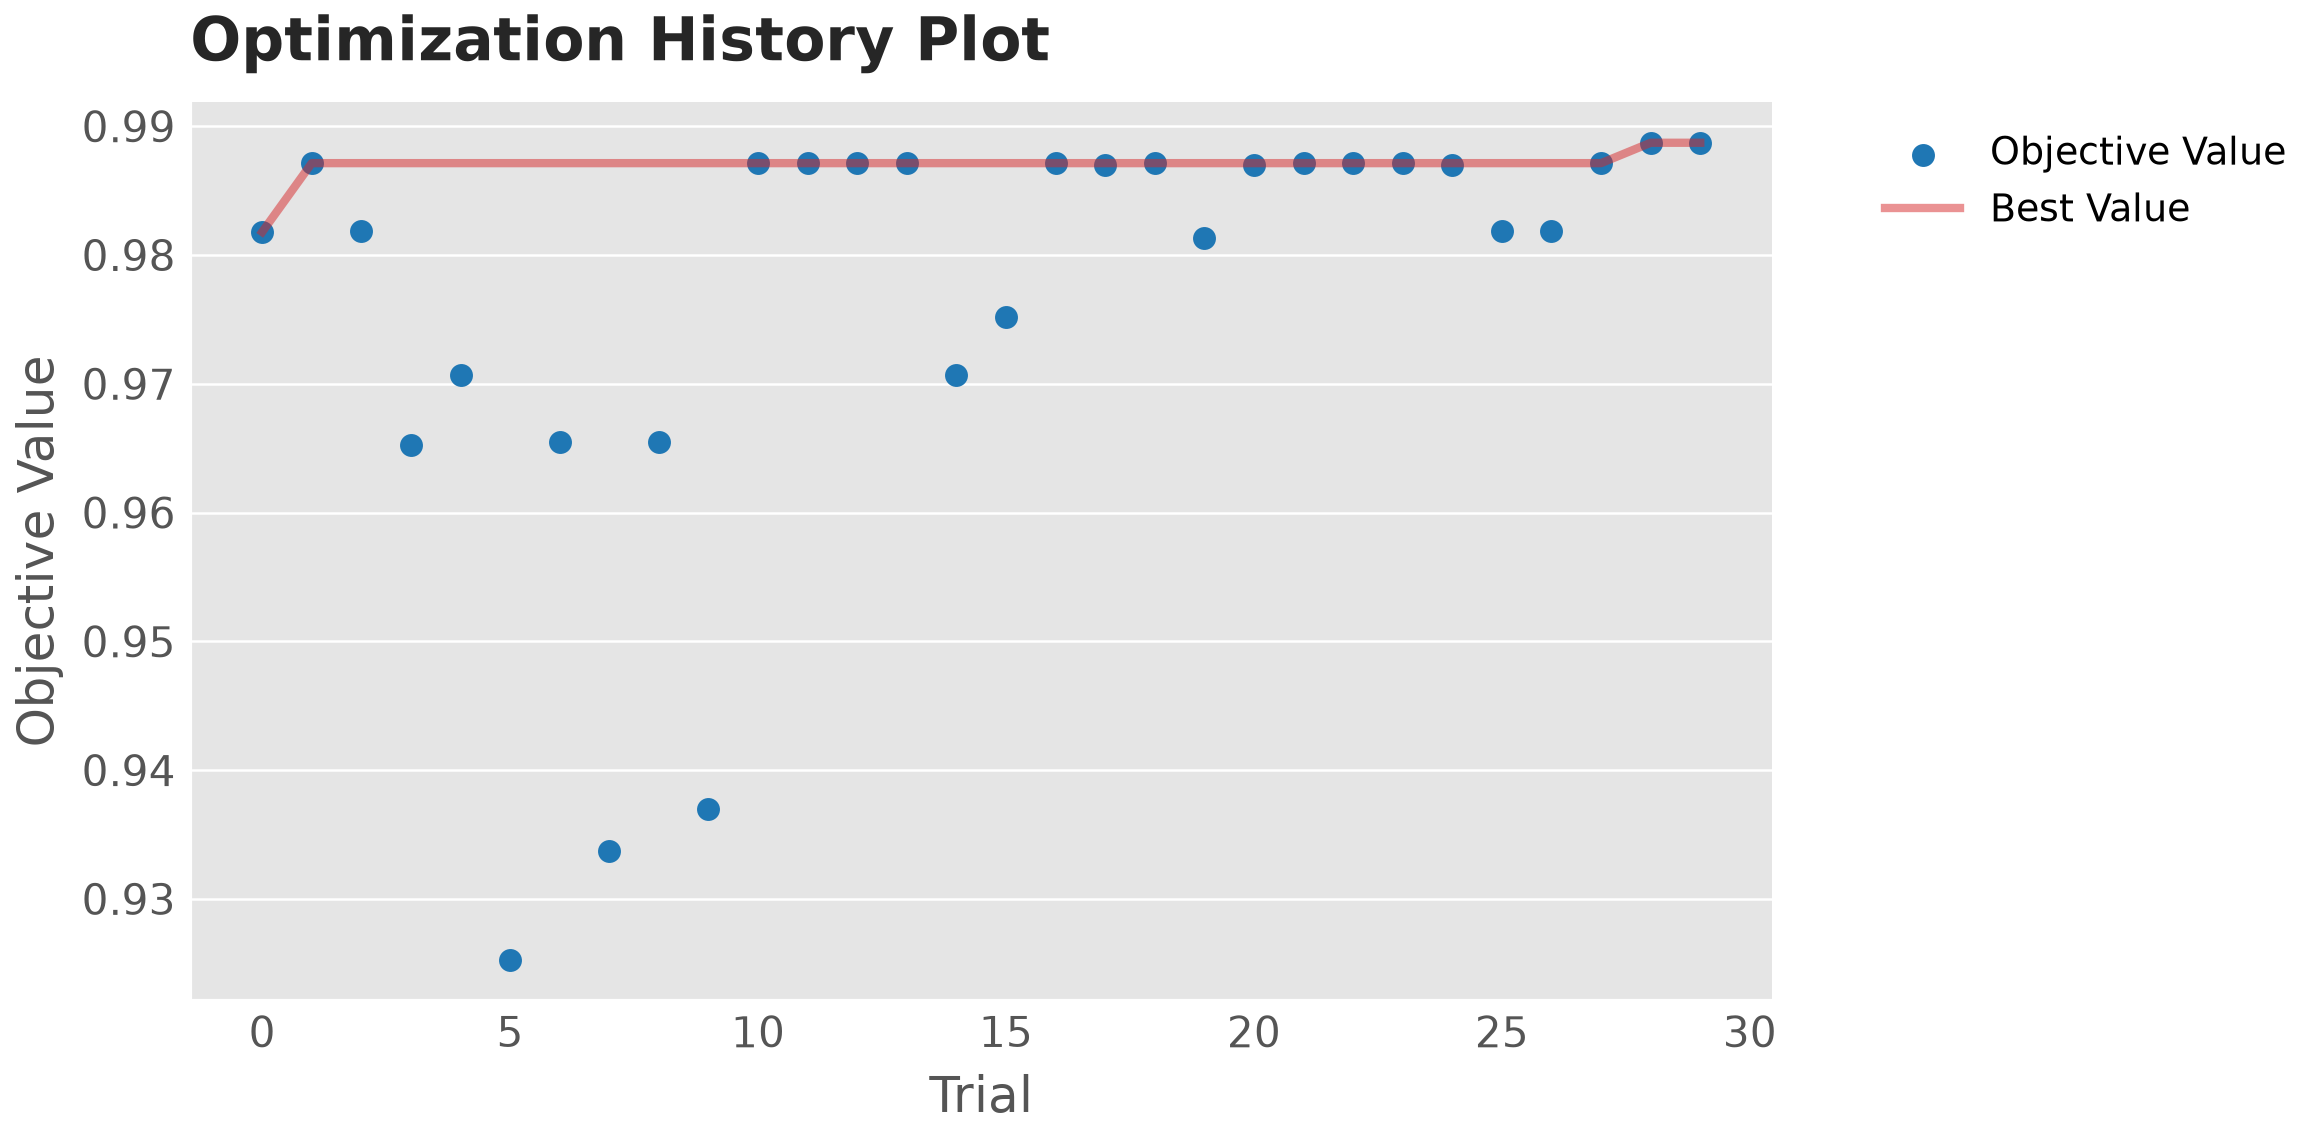

**Рисунок 3. DT: історія оптимізації macro F1**

/tmp/ipykernel_138/1734775700.py:59: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax=optuna.visualization.matplotlib.plot_param_importances(studies[name],evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED))


На рисунку 4 показано dt: важливість гіперпараметрів optuna.

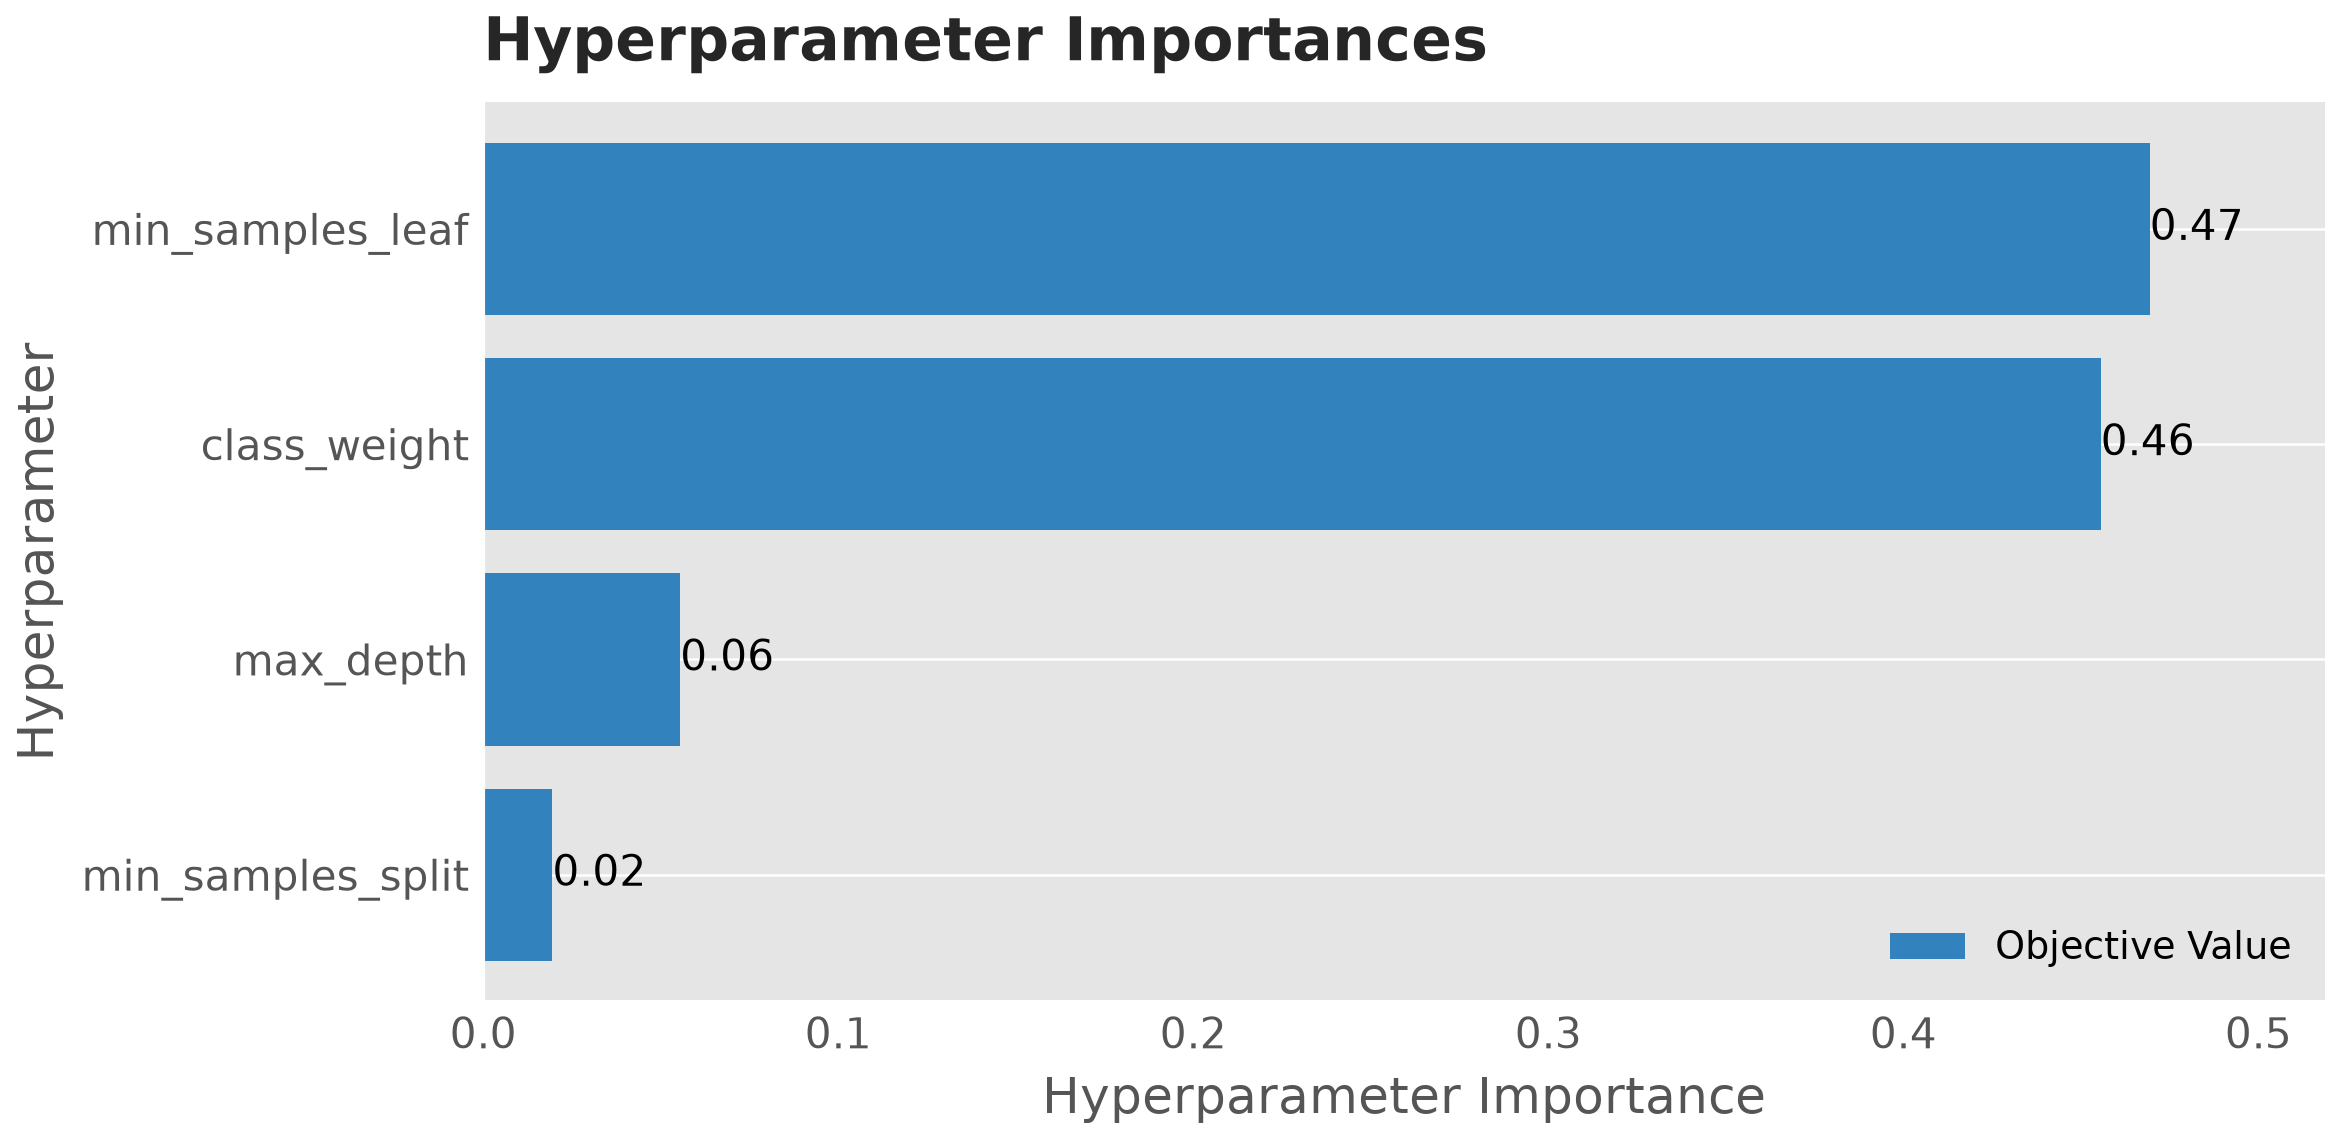

**Рисунок 4. DT: важливість гіперпараметрів Optuna**

DT: найважливіший параметр за fANOVA - min_samples_leaf; приріст найкращого значення за останні 10 trials = 0.0016. Плато є емпіричною ознакою стабілізації лише в межах цього бюджету, а не доказом глобального оптимуму. Важливість залежить від заданого діапазону та лише 30 спроб.

/tmp/ipykernel_138/1734775700.py:56: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax=optuna.visualization.matplotlib.plot_optimization_history(studies[name])


На рисунку 5 показано rf: історія оптимізації macro f1.

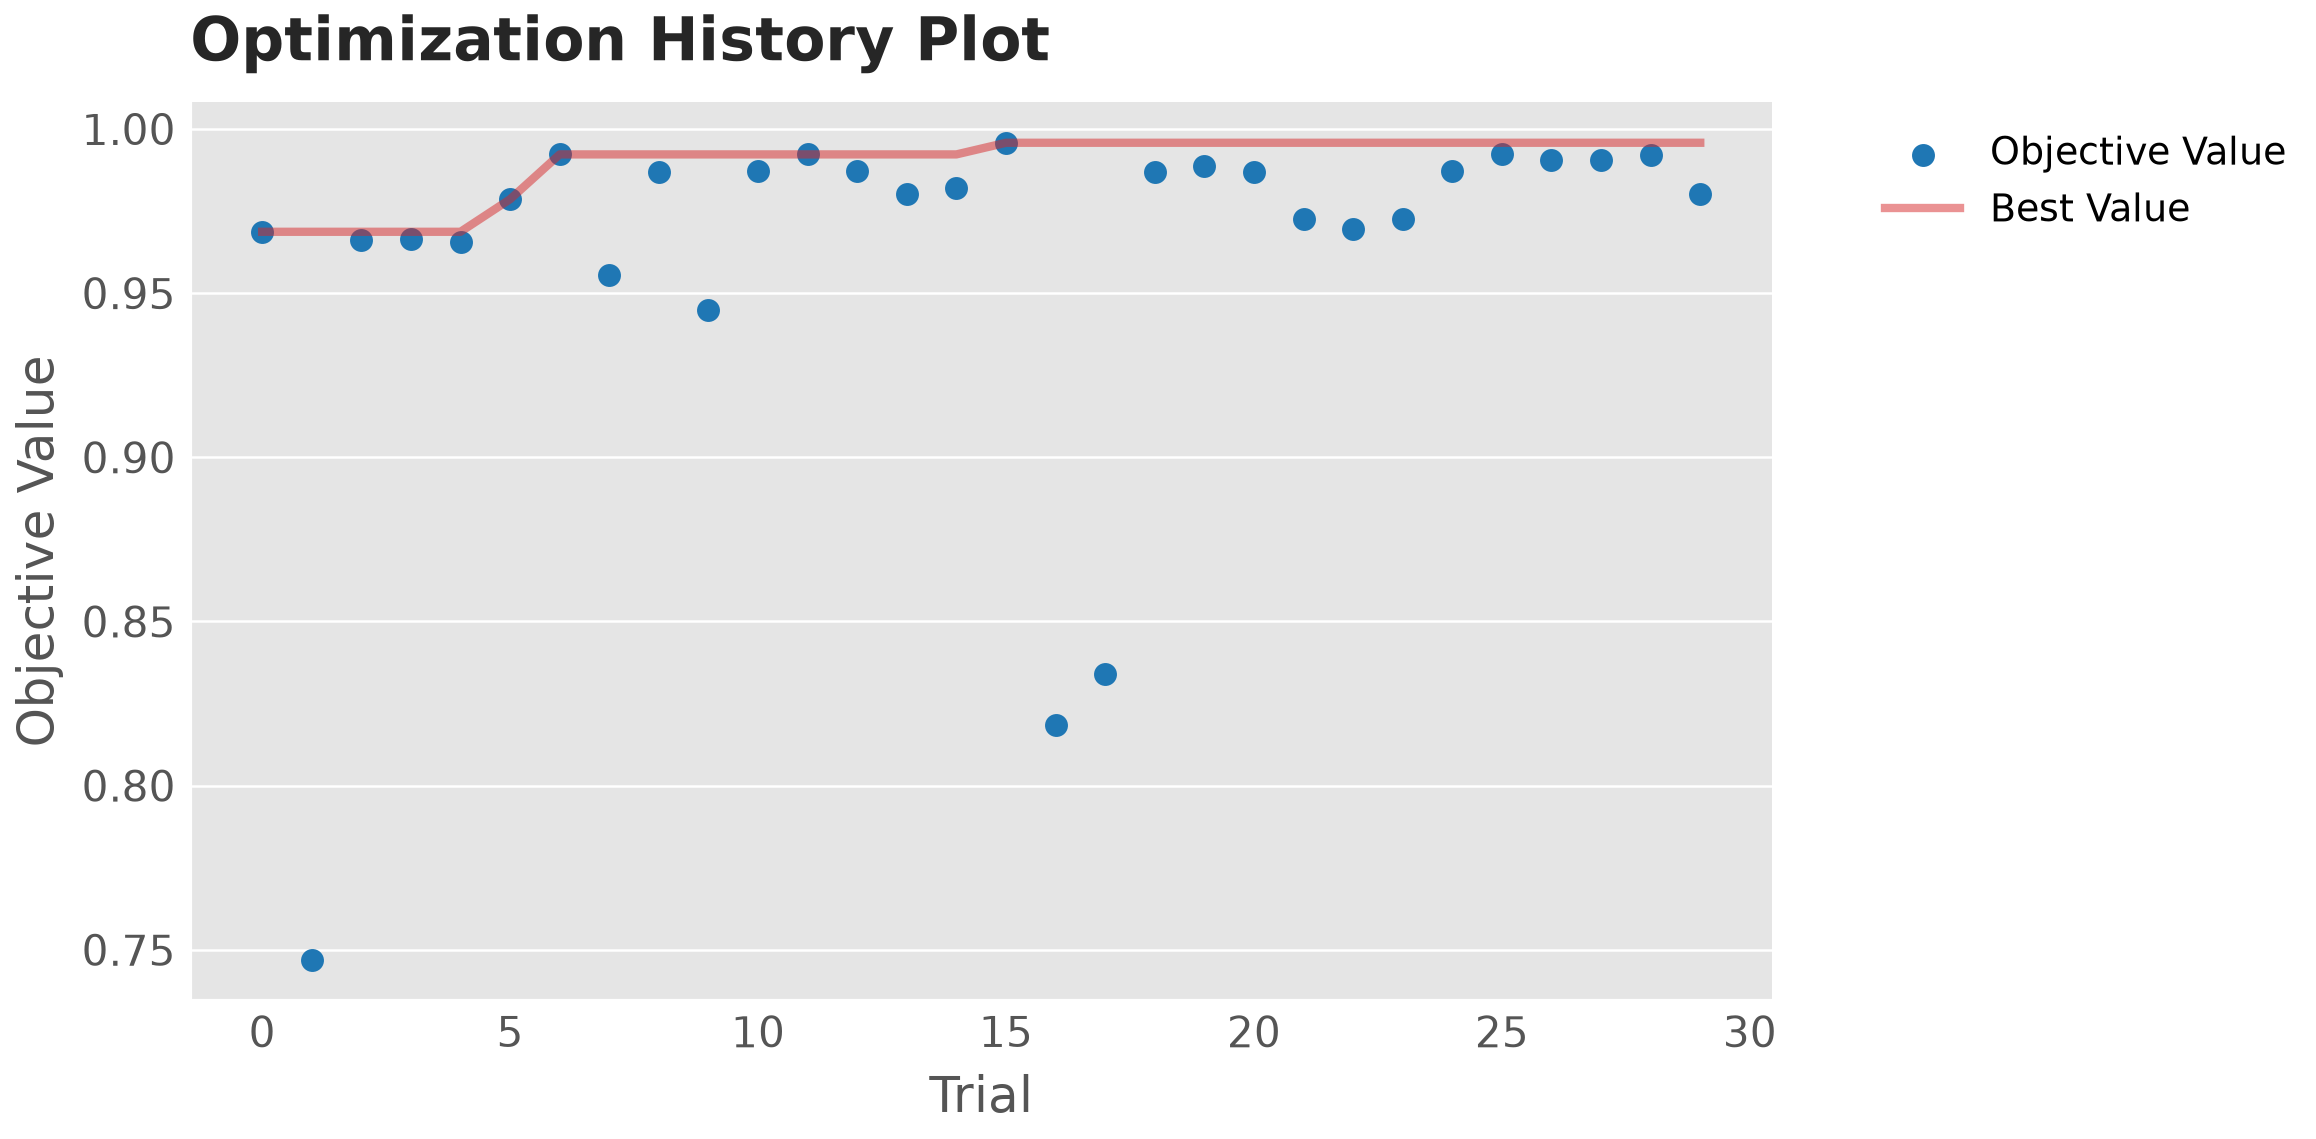

**Рисунок 5. RF: історія оптимізації macro F1**

/tmp/ipykernel_138/1734775700.py:59: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax=optuna.visualization.matplotlib.plot_param_importances(studies[name],evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED))


На рисунку 6 показано rf: важливість гіперпараметрів optuna.

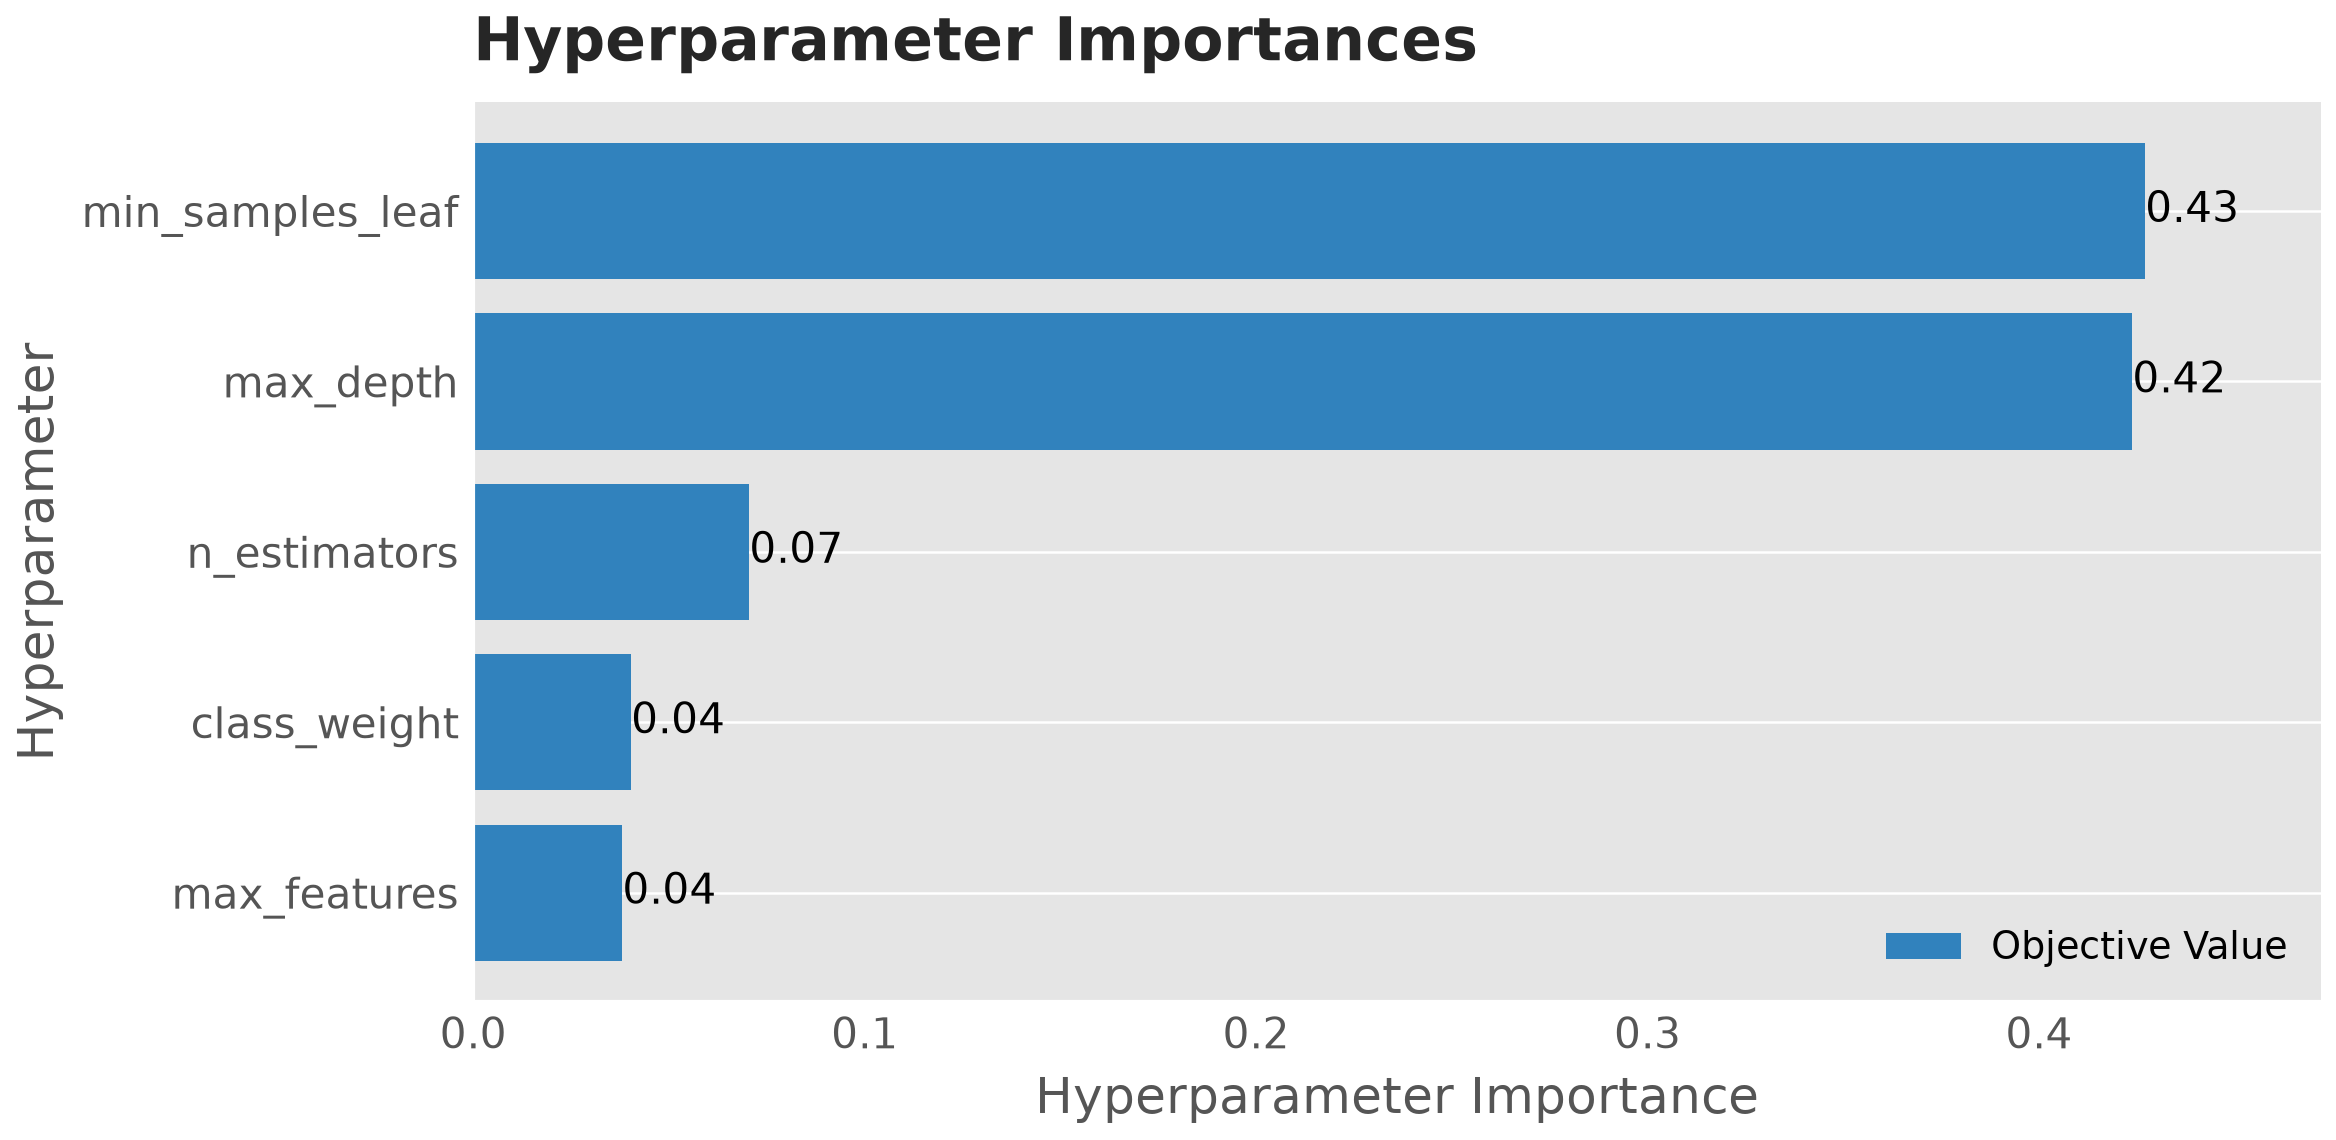

**Рисунок 6. RF: важливість гіперпараметрів Optuna**

RF: найважливіший параметр за fANOVA - min_samples_leaf; приріст найкращого значення за останні 10 trials = 0.0000. Плато є емпіричною ознакою стабілізації лише в межах цього бюджету, а не доказом глобального оптимуму. Важливість залежить від заданого діапазону та лише 30 спроб.

/tmp/ipykernel_138/1734775700.py:56: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax=optuna.visualization.matplotlib.plot_optimization_history(studies[name])


На рисунку 7 показано xgb: історія оптимізації macro f1.

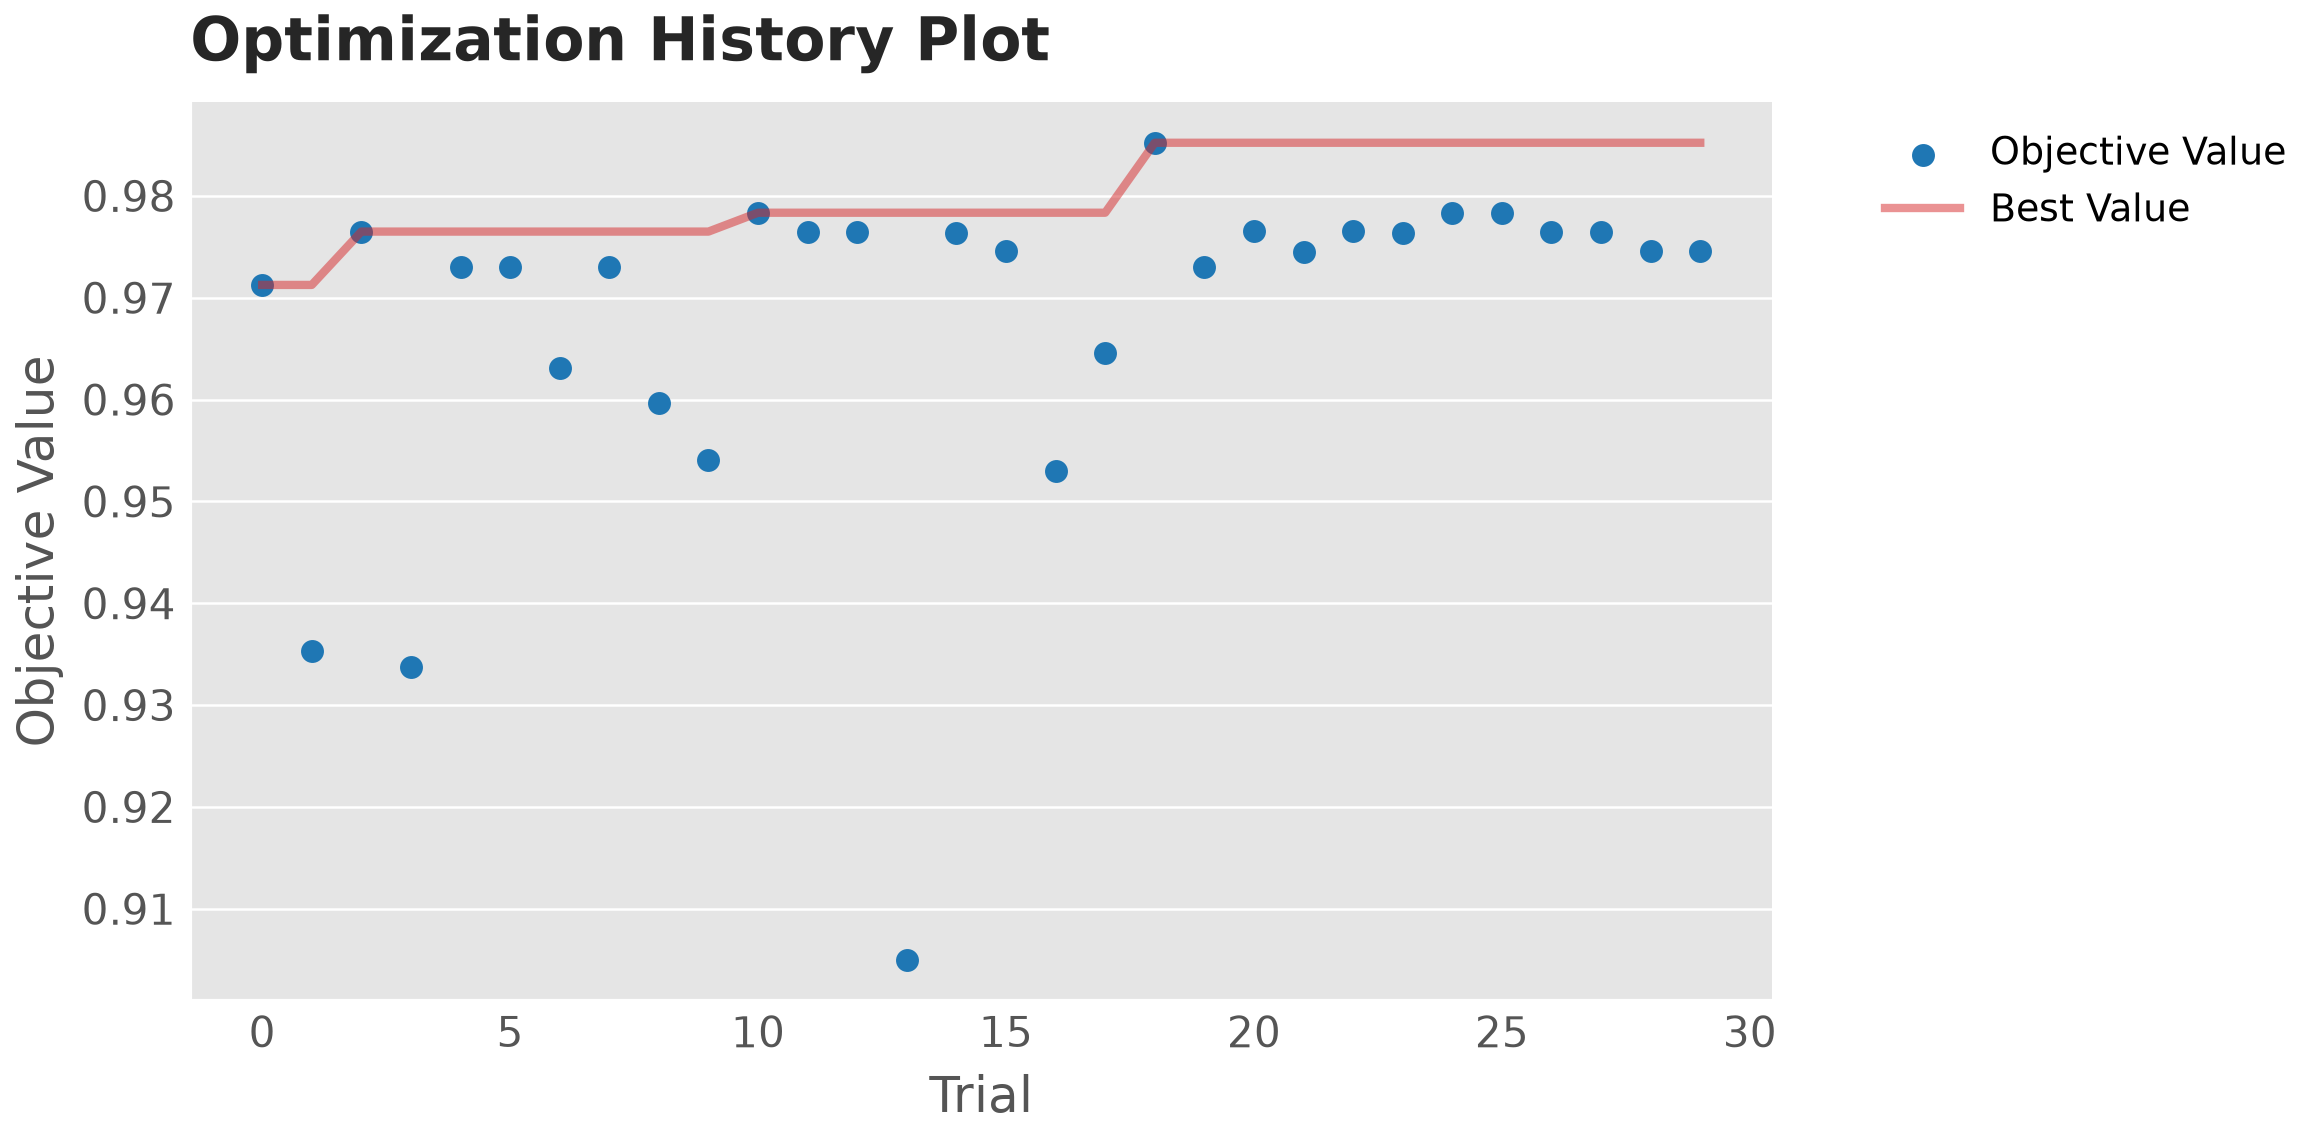

**Рисунок 7. XGB: історія оптимізації macro F1**

/tmp/ipykernel_138/1734775700.py:59: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax=optuna.visualization.matplotlib.plot_param_importances(studies[name],evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED))


На рисунку 8 показано xgb: важливість гіперпараметрів optuna.

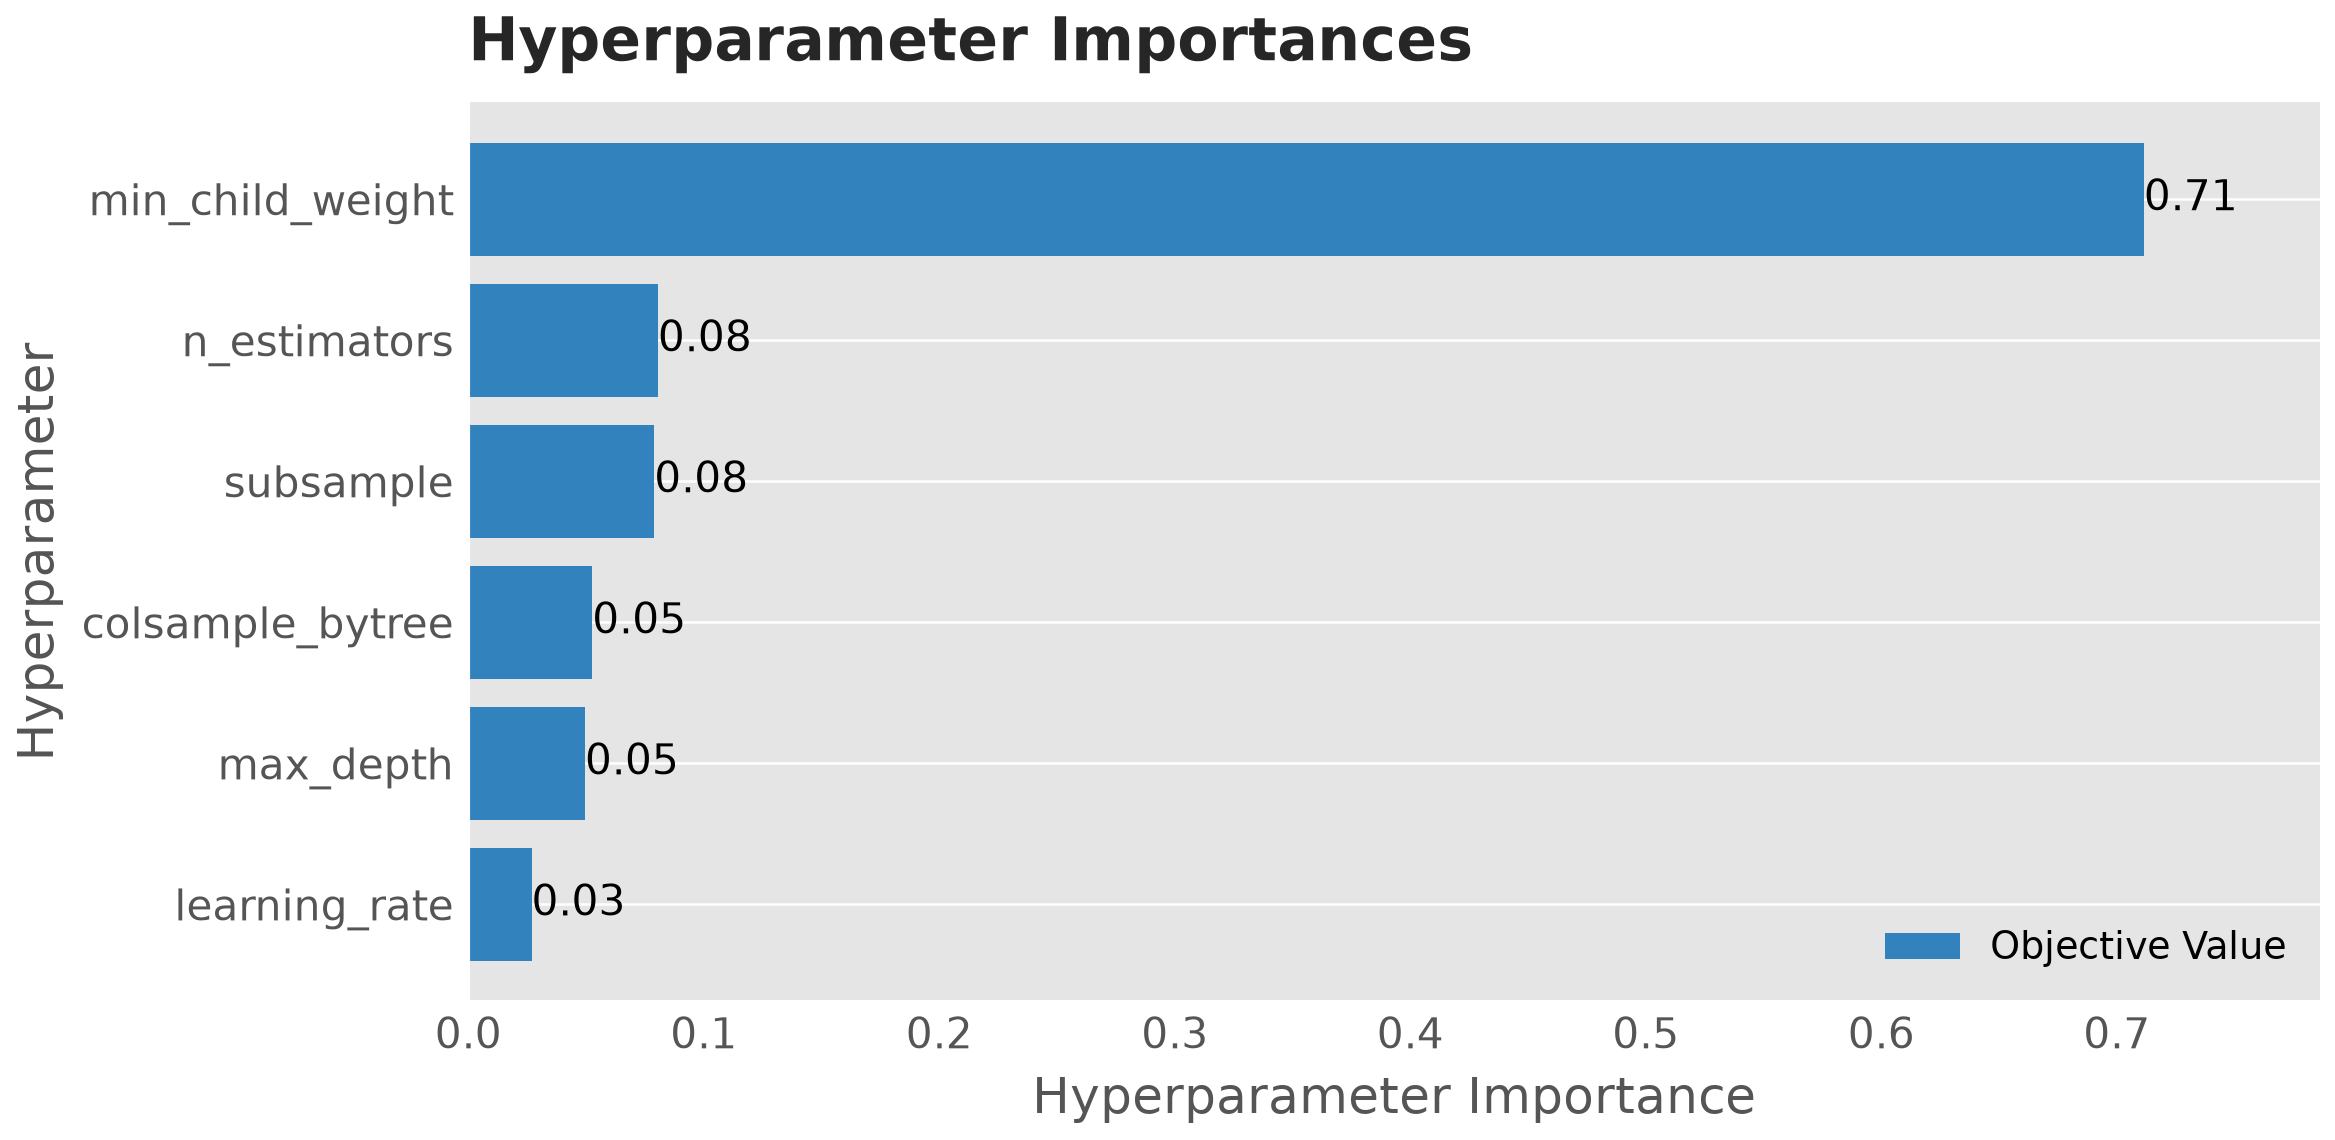

**Рисунок 8. XGB: важливість гіперпараметрів Optuna**

XGB: найважливіший параметр за fANOVA - min_child_weight; приріст найкращого значення за останні 10 trials = 0.0000. Плато є емпіричною ознакою стабілізації лише в межах цього бюджету, а не доказом глобального оптимуму. Важливість залежить від заданого діапазону та лише 30 спроб.

In [4]:
def suggest_params(trial,name):
 if name=='DT':
  return {'max_depth':trial.suggest_int('max_depth',2,20),
   'min_samples_split':trial.suggest_int('min_samples_split',2,20),
   'min_samples_leaf':trial.suggest_int('min_samples_leaf',1,10),
   'class_weight':trial.suggest_categorical('class_weight',[None,'balanced'])}
 if name=='RF':
  return {'n_estimators':trial.suggest_int('n_estimators',100,500,step=50),
   'max_depth':trial.suggest_int('max_depth',3,30),
   'min_samples_leaf':trial.suggest_int('min_samples_leaf',1,10),
   'max_features':trial.suggest_categorical('max_features',['sqrt','log2',.5]),
   'class_weight':trial.suggest_categorical('class_weight',[None,'balanced','balanced_subsample'])}
 return {'n_estimators':trial.suggest_int('n_estimators',50,400),
  'max_depth':trial.suggest_int('max_depth',2,10),
  'learning_rate':trial.suggest_float('learning_rate',.01,.3,log=True),
  'subsample':trial.suggest_float('subsample',.6,1.),
  'colsample_bytree':trial.suggest_float('colsample_bytree',.6,1.),
  'min_child_weight':trial.suggest_float('min_child_weight',1,10,log=True)}
def tune(name,xx,yy):
 inner=list(StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED).split(xx,yy))
 def objective(trial):
  return cross_val_score(build_pipeline(name,True,suggest_params(trial,name)),xx,yy,
      cv=inner,scoring='f1_macro',error_score='raise',n_jobs=3).mean()
 study=optuna.create_study(direction='maximize',sampler=optuna.samplers.TPESampler(seed=SEED))
 study.optimize(objective,n_trials=N_TRIALS)
 return study
nested={}; studies={}; final={}; timings={}; nested_studies={}
for name in NAMES:
 start=time.perf_counter(); scores=[]
 for i,(tr,va) in enumerate(outer):
  print('Nested',name,i+1,flush=True)
  checkpoint=RESULT/f'study_{name}_outer_{i}.joblib'
  study=joblib.load(checkpoint) if RESUME and checkpoint.exists() else tune(name,X_train.iloc[tr],y_train[tr])
  assert len(study.trials)==N_TRIALS
  pipe=build_pipeline(name,True,study.best_params).fit(X_train.iloc[tr],y_train[tr])
  scores.append(f1_score(y_train[va],pipe.predict(X_train.iloc[va]),average='macro'))
  nested_studies[name,i]=study
  joblib.dump(study,RESULT/f'study_{name}_outer_{i}.joblib',compress=3)
 nested[name]=np.array(scores)
 print('Final tune',name,flush=True)
 checkpoint=RESULT/f'study_{name}_final.joblib'
 studies[name]=joblib.load(checkpoint) if RESUME and checkpoint.exists() else tune(name,X_train,y_train)
 final[name]=build_pipeline(name,True,studies[name].best_params).fit(X_train,y_train)
 timings[name]=time.perf_counter()-start
 joblib.dump(studies[name],RESULT/f'study_{name}_final.joblib',compress=3)
 joblib.dump(final[name],RESULT/f'model_{name}.joblib',compress=3)
 joblib.dump({'nested':nested,'timings':timings},RESULT/'nested_checkpoint.joblib',compress=3)
summary=pd.DataFrame([{'модель':n,'nested mean':nested[n].mean(),'nested SD':nested[n].std(ddof=1),
 'best_value':studies[n].best_value,'best - nested':studies[n].best_value-nested[n].mean(),
 'секунд поточного виконання':timings[n]} for n in NAMES]).set_index('модель')
table(3,'Вкладена CV і звичайна оптимізація',summary)
table(4,'Найкращі гіперпараметри фінальних моделей',pd.DataFrame({n:studies[n].best_params for n in NAMES}).T.fillna('не застосовується / None'))
best_nested=summary['nested mean'].idxmax()
note(f'За nested CV обрано {best_nested}: {summary.loc[best_nested,"nested mean"]:.4f} ± {summary.loc[best_nested,"nested SD"]:.4f}. Різниця best_value - nested для неї = {summary.loc[best_nested,"best - nested"]:+.4f}. Ці оцінки отримані на різних навчальних обсягах і блоках: знак різниці в окремому експерименті не гарантований. Максимум внутрішньої CV не є незалежною оцінкою узагальнення.')
for name in NAMES:
 ax=optuna.visualization.matplotlib.plot_optimization_history(studies[name])
 ax.figure.set_size_inches(8,4)
 showfig(ax.figure,f'{name}: історія оптимізації macro F1')
 ax=optuna.visualization.matplotlib.plot_param_importances(studies[name],evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED))
 ax.figure.set_size_inches(8,4)
 showfig(ax.figure,f'{name}: важливість гіперпараметрів Optuna')
 imp=optuna.importance.get_param_importances(studies[name],evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED))
 vals=np.maximum.accumulate([z.value for z in studies[name].trials])
 note(f'{name}: найважливіший параметр за fANOVA - {next(iter(imp))}; приріст найкращого значення за останні 10 trials = {vals[-1]-vals[-11]:.4f}. Плато є емпіричною ознакою стабілізації лише в межах цього бюджету, а не доказом глобального оптимуму. Важливість залежить від заданого діапазону та лише 30 спроб.')


## 4. Скоригований тест Наде-Бенжіо
Для різниць macro F1 використовуємо вибіркову дисперсію з ddof=1, множник `1/(k*r) + mean(n_valid/n_train)` і df = k*r - 1. Двобічне p обчислюється через scipy.stats.t. Для A/B напрям різниці - B мінус A; для моделей - перша мінус друга. Поріг 0,05 задано методичкою; чотири перевірки без поправки на множинність є розвідувальними. Невідхилення H0 не доводить еквівалентність моделей. Перевірка двох найкращих після їх вибору також має селекційне обмеження.


In [5]:
def corrected_test(a,b,splits):
 d=np.asarray(a)-np.asarray(b)
 variance=d.var(ddof=1)
 ratio=np.mean([len(va)/len(tr) for tr,va in splits])
 se=np.sqrt(variance*(1/len(d)+ratio))
 if se==0:
  stat=0. if d.mean()==0 else np.sign(d.mean())*np.inf
 else:
  stat=d.mean()/se
 p=float(2*t.sf(abs(stat),df=len(d)-1))
 return {'d_mean':d.mean(),'t':stat,'p':p,'df':len(d)-1,
         'висновок':'значуща різниця' if p<.05 else 'не виявлено значущої різниці'}
stats_rows=[]
for n in NAMES:
 stats_rows.append({'порівняння':n+' B - A',**corrected_test(base['B',n]['test_f1m'],base['A',n]['test_f1m'],folds)})
rank=sorted(NAMES,key=lambda n:base['B',n]['test_f1m'].mean(),reverse=True)
stats_rows.append({'порівняння':f'{rank[0]} - {rank[1]} (B)',**corrected_test(base['B',rank[0]]['test_f1m'],base['B',rank[1]]['test_f1m'],folds)})
stats_df=pd.DataFrame(stats_rows).set_index('порівняння')
table(5,'Статистичні порівняння базових моделей',stats_df)
note('Для двох найкращих базових B-моделей: '+stats_df.iloc[-1]['висновок']+f', p={stats_df.iloc[-1]["p"]:.4g}. Цей тест стосується базових моделей; він не встановлює значущість переваги оптимізованого переможця nested CV.')


У таблиці 5 наведено статистичні порівняння базових моделей.

**Таблиця 5. Статистичні порівняння базових моделей**

,d_mean,t,p,df,висновок
порівняння,,,,,
DT B - A,0.065278,4.593588,0.000418,14,значуща різниця
RF B - A,0.070997,4.468927,0.000530,14,значуща різниця
XGB B - A,0.062370,5.049742,0.000177,14,значуща різниця
RF - DT (B),0.001748,0.641331,0.531667,14,не виявлено значущої різниці


Для двох найкращих базових B-моделей: не виявлено значущої різниці, p=0.5317. Цей тест стосується базових моделей; він не встановлює значущість переваги оптимізованого переможця nested CV.

## 5. Одноразове фінальне test-оцінювання
Нижче для кожної фінальної моделі один раз отримуються test-прогнози та ймовірності. Після цього test використовується лише для оцінки й інтерпретації, без зміни параметрів. «Найкраща» означає обрану раніше за nested CV, а не максимум test.


У таблиці 6 наведено фінальна якість на test.

**Таблиця 6. Фінальна якість на test**

,accuracy,macro F1,balanced accuracy
модель,,,
DT,0.988764,0.970384,0.99635
RF,0.983146,0.953135,0.96510
XGB,0.983146,0.953135,0.96510


,precision,recall,f1-score,support
2,1.000000,1.000000,1.000000,20.000000
3,0.992647,0.985401,0.989011,137.000000
5,1.000000,1.000000,1.000000,13.000000
U,0.777778,0.875000,0.823529,8.000000
accuracy,0.983146,0.983146,0.983146,0.983146
macro avg,0.942606,0.965100,0.953135,178.000000
weighted avg,0.984353,0.983146,0.983611,178.000000


На рисунку 9 показано rf: абсолютна матриця плутанини.

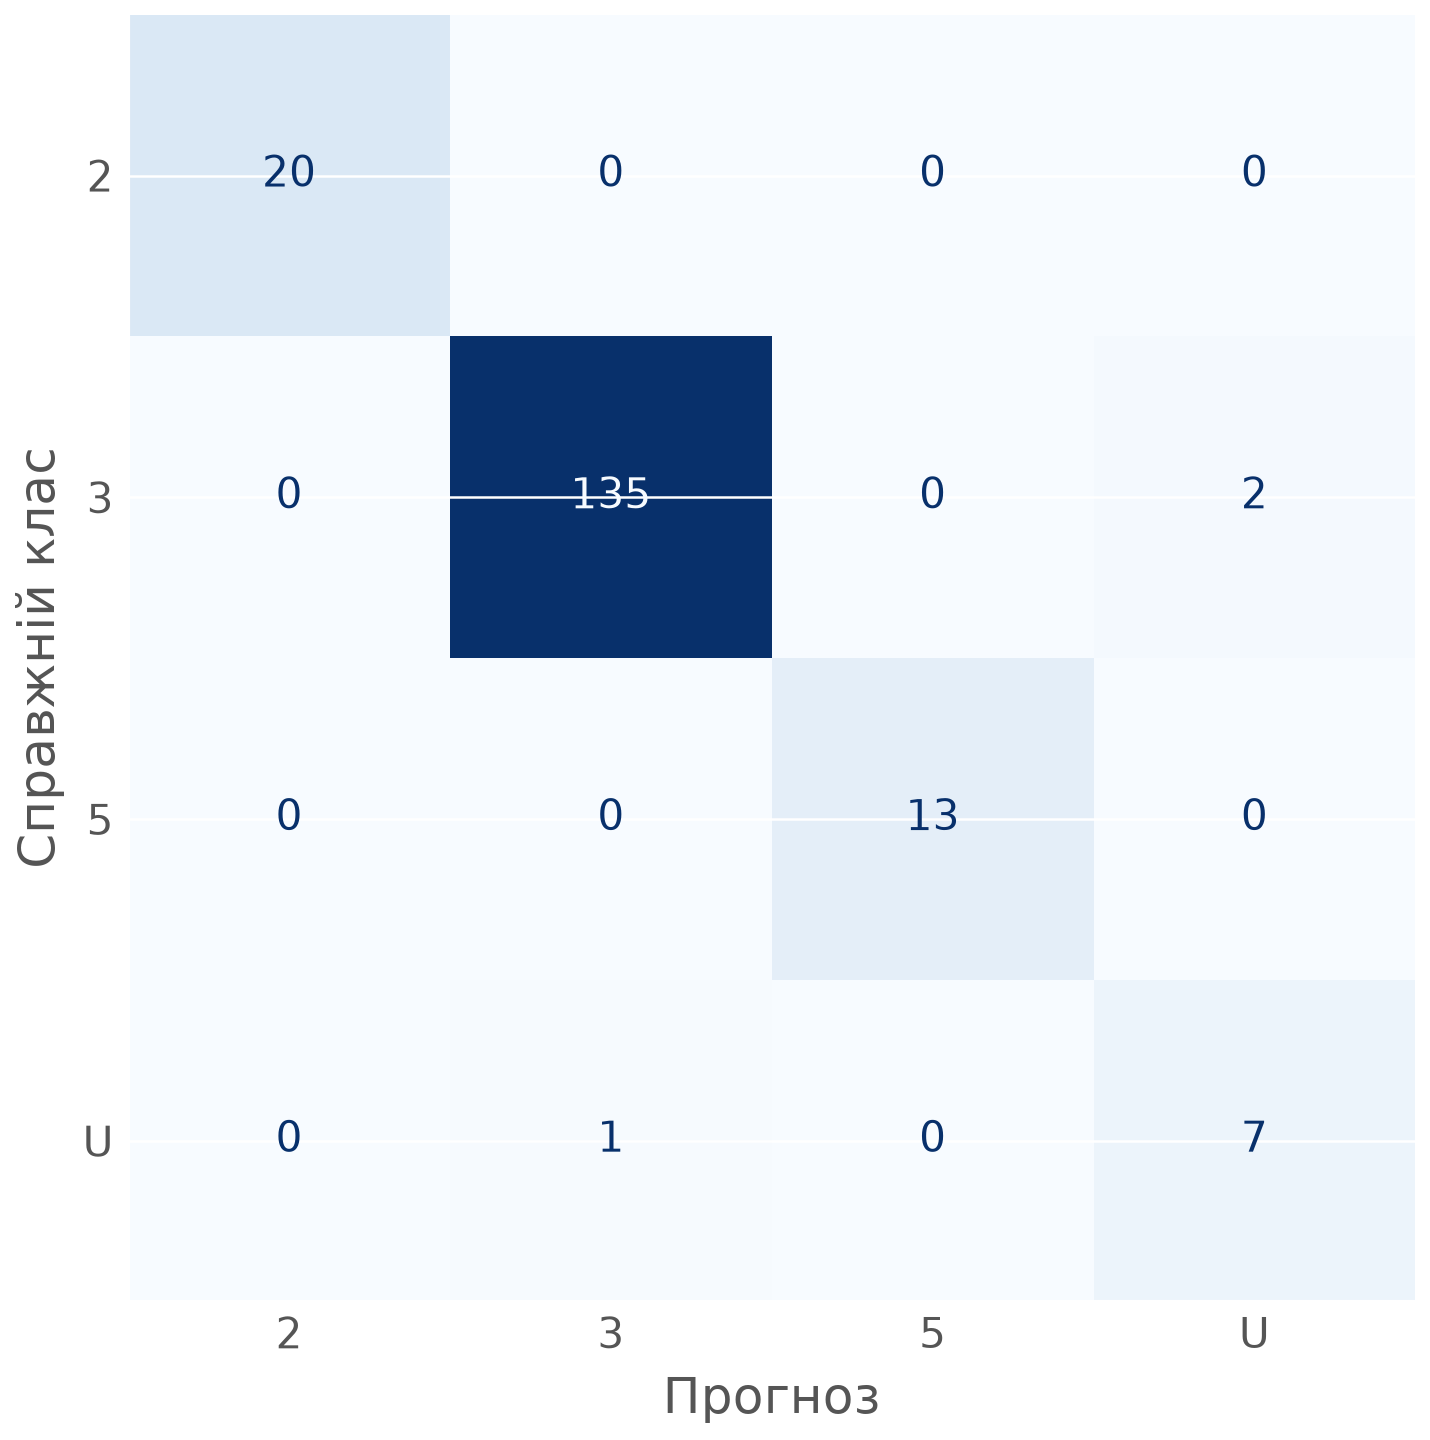

**Рисунок 9. RF: абсолютна матриця плутанини**

На рисунку 10 показано rf: нормалізована по рядках матриця плутанини.

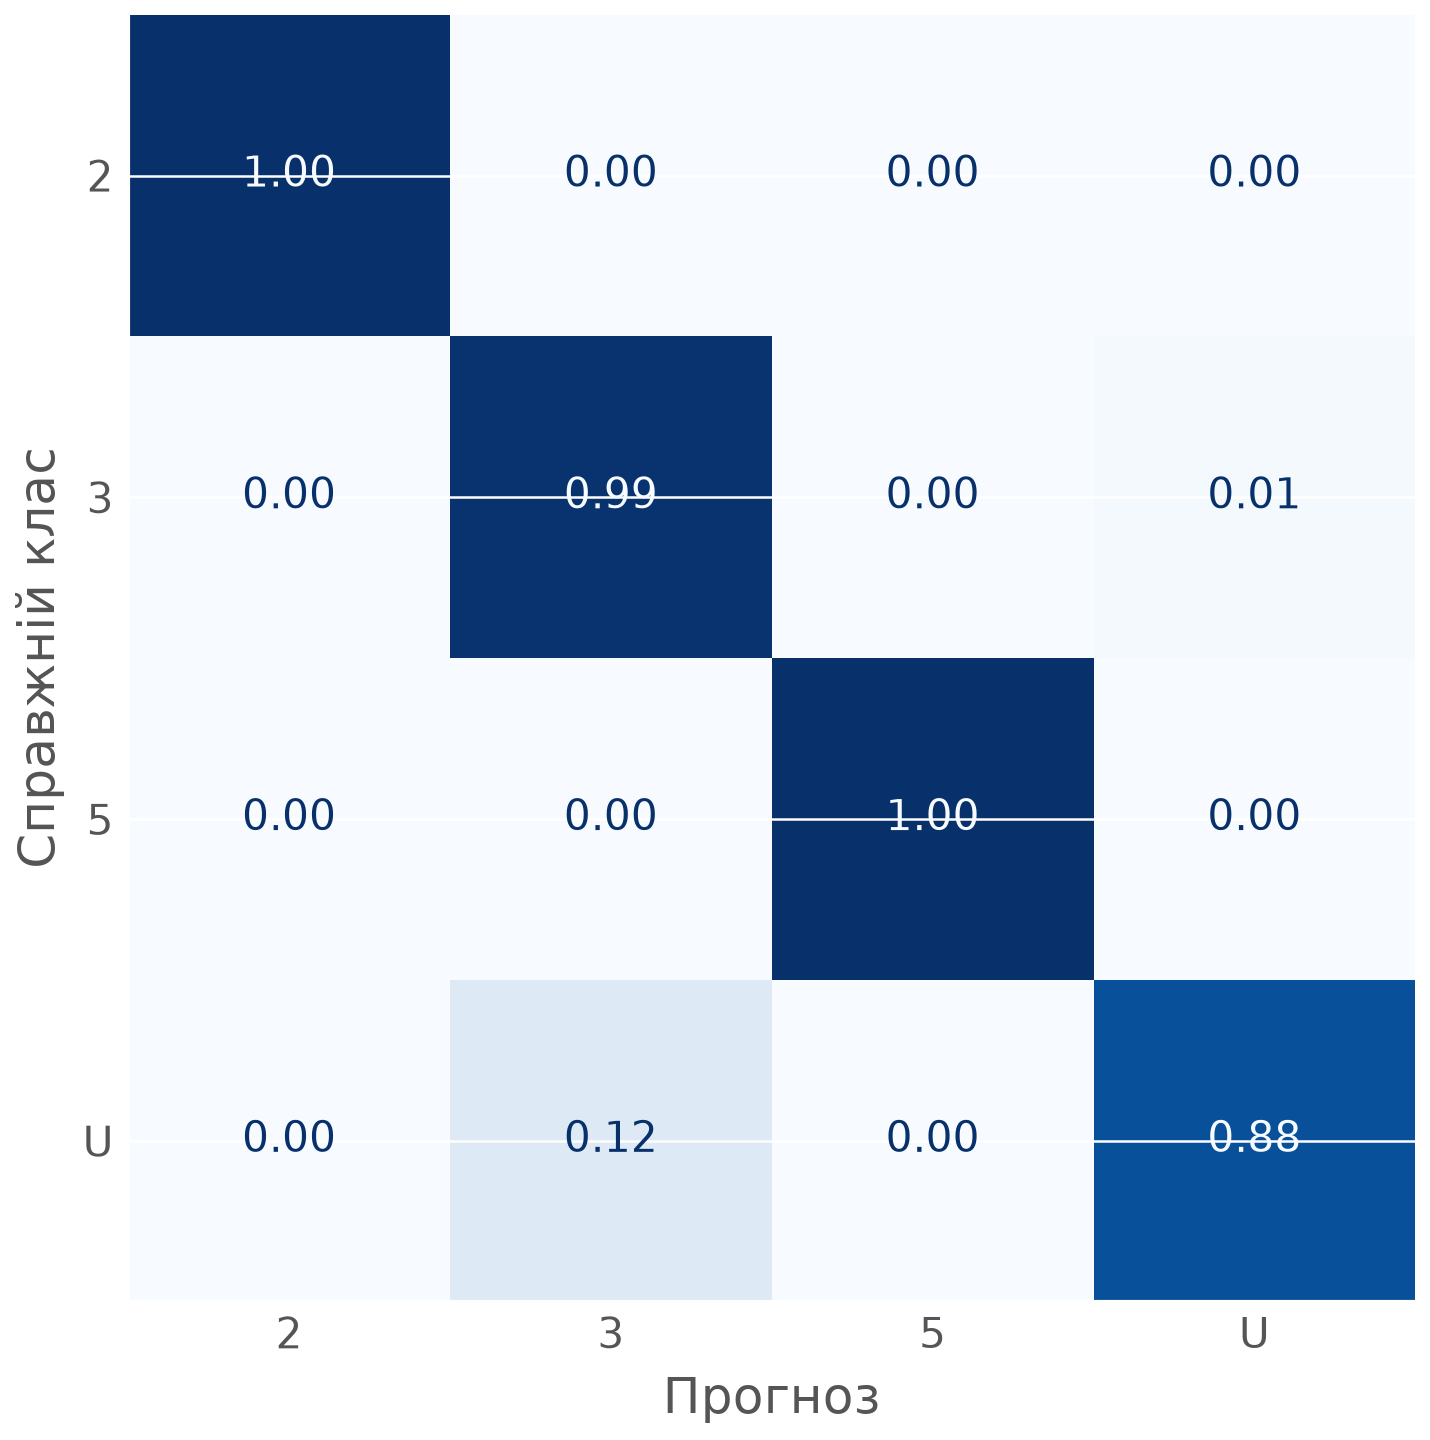

**Рисунок 10. RF: нормалізована по рядках матриця плутанини**

Test macro F1 обраної моделі = 0.9531, nested = 0.9934. Найчастіше помилкове спрямування: клас 3 → U, 2 об’єктів.

Кількості класів у test: {'2': 20, '3': 137, '5': 13, 'U': 8}. Для малих класів одна помилка помітно змінює recall та macro F1. Test є одним розбиттям, CV усереднює різні блоки, а фінальна модель навчається на більшій кількості об’єктів, ніж модель кожного CV-блоку.

In [6]:
preds={n:final[n].predict(X_test) for n in NAMES}
probs={n:final[n].predict_proba(X_test) for n in NAMES}
test_df=pd.DataFrame([{'модель':n,'accuracy':accuracy_score(y_test,preds[n]),
 'macro F1':f1_score(y_test,preds[n],average='macro'),
 'balanced accuracy':balanced_accuracy_score(y_test,preds[n])} for n in NAMES]).set_index('модель')
table(6,'Фінальна якість на test',test_df)
report=classification_report(y_test,preds[best_nested],target_names=encoder.classes_,output_dict=True,zero_division=0)
display(pd.DataFrame(report).T)
pd.DataFrame(report).T.to_csv(RESULT/'classification_report.csv')
cm=confusion_matrix(y_test,preds[best_nested])
for normalize in [False,True]:
 mat=cm/cm.sum(axis=1,keepdims=True) if normalize else cm
 fig,ax=plt.subplots(figsize=(6,5))
 ConfusionMatrixDisplay(mat,display_labels=encoder.classes_).plot(ax=ax,cmap='Blues',colorbar=False,
   values_format='.2f' if normalize else 'd')
 ax.set_xlabel('Прогноз'); ax.set_ylabel('Справжній клас')
 showfig(fig,f'{best_nested}: '+('нормалізована по рядках' if normalize else 'абсолютна')+' матриця плутанини')
errors=cm.copy(); np.fill_diagonal(errors,0)
i,j=np.unravel_index(errors.argmax(),errors.shape)
note(f'Test macro F1 обраної моделі = {test_df.loc[best_nested,"macro F1"]:.4f}, nested = {nested[best_nested].mean():.4f}. Найчастіше помилкове спрямування: клас {encoder.classes_[i]} → {encoder.classes_[j]}, {errors[i,j]} об’єктів.' if errors.max() else 'Обрана модель не припустилася помилок на цьому test; це не гарантує безпомилковість на нових даних.')
note(f'Кількості класів у test: {dict(zip(encoder.classes_,np.bincount(y_test).tolist()))}. Для малих класів одна помилка помітно змінює recall та macro F1. Test є одним розбиттям, CV усереднює різні блоки, а фінальна модель навчається на більшій кількості об’єктів, ніж модель кожного CV-блоку.')


## 6. Глобальні важливості ознак
MDI вимірюється в просторі після обробки; permutation importance застосовується до всього Pipeline та початкових колонок test, 10 повторень, scoring=f1_macro. Top-15 можуть включати нульові значення. Permutation importance є падінням метрики; від’ємне значення означає покращення після перемішування, а не автоматично «шкідливу» ознаку. Групування one-hot колонок у MDI та початкових колонок у permutation відрізняється, тому їхні значення не порівнюються безпосередньо.


На рисунку 11 показано dt: top-15 mdi.

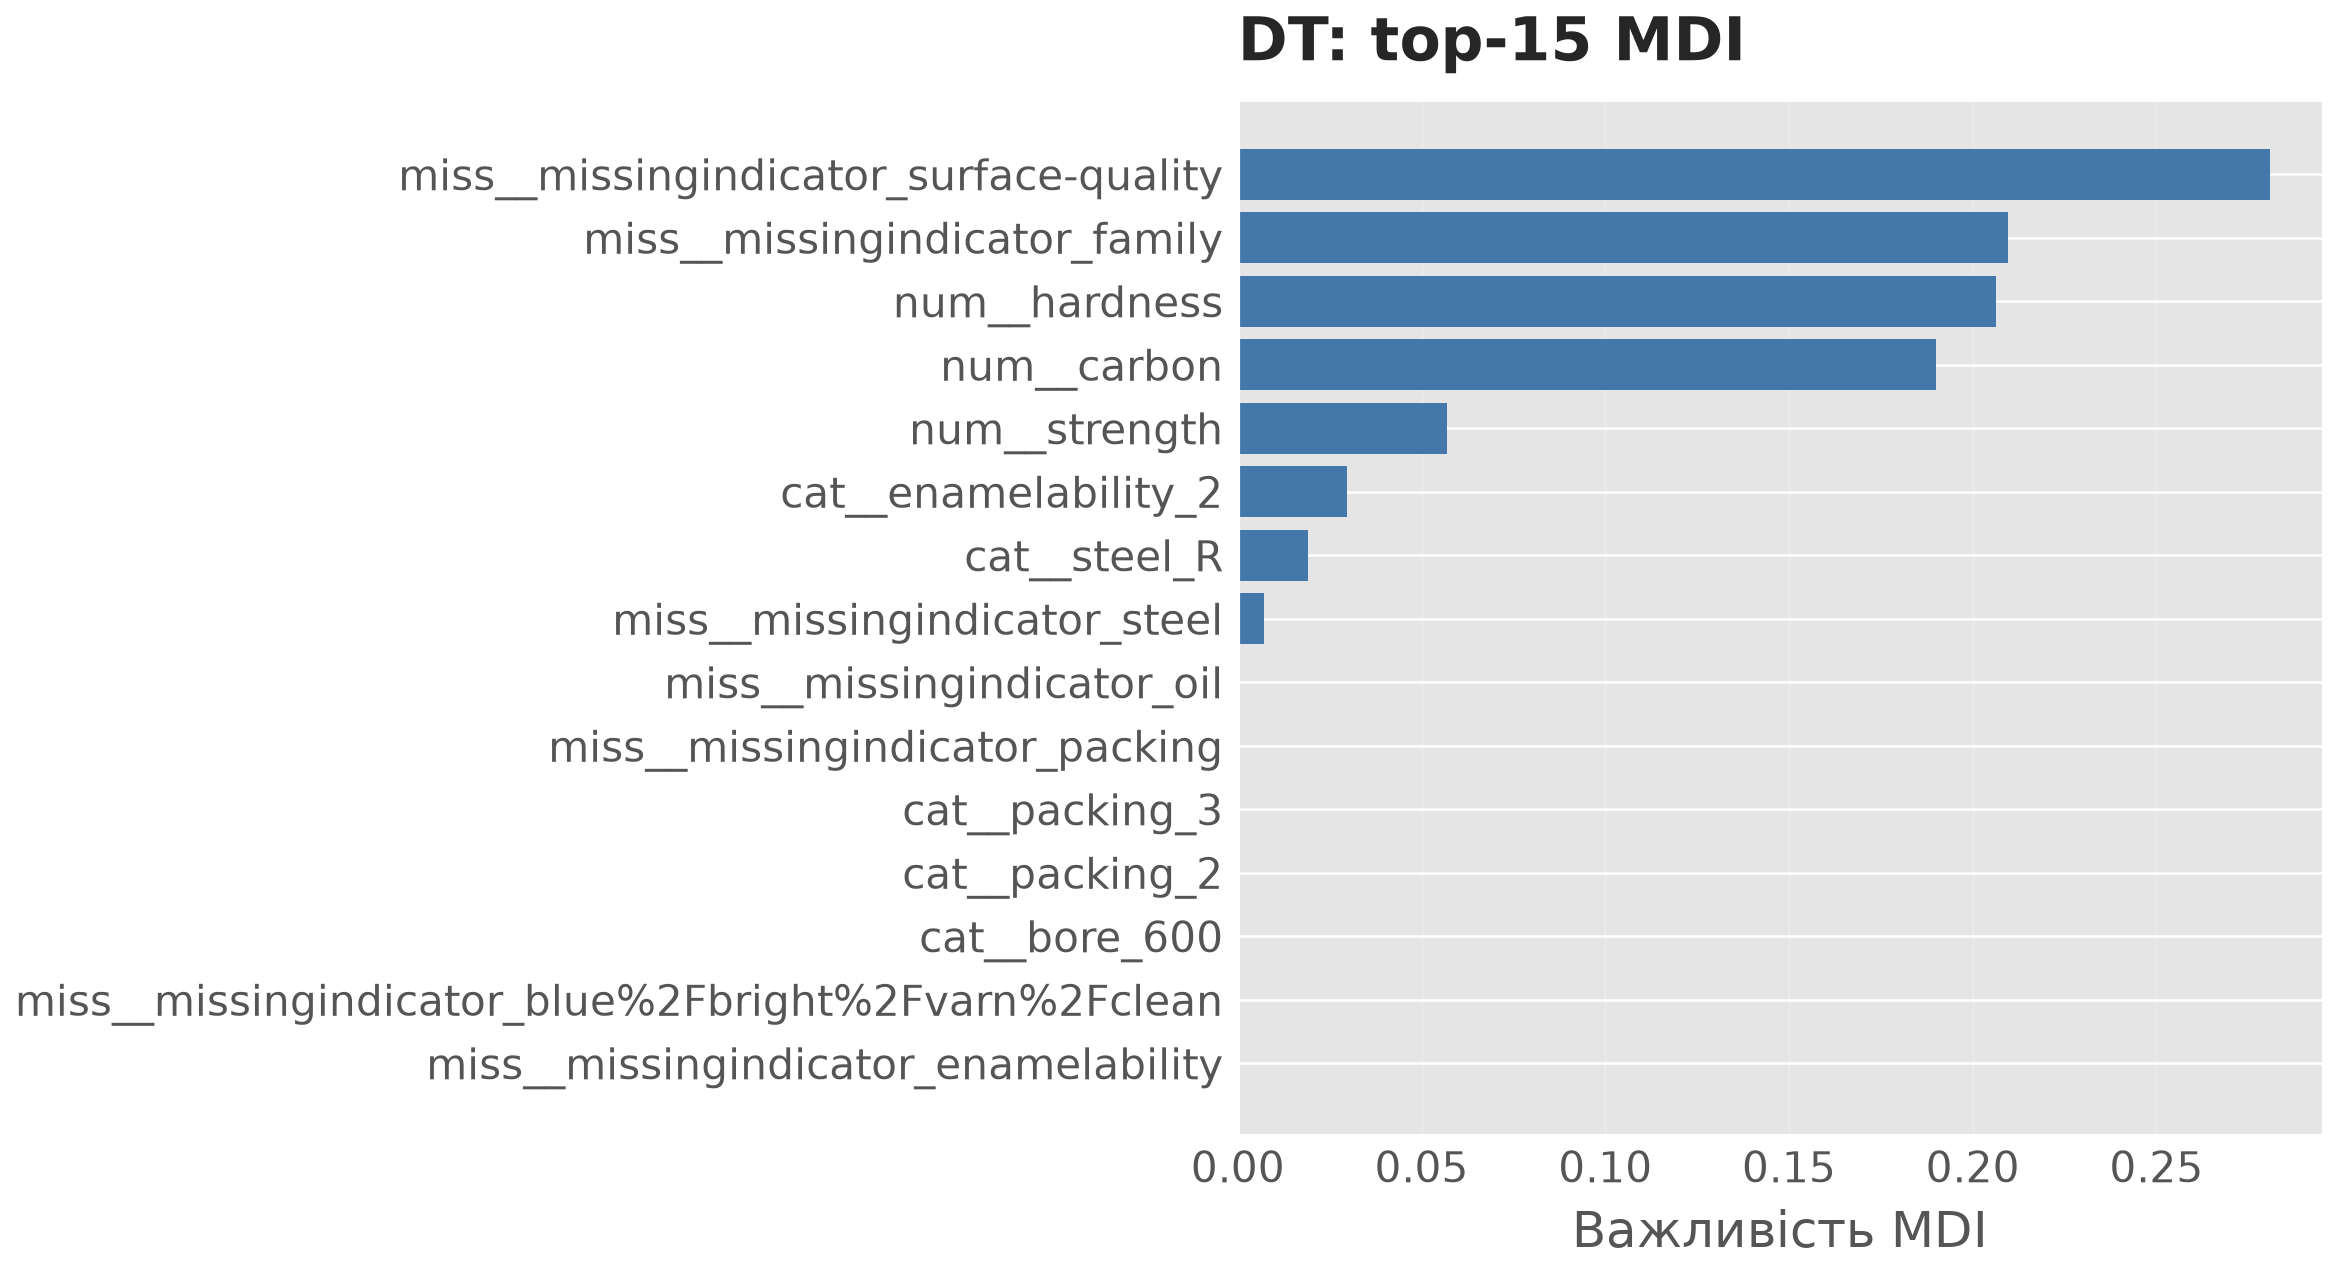

**Рисунок 11. DT: top-15 MDI**

На рисунку 12 показано dt: top-15 permutation importance.

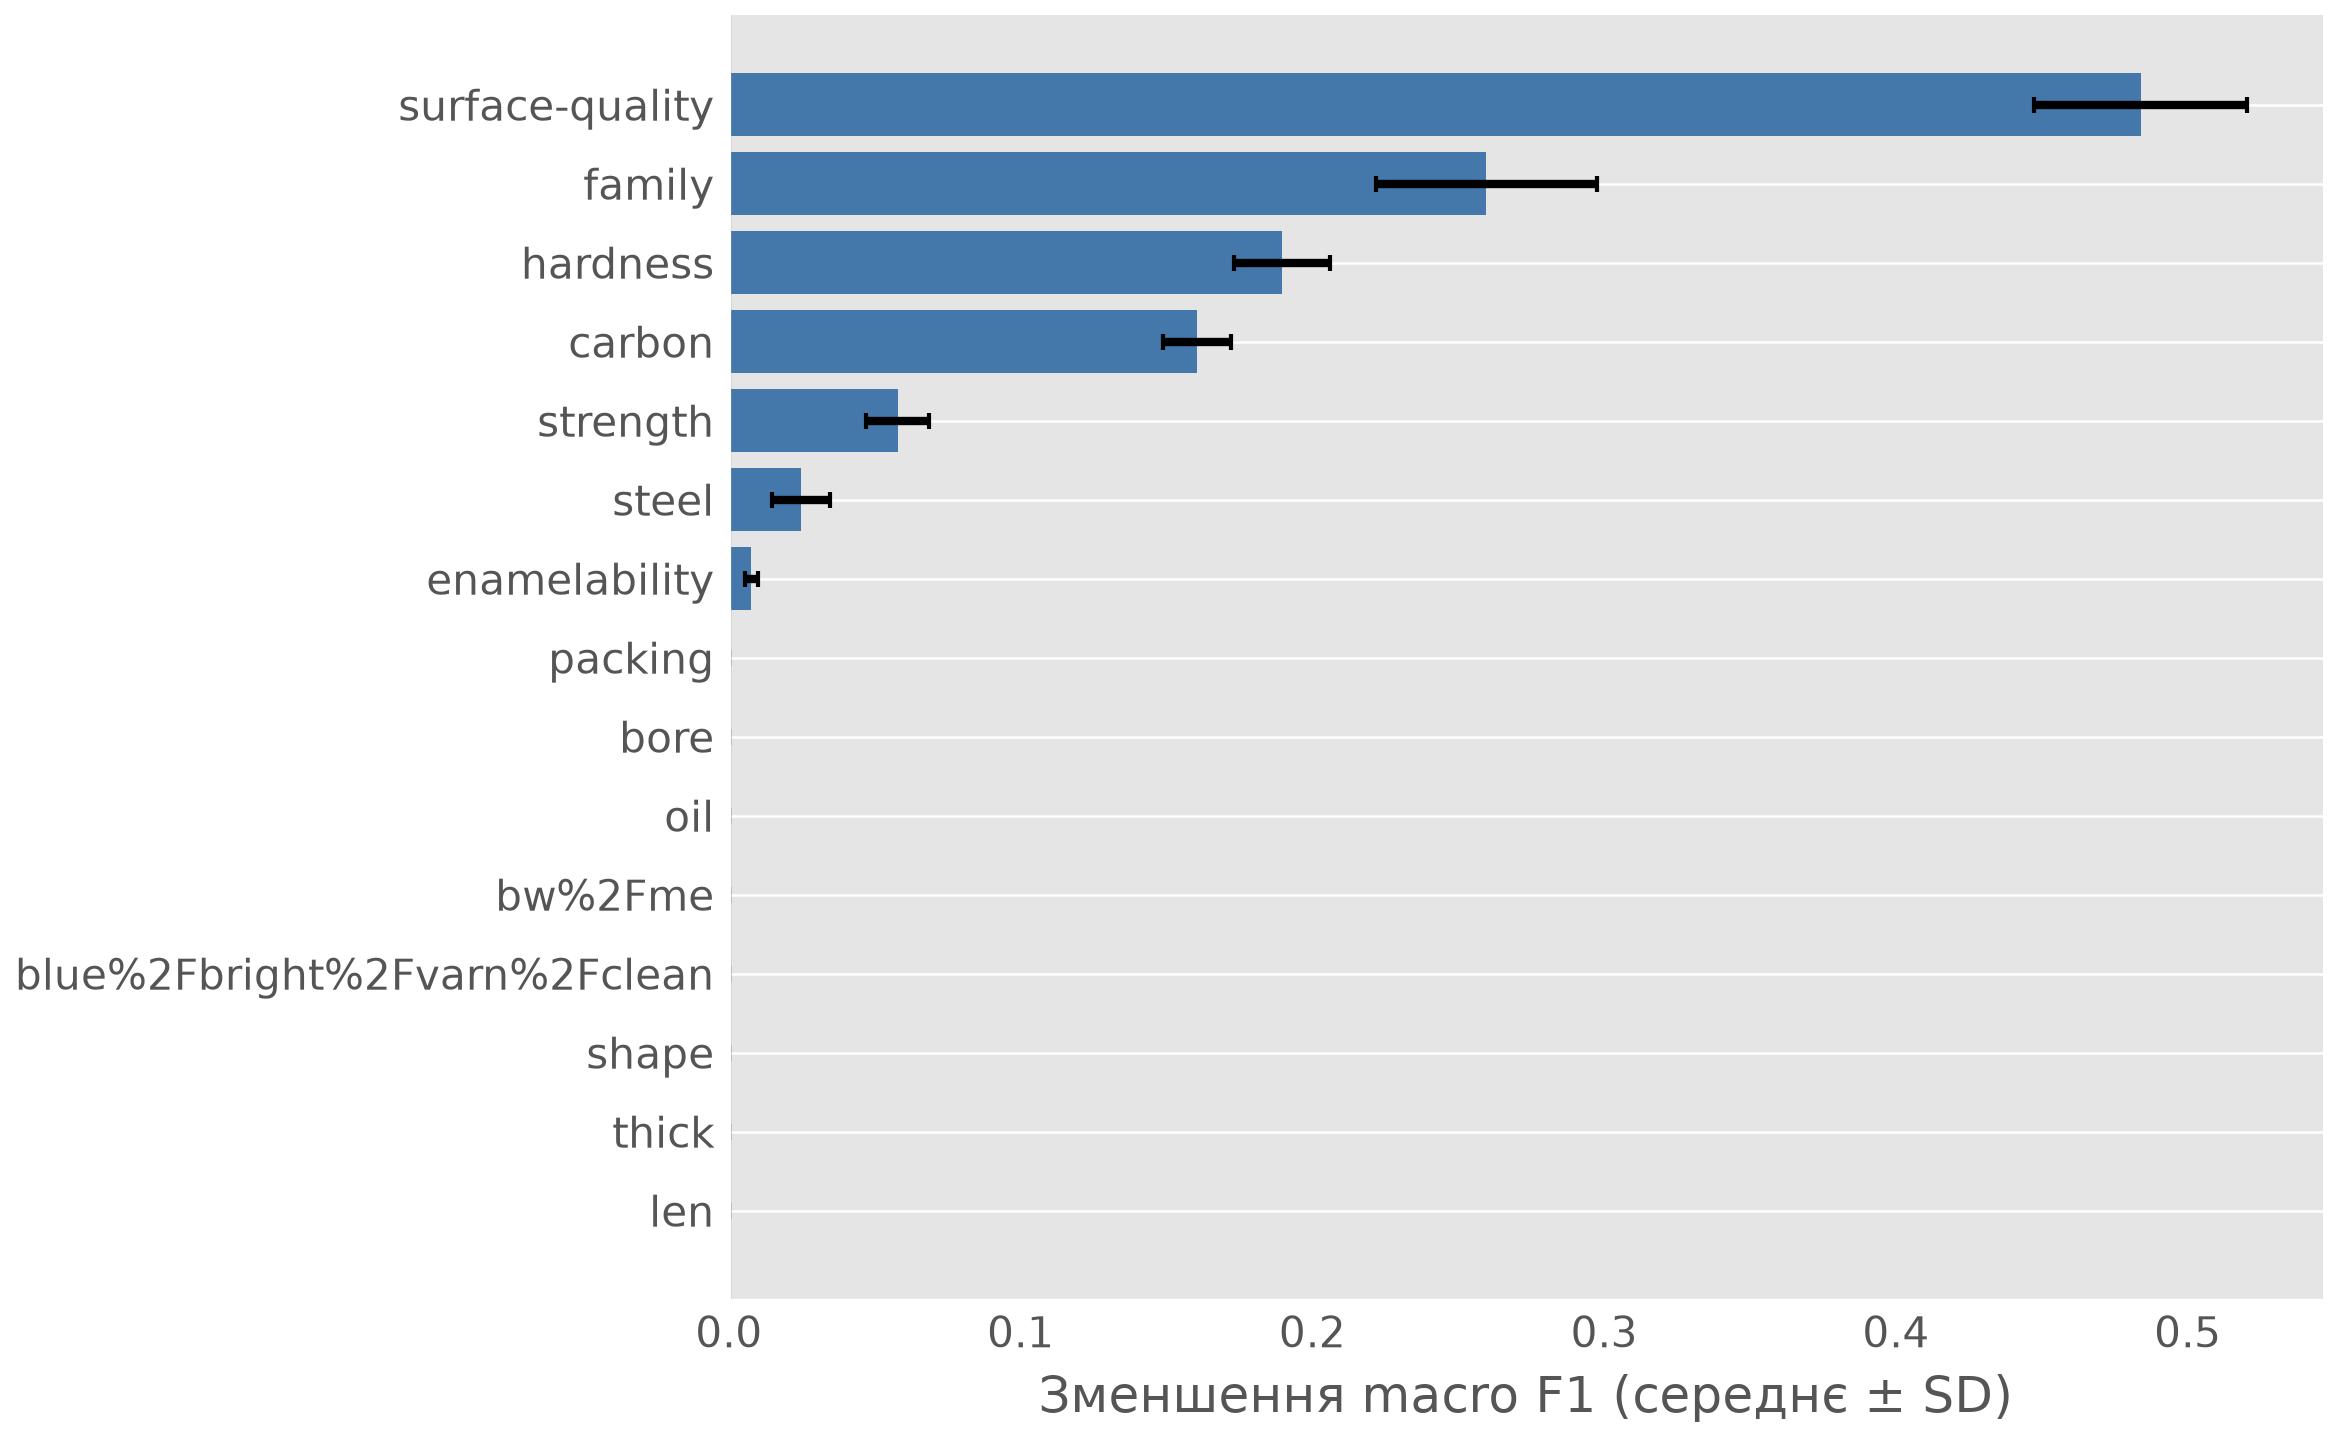

**Рисунок 12. DT: top-15 permutation importance**

DT: індикатори серед top-15 MDI: ['miss__missingindicator_surface-quality', 'miss__missingindicator_family', 'miss__missingindicator_steel']. Найважливіша оброблена ознака - miss__missingindicator_surface-quality, початкова за permutation - surface-quality.

На рисунку 13 показано rf: top-15 mdi.

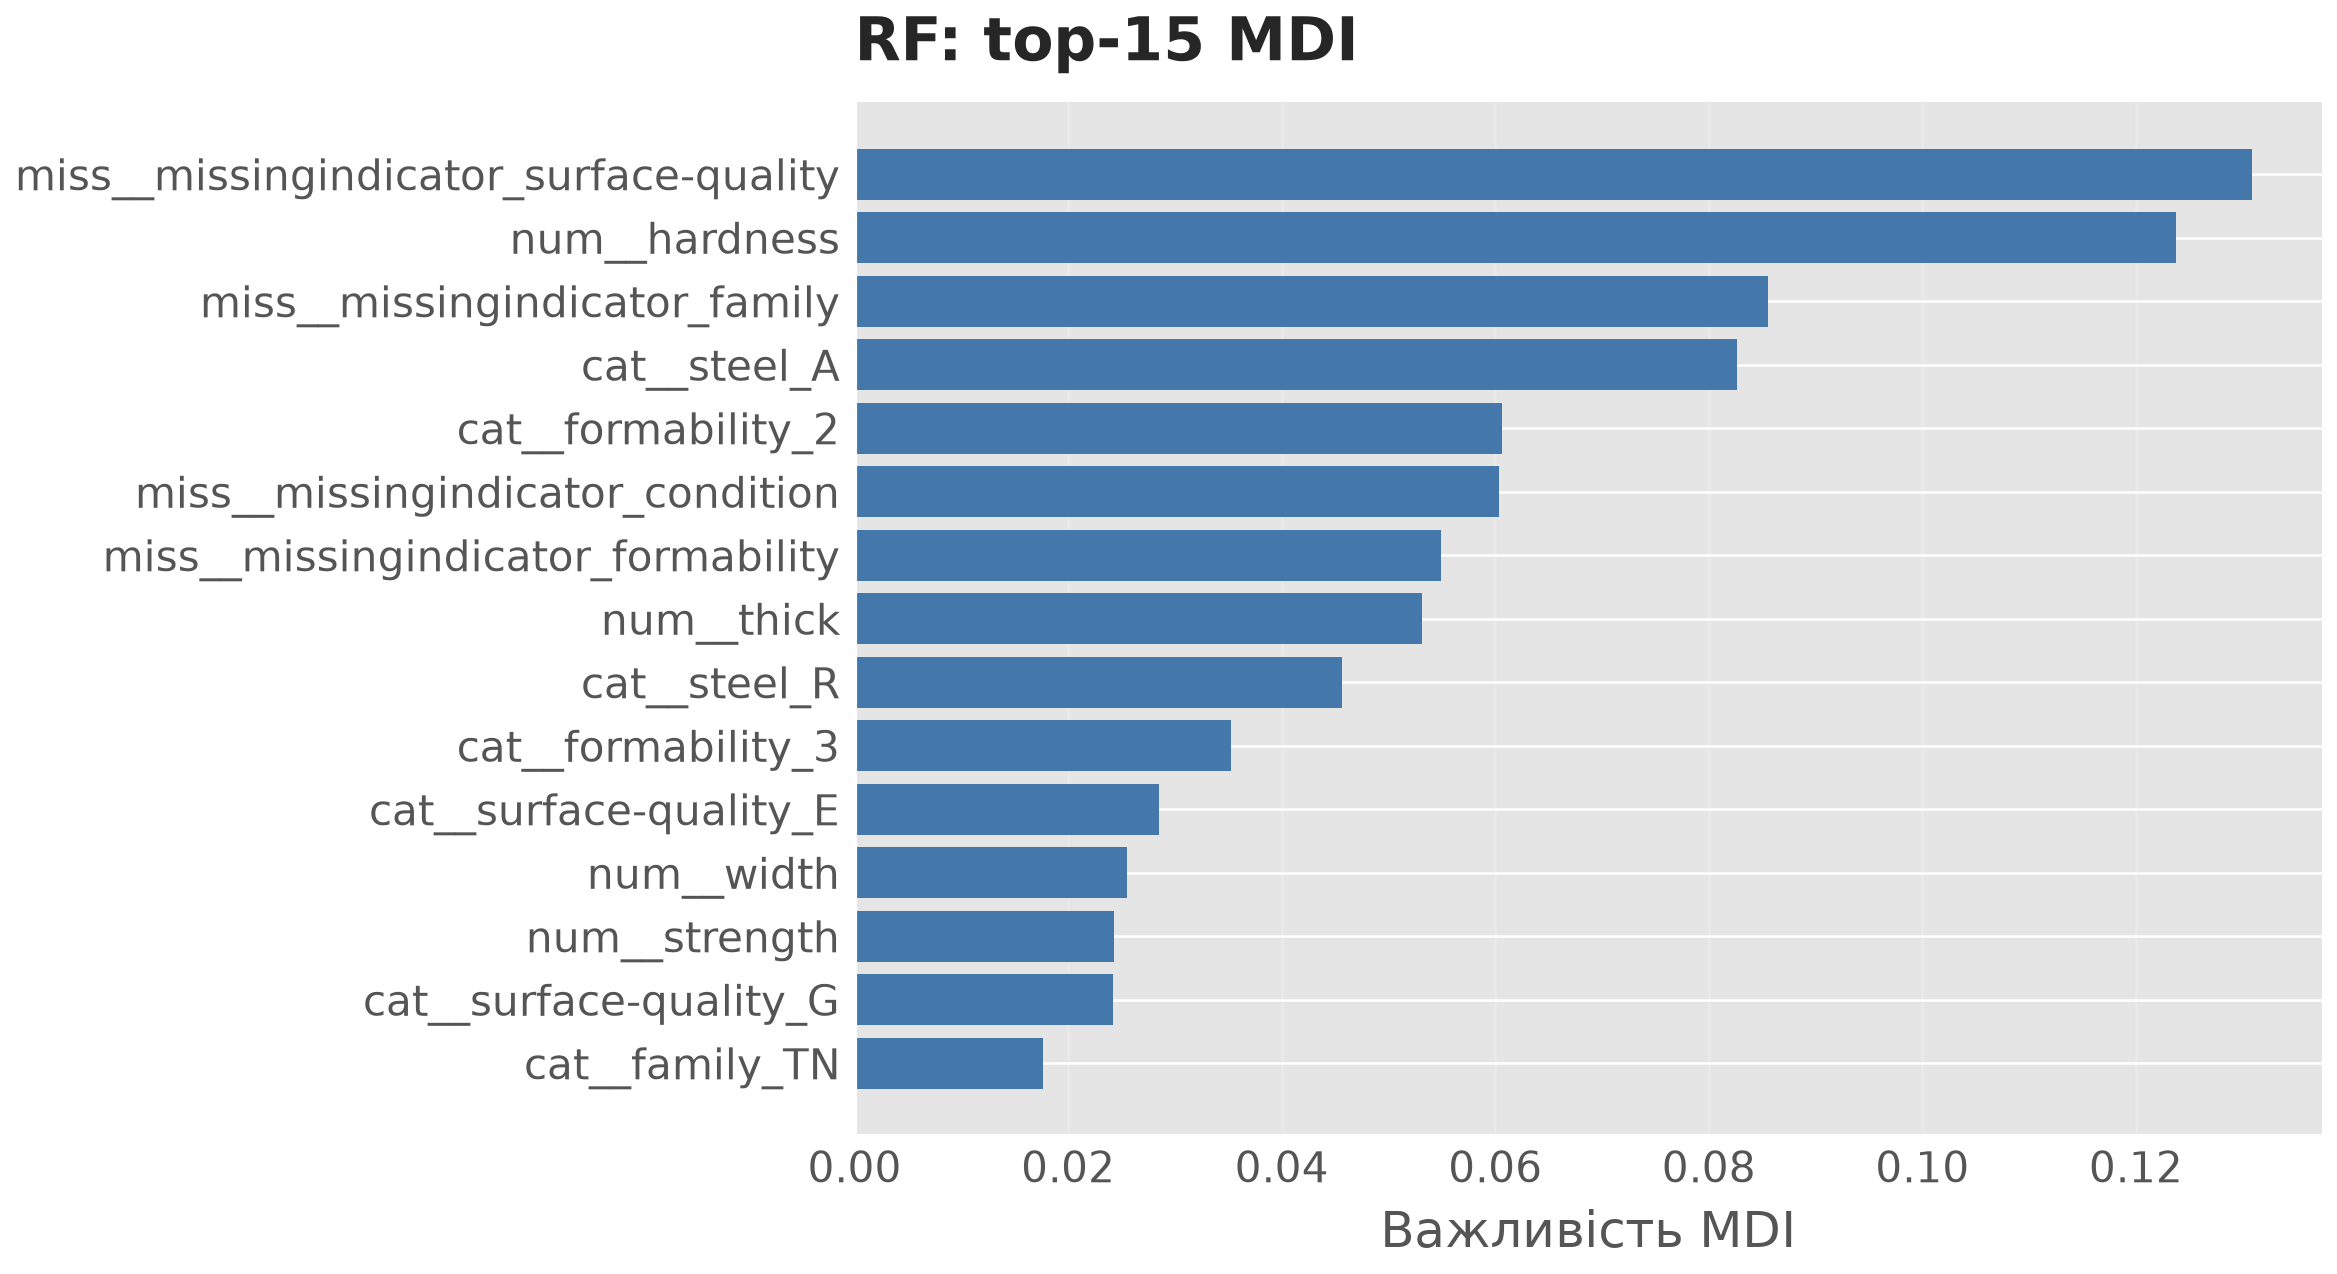

**Рисунок 13. RF: top-15 MDI**

На рисунку 14 показано rf: top-15 permutation importance.

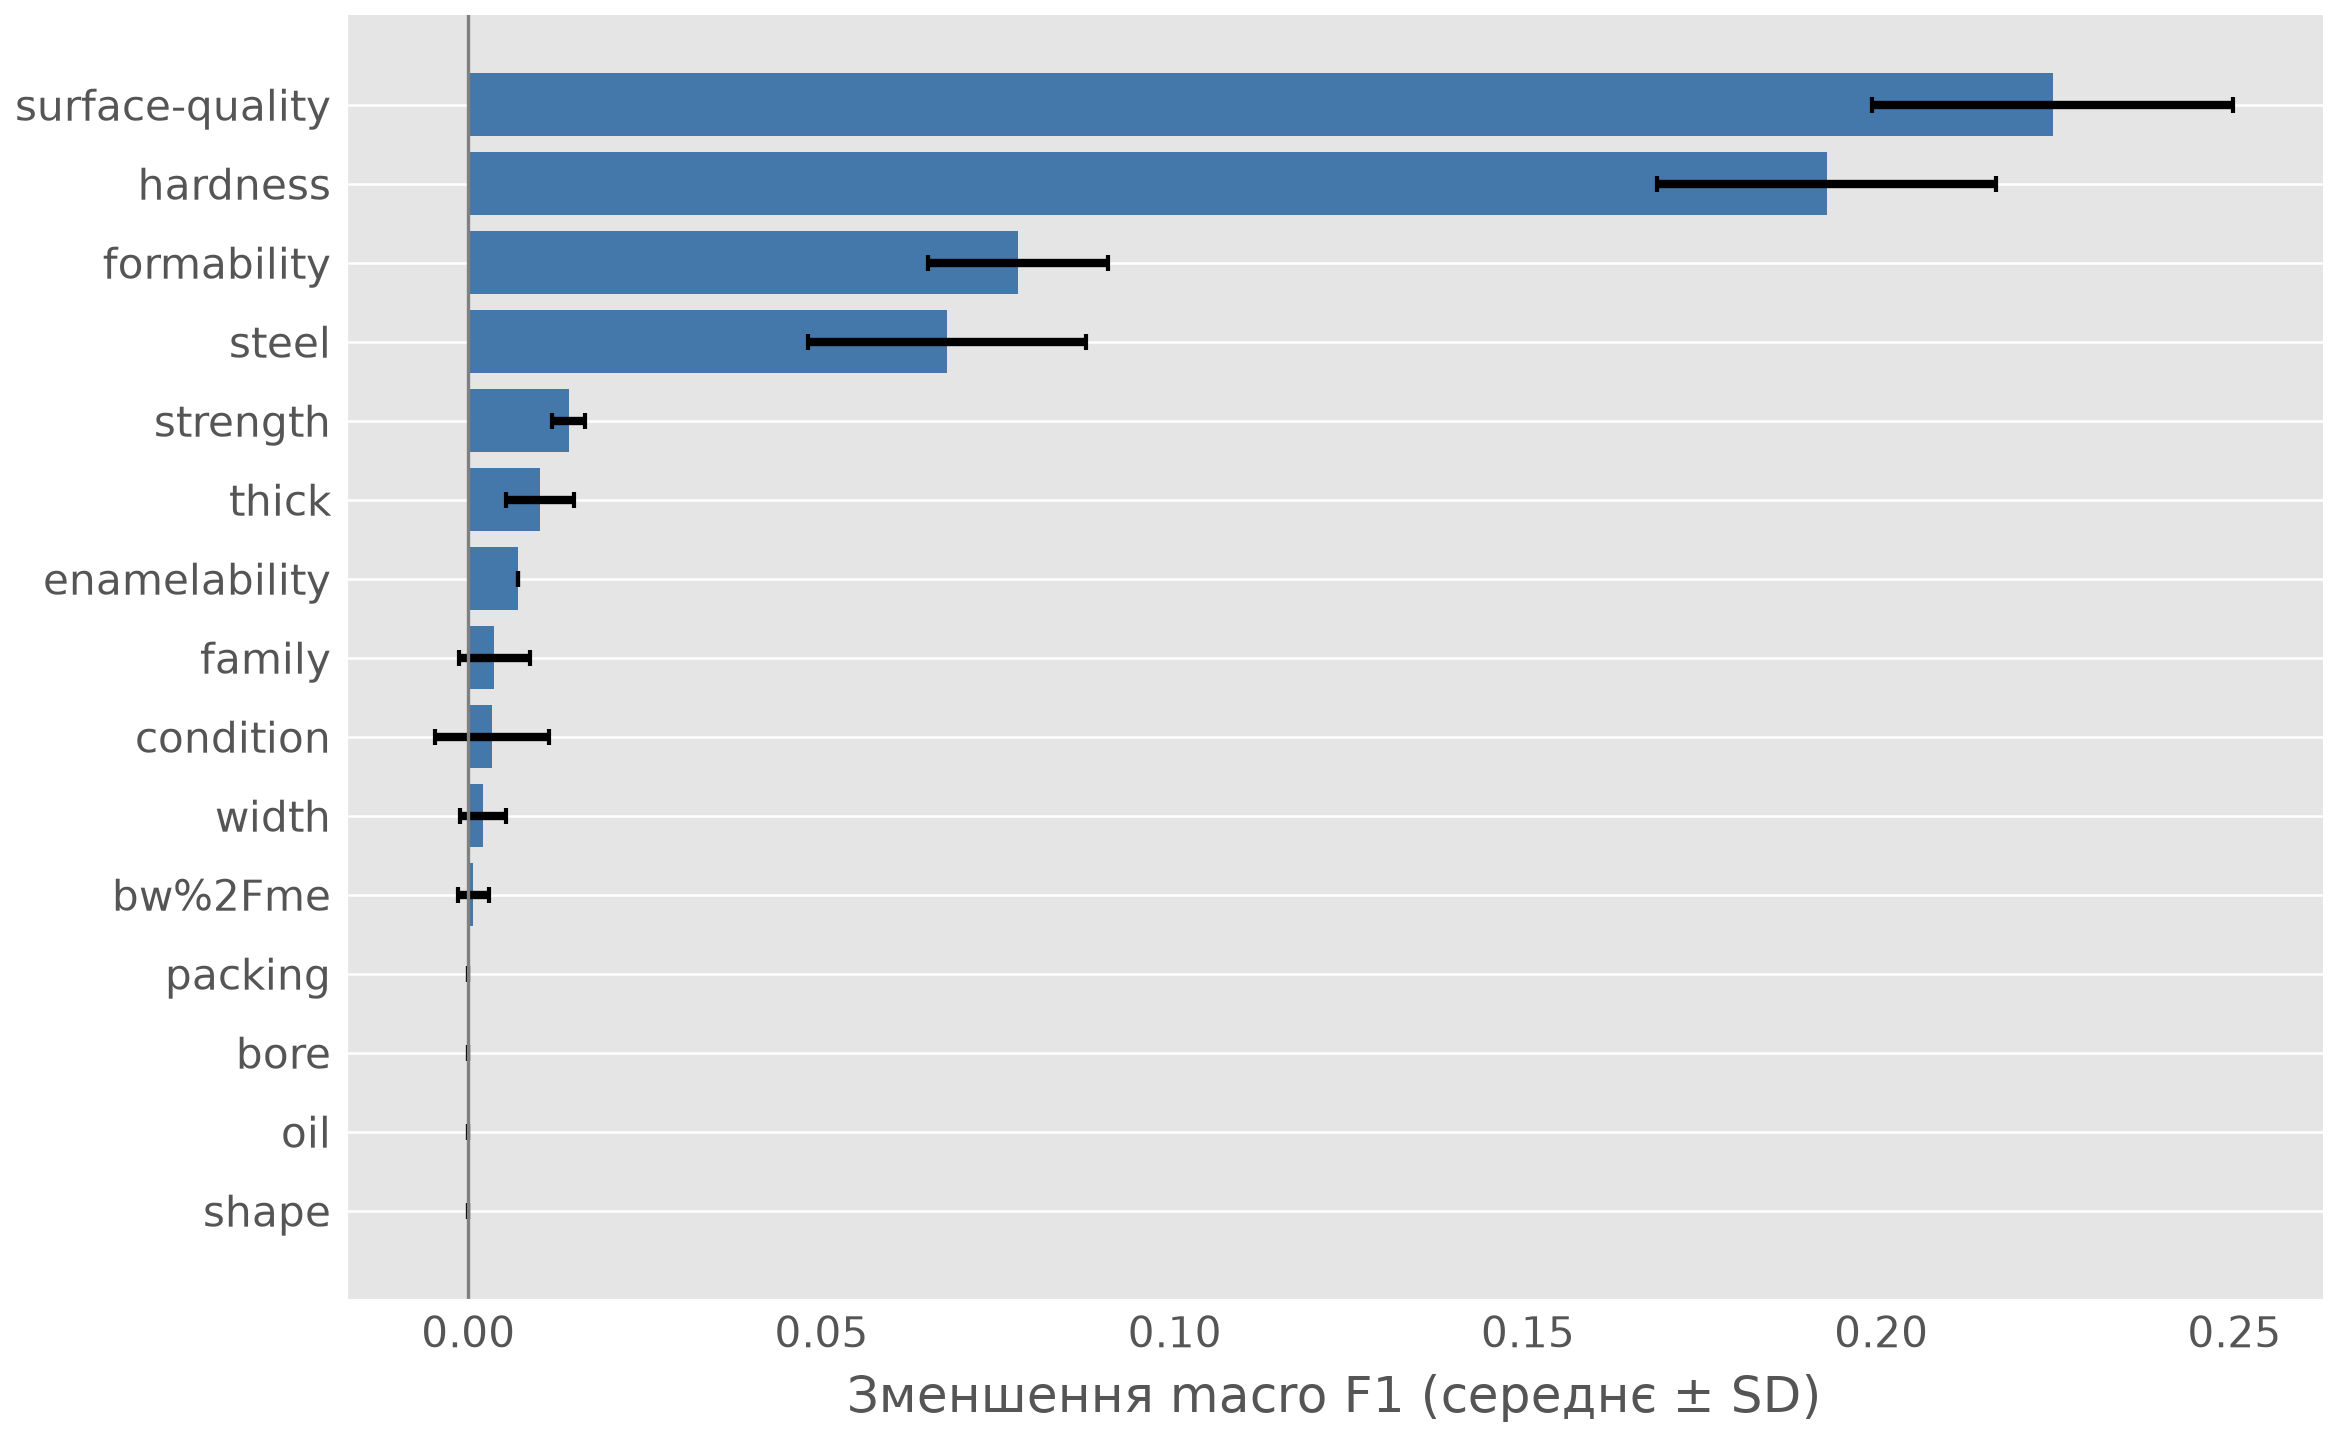

**Рисунок 14. RF: top-15 permutation importance**

RF: індикатори серед top-15 MDI: ['miss__missingindicator_surface-quality', 'miss__missingindicator_family', 'miss__missingindicator_condition', 'miss__missingindicator_formability']. Найважливіша оброблена ознака - miss__missingindicator_surface-quality, початкова за permutation - surface-quality.

На рисунку 15 показано xgb: top-15 mdi.

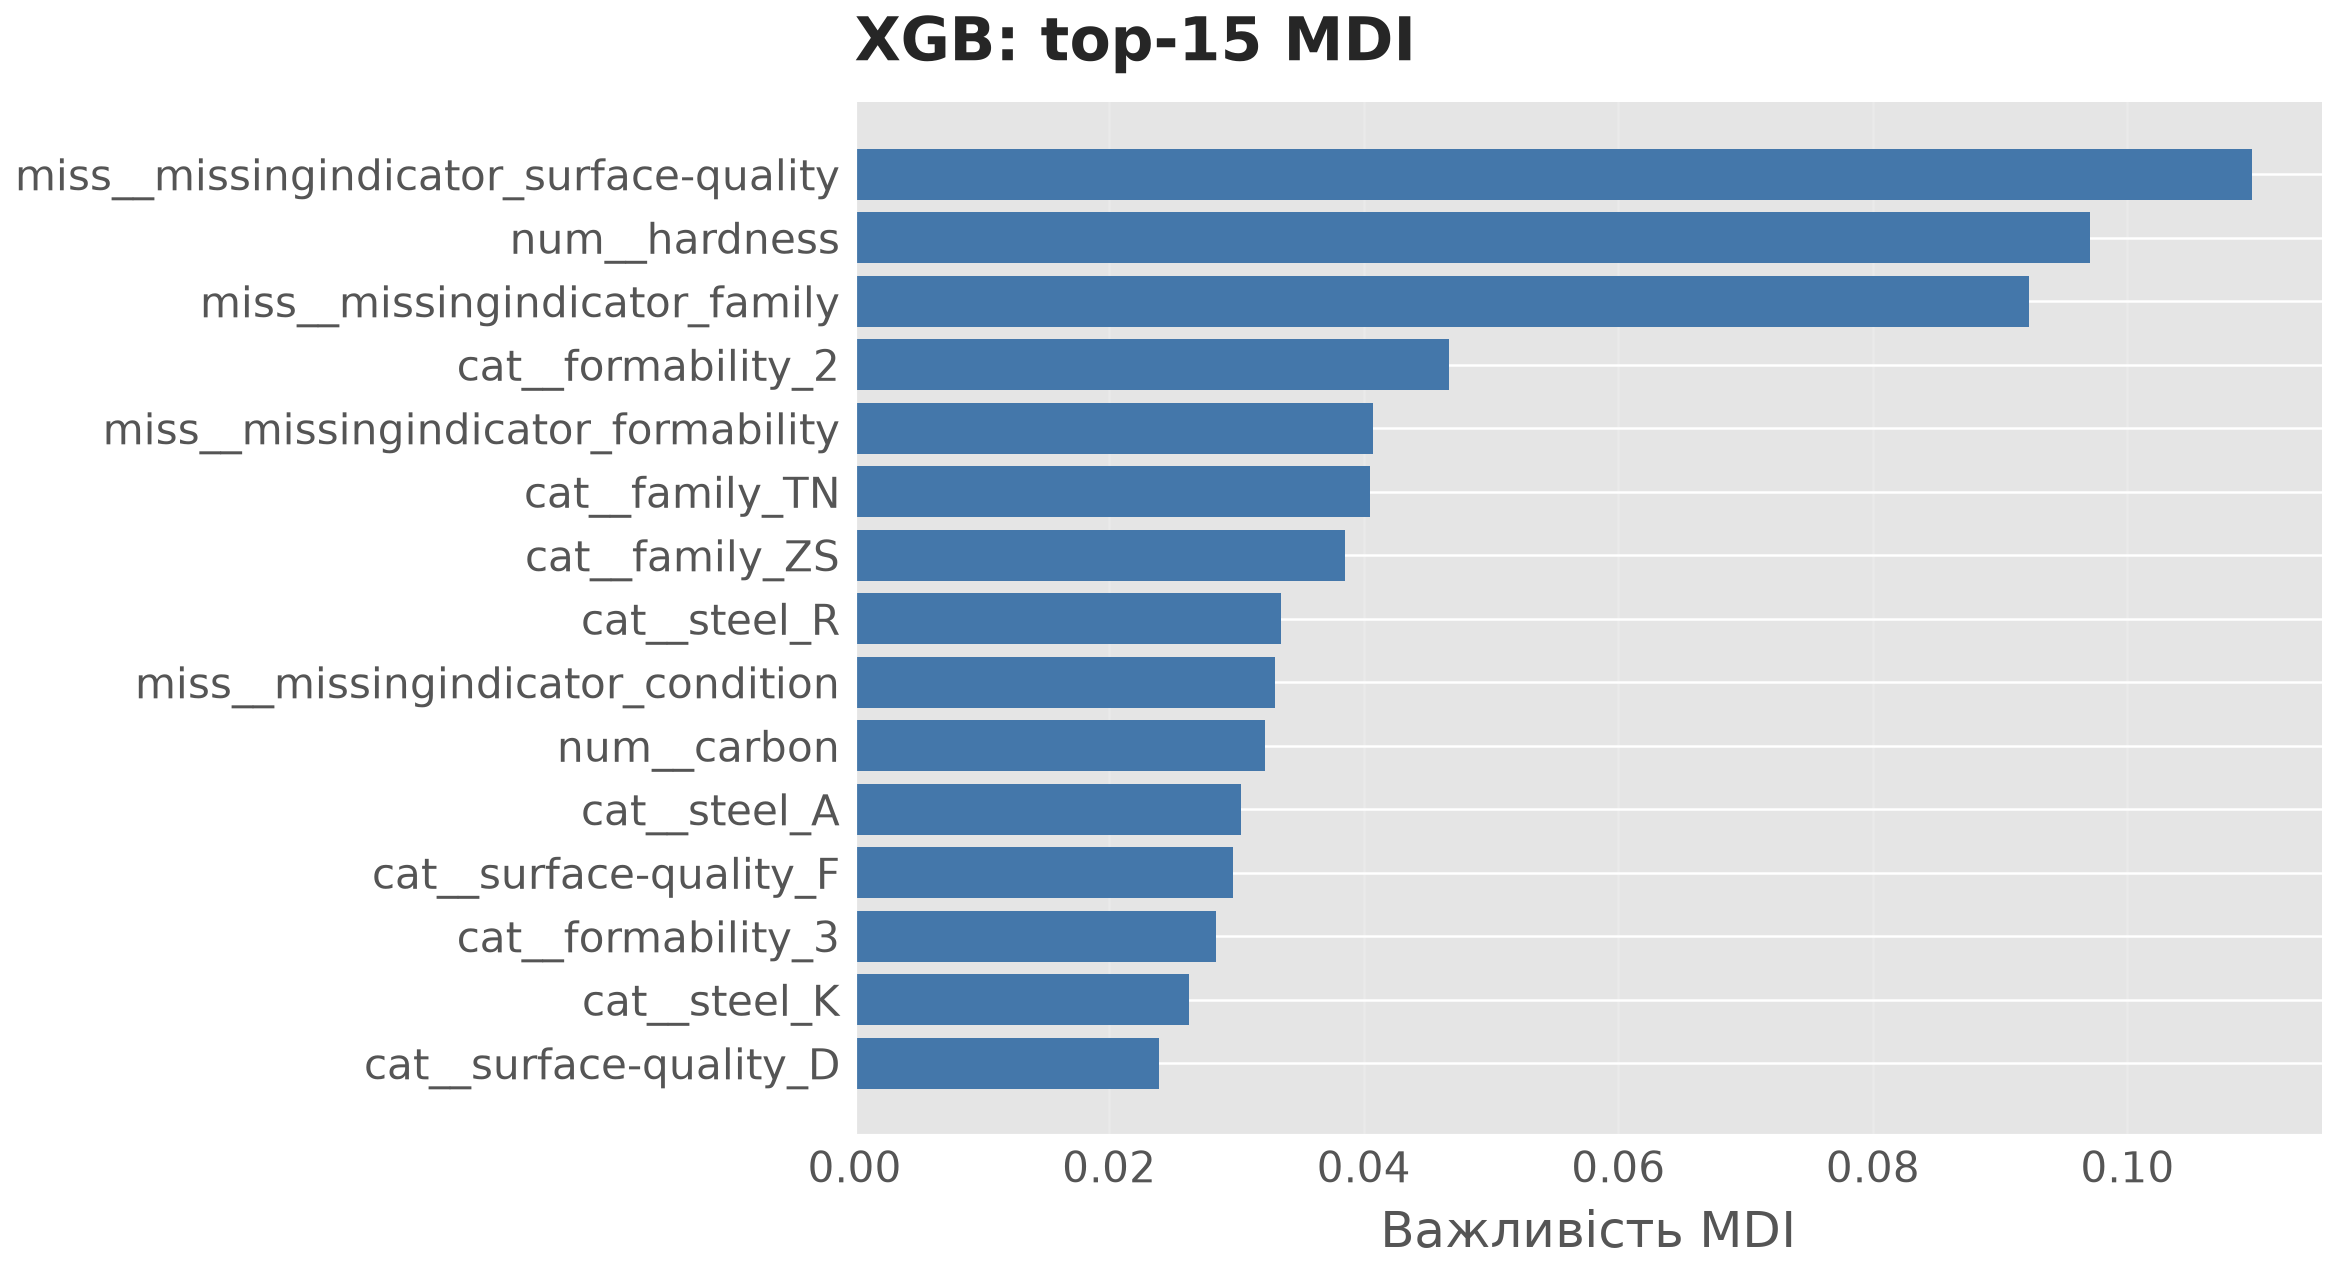

**Рисунок 15. XGB: top-15 MDI**

На рисунку 16 показано xgb: top-15 permutation importance.

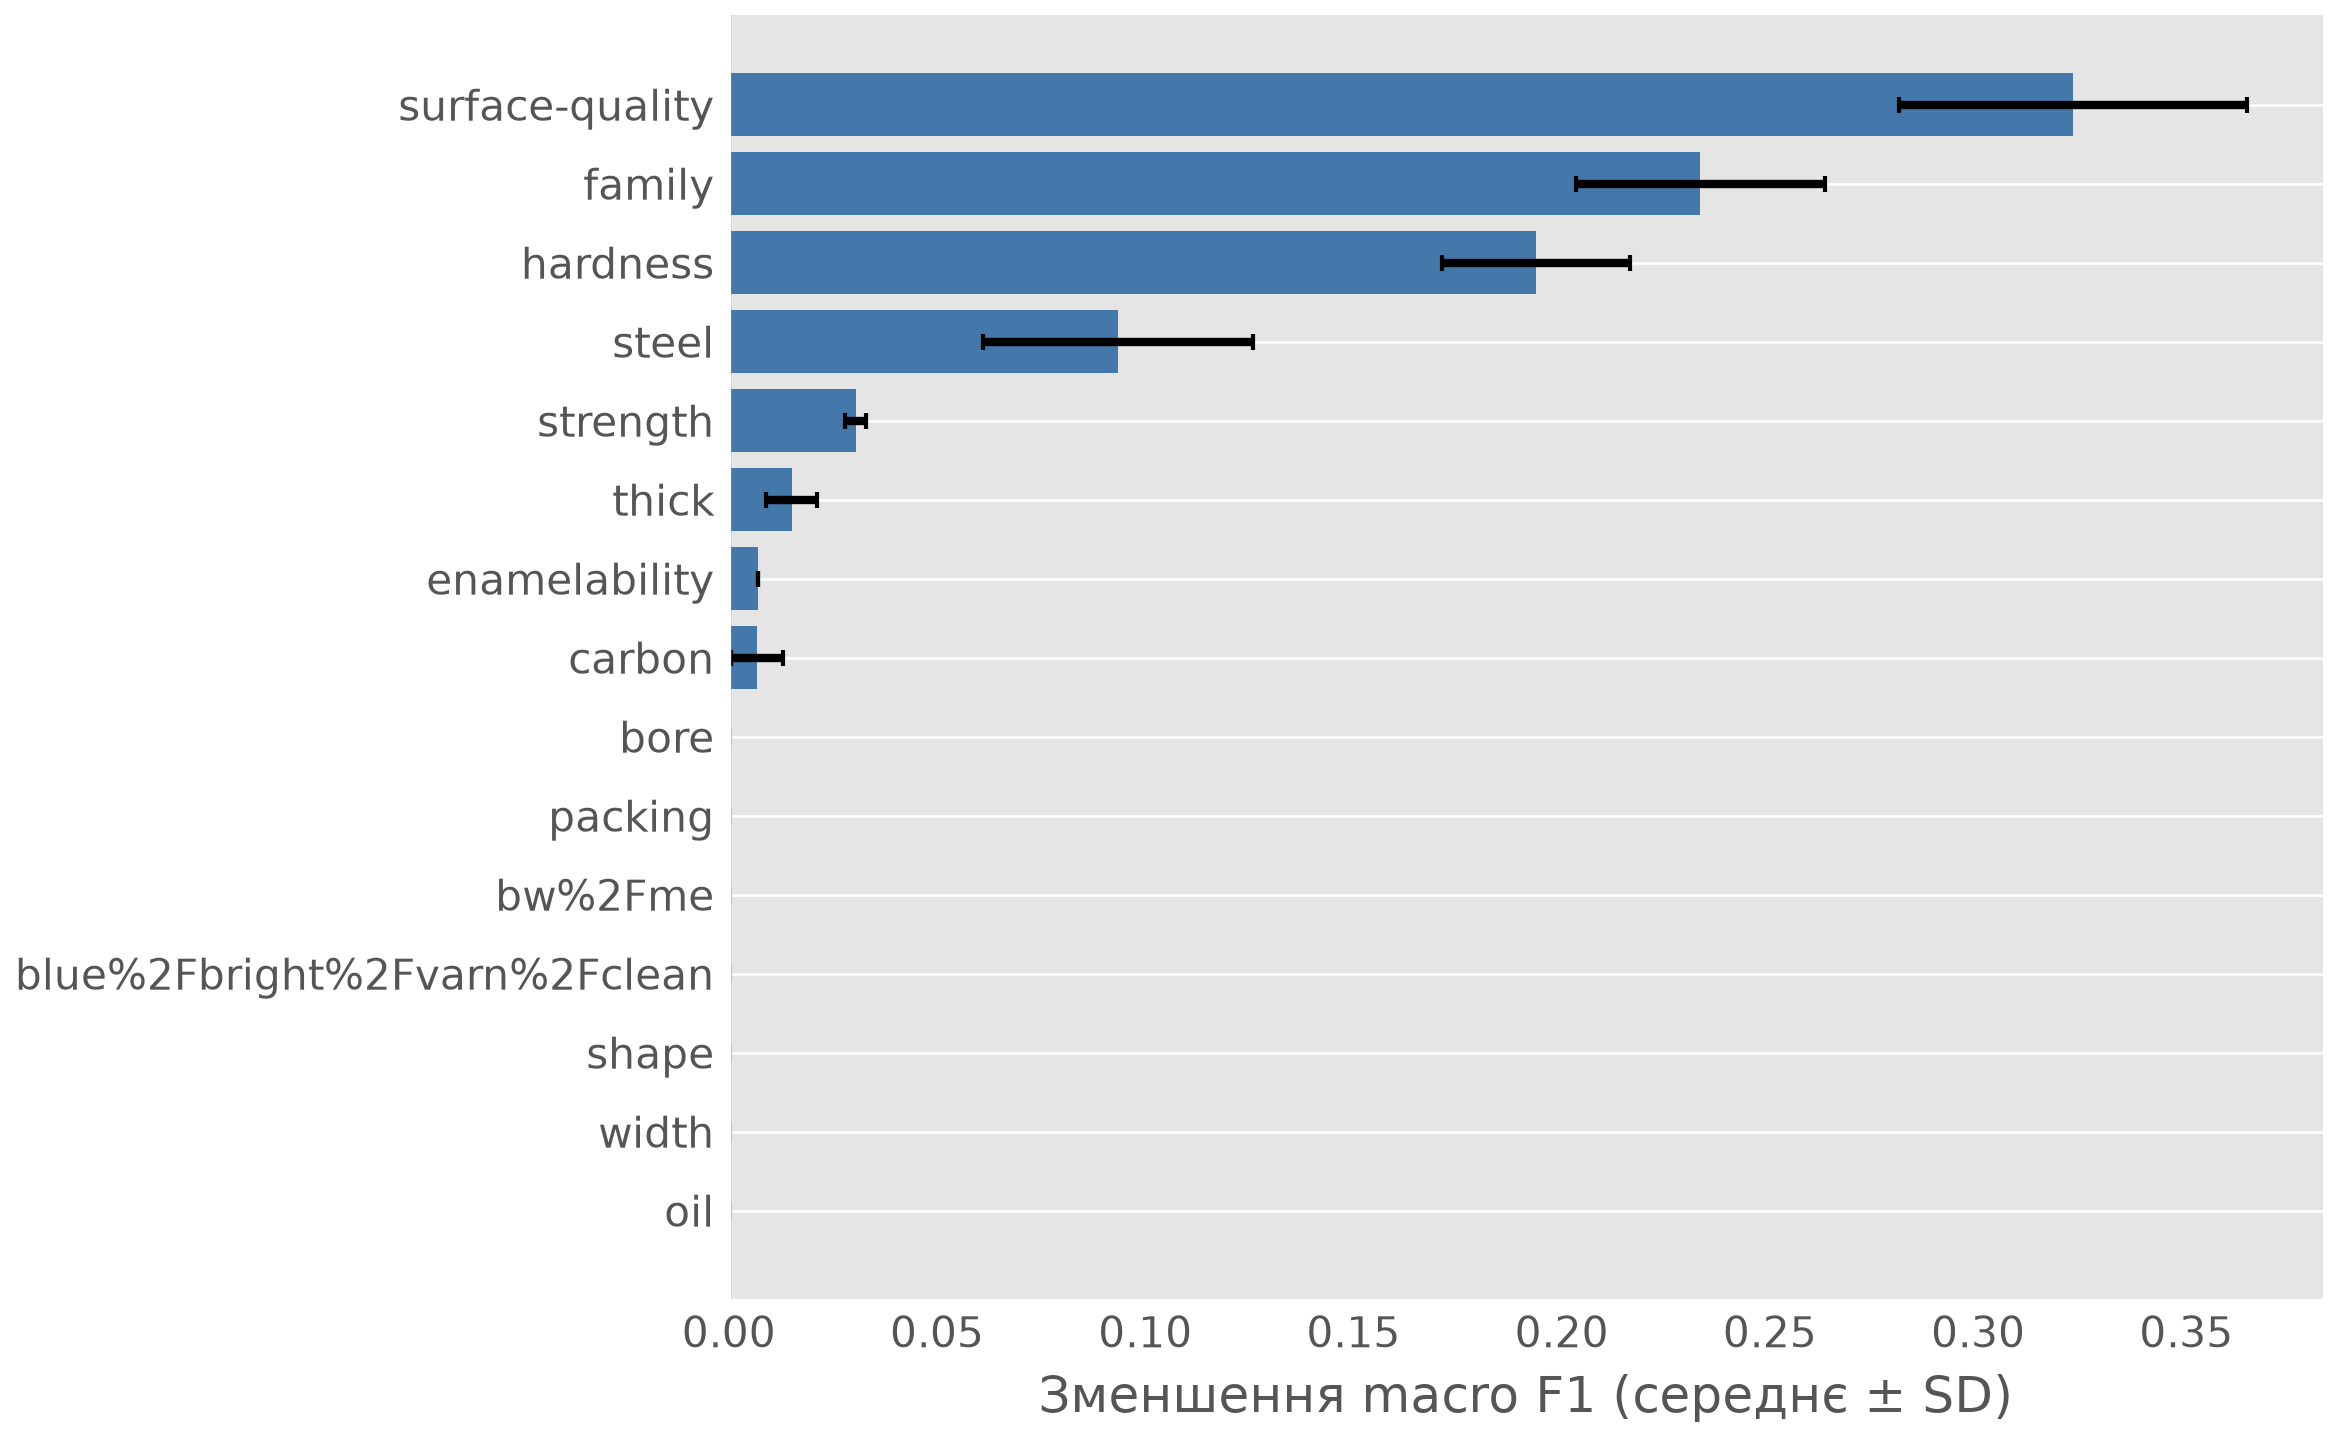

**Рисунок 16. XGB: top-15 permutation importance**

XGB: індикатори серед top-15 MDI: ['miss__missingindicator_surface-quality', 'miss__missingindicator_family', 'miss__missingindicator_formability', 'miss__missingindicator_condition']. Найважливіша оброблена ознака - miss__missingindicator_surface-quality, початкова за permutation - surface-quality.

Зв’язок пропусків із класом пояснює потенційну корисність індикаторів, але не гарантує їхню високу MDI: one-hot чи інші корельовані ознаки можуть дублювати сигнал. MDI віддає перевагу змінним із багатьма можливими розбиттями, зокрема числовим із великою кількістю унікальних значень. Permutation оцінює важливість поза навчальними даними, але кореляція дає моделі змогу заміняти перемішану ознаку іншою. DT концентрує важливість на одиничних порогах, RF розподіляє її через підвибірки ознак, XGB послідовно уточнює залишкові помилки.

In [7]:
mdi={}; perm={}; indicators={}
for n in NAMES:
 prep=final[n].named_steps['prep']; clf=final[n].named_steps['clf']
 mdi[n]=pd.Series(clf.feature_importances_,index=prep.get_feature_names_out())
 bar(mdi[n],f'{n}: top-15 MDI','Важливість MDI',15)
 pi=permutation_importance(final[n],X_test,y_test,n_repeats=10,random_state=SEED,scoring='f1_macro',n_jobs=1)
 perm[n]=pd.DataFrame({'mean':pi.importances_mean,'SD':pi.importances_std},index=X_test.columns)
 s=perm[n].sort_values('mean').tail(15)
 fig,ax=plt.subplots(figsize=(8,5))
 ax.barh(s.index,s['mean'],xerr=s['SD'],color='#4477AA',capsize=2)
 ax.set_xlabel('Зменшення macro F1 (середнє ± SD)'); ax.axvline(0,color='gray',lw=.8)
 showfig(fig,f'{n}: top-15 permutation importance')
 indicators[n]=[s for s in mdi[n].nlargest(15).index if 'missingindicator' in s]
 note(f'{n}: індикатори серед top-15 MDI: {indicators[n] or "немає"}. Найважливіша оброблена ознака - {mdi[n].idxmax()}, початкова за permutation - {perm[n]["mean"].idxmax()}.')
 mdi[n].to_csv(RESULT/f'MDI_{n}.csv'); perm[n].to_csv(RESULT/f'permutation_{n}.csv')
note('Зв’язок пропусків із класом пояснює потенційну корисність індикаторів, але не гарантує їхню високу MDI: one-hot чи інші корельовані ознаки можуть дублювати сигнал. MDI віддає перевагу змінним із багатьма можливими розбиттями, зокрема числовим із великою кількістю унікальних значень. Permutation оцінює важливість поза навчальними даними, але кореляція дає моделі змогу заміняти перемішану ознаку іншою. DT концентрує важливість на одиничних порогах, RF розподіляє її через підвибірки ознак, XGB послідовно уточнює залишкові помилки.')


## 7. Розбіжності та локальний SHAP
Розбіжність: хоча б два з трьох прогнозів відрізняються. Спочатку шукаємо test-об’єкти. Якщо їх менше трьох, доповнюємо cross_val_predict на спільній зовнішній 5-fold CV, явно вказуючи джерело. Параметри в такому OOF фіксовані після налаштування на всьому train, тому OOF слугує лише діагностиці, не незалежній оцінці якості процедури налаштування. Для локального аналізу OOF використовується модель, що не навчалася на вибраному об’єкті.


У таблиці 7 наведено розбіжні прогнози з явним джерелом.

**Таблиця 7. Розбіжні прогнози з явним джерелом**

,джерело,індекс,справжній,DT,RF,XGB
0,test,90,U,U,3,3
1,train OOF,133,2,2,2,3
2,train OOF,682,2,2,2,3


Локальний об’єкт: test 90 ; справжній клас: U


,початкове,пропущено,DT після імпутації,RF після імпутації,XGB після імпутації
family,NaN,True,TN,TN,TN
product-type,C,False,вилучено,вилучено,вилучено
steel,A,False,A,A,A
carbon,10,False,10,10,10
hardness,0,False,0,0,0
temper_rolling,NaN,True,вилучено,вилучено,вилучено
condition,NaN,True,S,S,S
formability,NaN,True,2,2,2
strength,0,False,0,0,0
non-ageing,NaN,True,вилучено,вилучено,вилучено


,ознака,SHAP
0,num__carbon,0.834071
1,miss__missingindicator_surface-quality,0.139094
2,num__hardness,-0.024502
3,num__strength,0.006393
4,num__thick,0.000000


На рисунку 17 показано dt: п’ять найбільших |shap| для прогнозованого класу u.

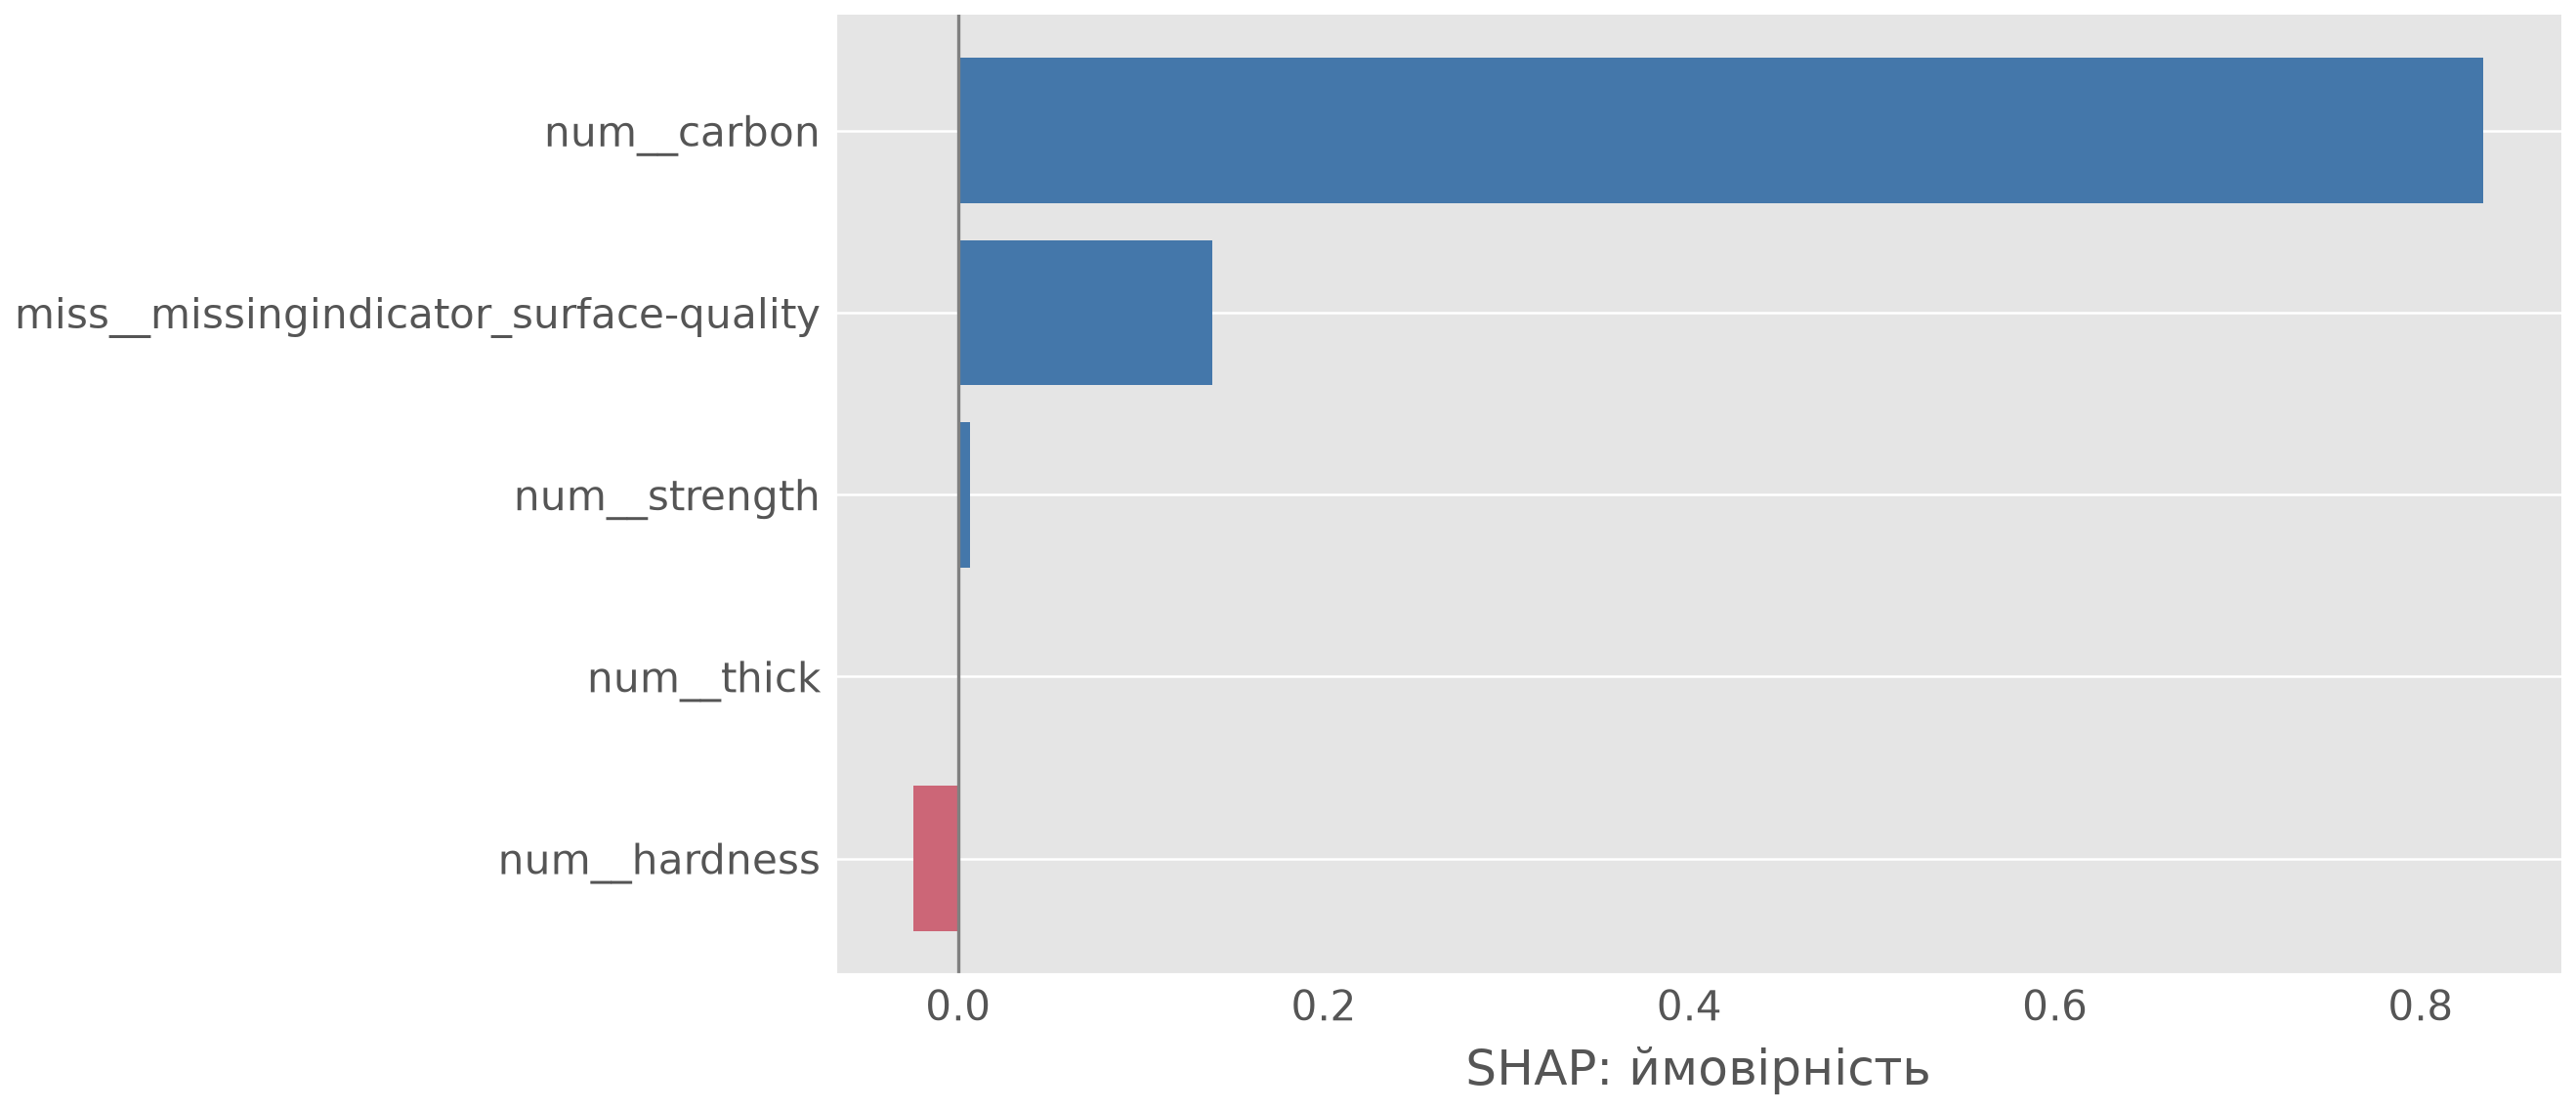

**Рисунок 17. DT: п’ять найбільших |SHAP| для прогнозованого класу U**

,ознака,SHAP
0,num__hardness,0.122712
1,miss__missingindicator_surface-quality,0.097202
2,num__width,0.084034
3,miss__missingindicator_family,0.041923
4,miss__missingindicator_condition,-0.030796


На рисунку 18 показано rf: п’ять найбільших |shap| для прогнозованого класу 3.

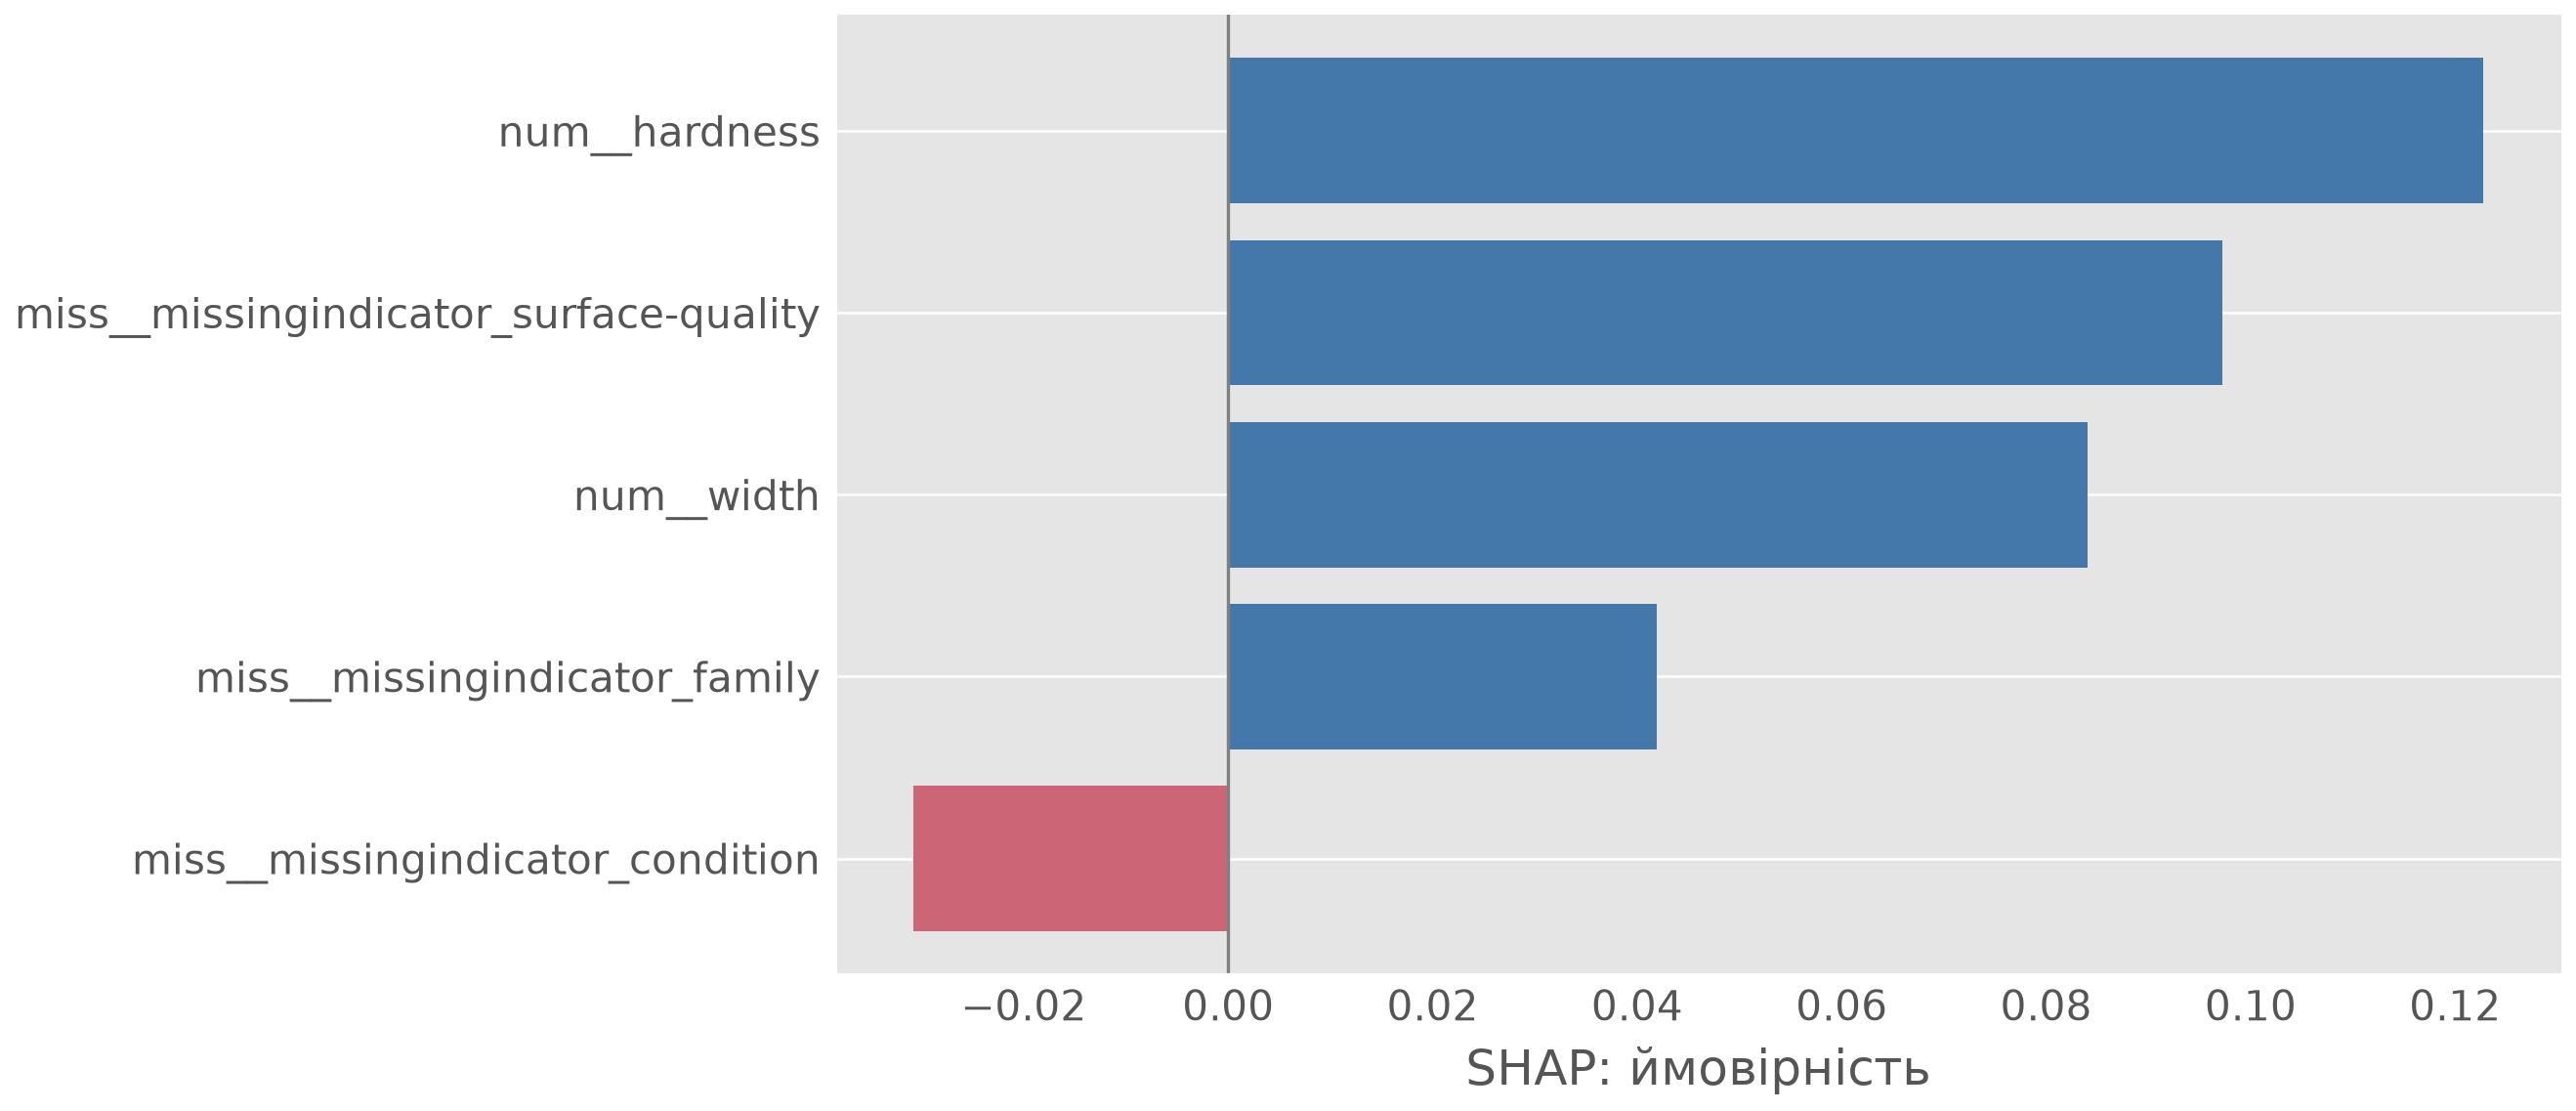

**Рисунок 18. RF: п’ять найбільших |SHAP| для прогнозованого класу 3**

,ознака,SHAP
0,miss__missingindicator_surface-quality,0.292909
1,num__hardness,0.177994
2,num__carbon,0.158072
3,miss__missingindicator_condition,-0.150323
4,num__width,0.103450


На рисунку 19 показано xgb: п’ять найбільших |shap| для прогнозованого класу 3.

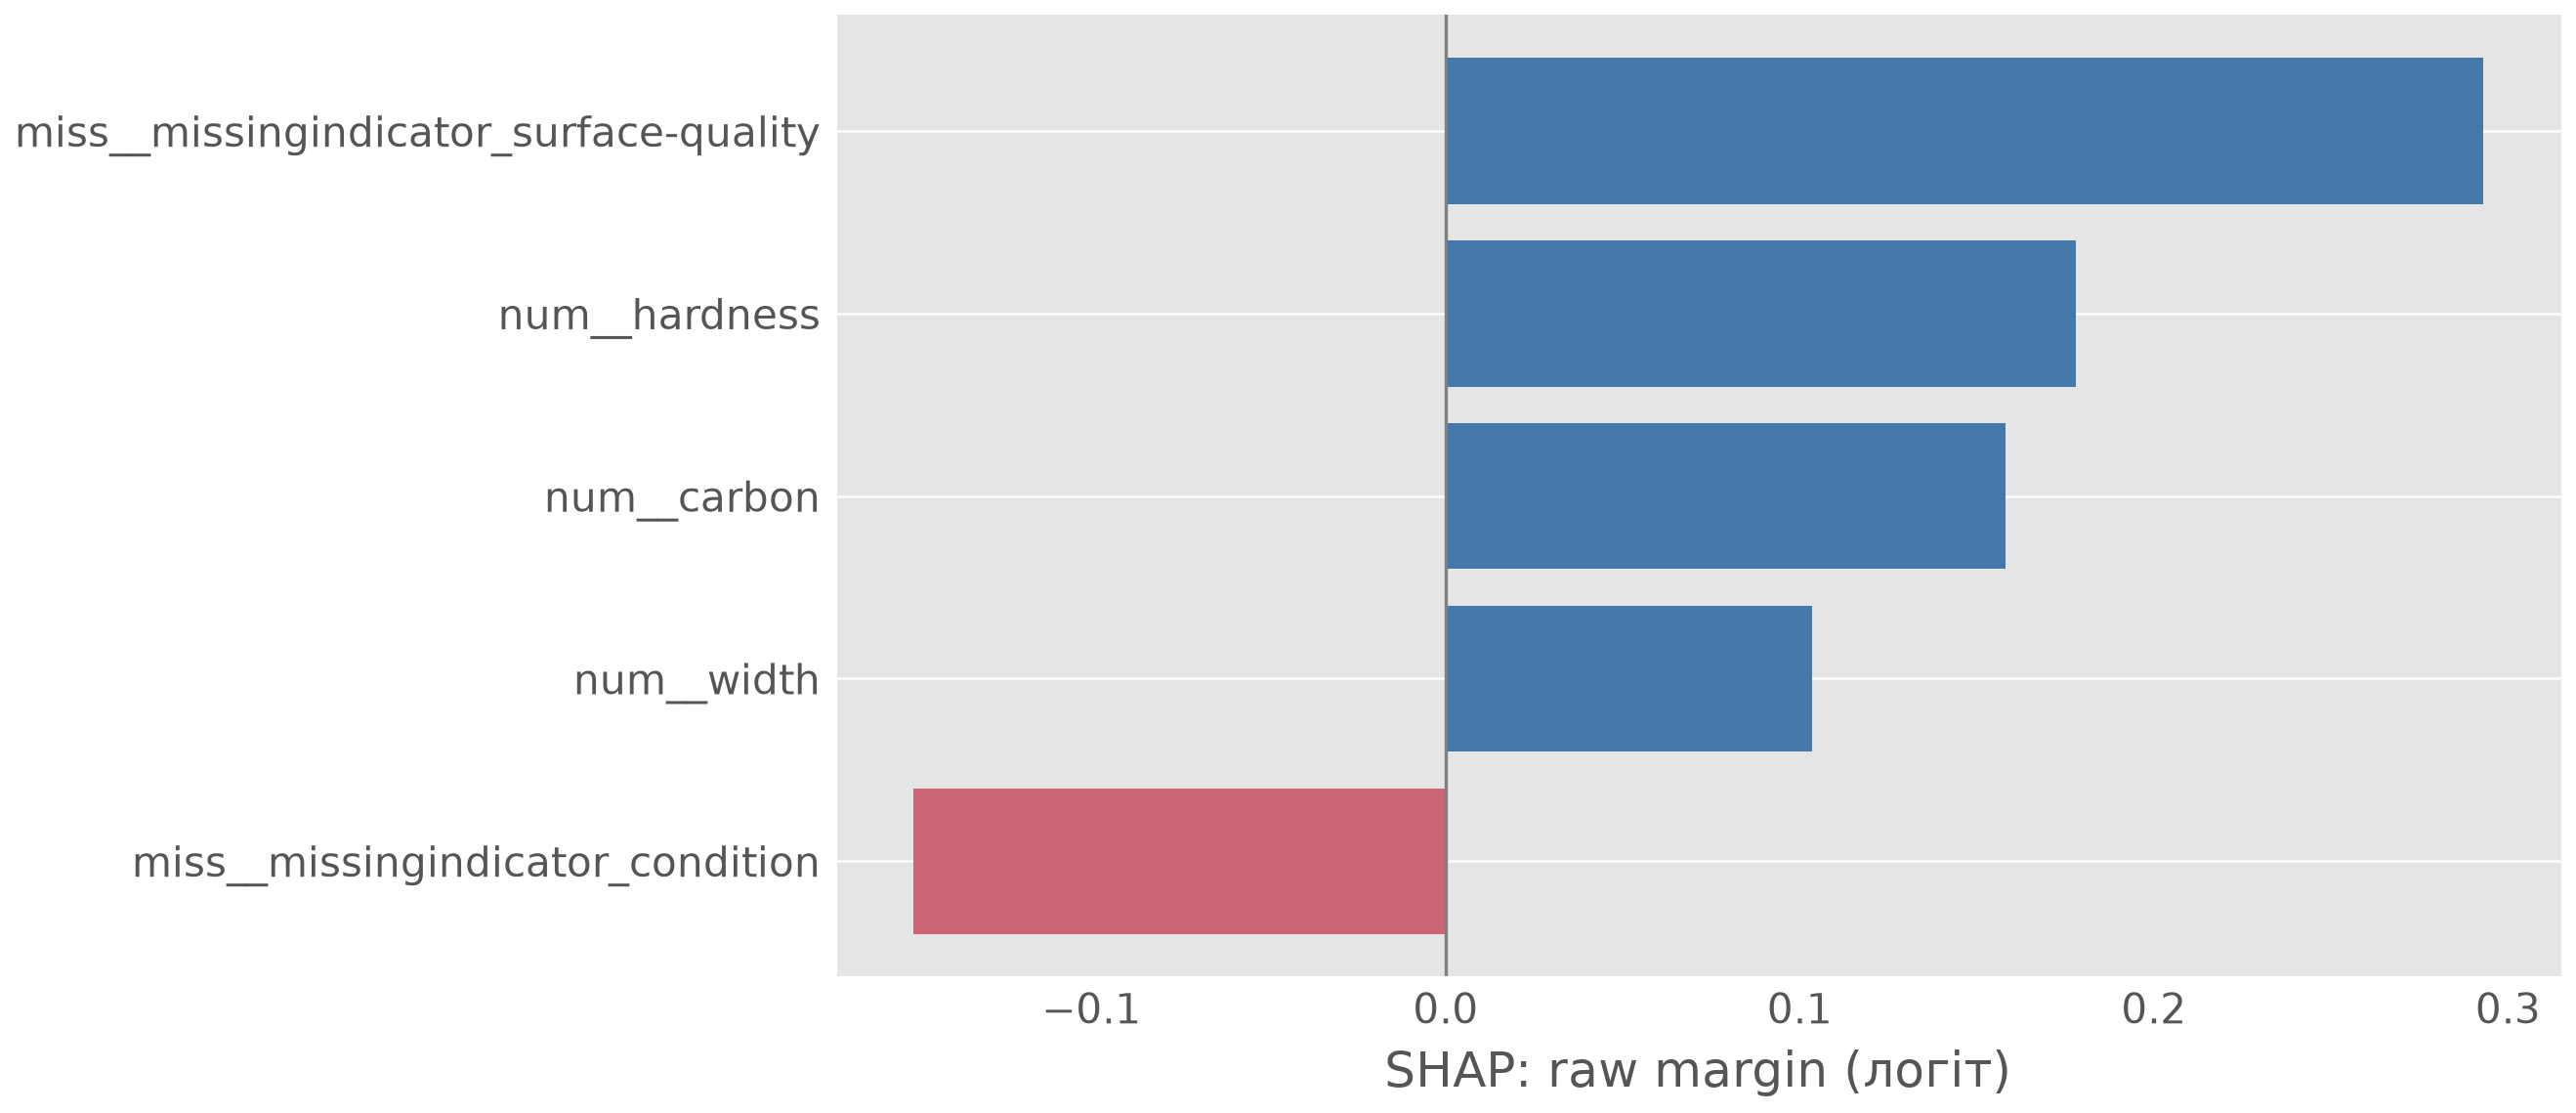

**Рисунок 19. XGB: п’ять найбільших |SHAP| для прогнозованого класу 3**

,2,3,5,U
DT,0.000000,0.000000,0.000000,1.000000
RF,0.037311,0.662861,0.008682,0.291147
XGB,0.019869,0.934987,0.012722,0.032422


Перевірка адитивності SHAP:


,модель,shape,base+sum,ціль
0,DT,"[1, 50, 4]",1.000000,1.000000
1,RF,"[1, 50, 4]",0.662861,0.662861
2,XGB,"[1, 50, 4]",2.468968,2.468966


На test знайдено 1 розбіжних об’єктів. Для локального об’єкта 90 досліджено початкові значення, імпутацію кожної моделі і класифікаційні ймовірності. SHAP обчислено окремо для прогнозованого класу кожної моделі; різні класи та шкали DT/RF і XGB не дозволяють прямо зіставляти абсолютні величини між моделями.

DT: top-5 внесків ['num__carbon', 'miss__missingindicator_surface-quality', 'num__hardness', 'num__strength', 'num__thick']; розрив двох найбільших ймовірностей = 1.0000. Менший розрив свідчить про меншу впевненість моделі, але не є каліброваною відстанню до межі. Імпутація визначає положення об’єкта відносно порогів; індикатор дозволяє відрізнити справжнє типове значення від заповненого.

RF: top-5 внесків ['num__hardness', 'miss__missingindicator_surface-quality', 'num__width', 'miss__missingindicator_family', 'miss__missingindicator_condition']; розрив двох найбільших ймовірностей = 0.3717. Менший розрив свідчить про меншу впевненість моделі, але не є каліброваною відстанню до межі. Імпутація визначає положення об’єкта відносно порогів; індикатор дозволяє відрізнити справжнє типове значення від заповненого.

XGB: top-5 внесків ['miss__missingindicator_surface-quality', 'num__hardness', 'num__carbon', 'miss__missingindicator_condition', 'num__width']; розрив двох найбільших ймовірностей = 0.9026. Менший розрив свідчить про меншу впевненість моделі, але не є каліброваною відстанню до межі. Імпутація визначає положення об’єкта відносно порогів; індикатор дозволяє відрізнити справжнє типове значення від заповненого.

Одне дерево використовує жорсткі пороги, тому невелика зміна заповненого значення може змінити лист і клас. RF усереднює дерева; XGB складає послідовні поправки до margin. Якщо індикатор або імпутована ознака відсутні серед top-5, немає підстав приписувати саме їм вирішальну роль у розбіжності. SHAP пояснює поведінку моделі, а не причинний ефект ознаки.

In [8]:
rows=[]; candidates=[]
for pos in range(len(X_test)):
 pp=[int(preds[n][pos]) for n in NAMES]
 if len(set(pp))>1:
  rows.append({'джерело':'test','індекс':X_test.index[pos],'справжній':encoder.inverse_transform([y_test[pos]])[0],
    **{n:encoder.inverse_transform([pp[k]])[0] for k,n in enumerate(NAMES)}})
  candidates.append(('test',pos))
ntest_disagreements=len(rows)
if len(rows)<3:
 oof={n:cross_val_predict(build_pipeline(n,True,studies[n].best_params),X_train,y_train,cv=outer) for n in NAMES}
 for pos in range(len(X_train)):
  pp=[int(oof[n][pos]) for n in NAMES]
  if len(set(pp))>1:
   rows.append({'джерело':'train OOF','індекс':X_train.index[pos],'справжній':encoder.inverse_transform([y_train[pos]])[0],
    **{n:encoder.inverse_transform([pp[k]])[0] for k,n in enumerate(NAMES)}})
   candidates.append(('train OOF',pos))
   if len(rows)>=3: break
assert len(rows)>=3,'Недостатньо фактичних розбіжностей для вимоги методички'
disagree=pd.DataFrame(rows)
table(7,'Розбіжні прогнози з явним джерелом',disagree)
source,pos=candidates[0]
if source=='test':
 row=X_test.iloc[[pos]]; local_models=final; actual=y_test[pos]
else:
 row=X_train.iloc[[pos]]; actual=y_train[pos]
 tr=next(tr for tr,va in outer if pos in va)
 local_models={n:build_pipeline(n,True,studies[n].best_params).fit(X_train.iloc[tr],y_train[tr]) for n in NAMES}
print('Локальний об’єкт:',source,row.index[0],'; справжній клас:',encoder.inverse_transform([actual])[0])
# Показуємо всі початкові ознаки, включно з вилученими.
raw=X0.loc[row.index[0]]
filled=pd.DataFrame({'початкове':raw,'пропущено':raw.isna()})
for n in NAMES:
 prep=local_models[n].named_steps['prep']
 stats={**dict(zip(num,prep.named_transformers_['num'].statistics_)),
        **dict(zip(cat,prep.named_transformers_['cat'].named_steps['impute'].statistics_))}
 filled[n+' після імпутації']=[('вилучено' if c in drop else (stats[c] if pd.isna(raw[c]) else raw[c])) for c in raw.index]
display(filled); filled.to_csv(RESULT/'local_imputation.csv')
local_probs={}; local_shap={}; shap_checks=[]
for n in NAMES:
 pipe=local_models[n]; clf=pipe.named_steps['clf']; prep=pipe.named_steps['prep']
 z=prep.transform(row); names=prep.get_feature_names_out()
 probability=pipe.predict_proba(row)[0]; pred=int(pipe.predict(row)[0]); local_probs[n]=probability
 explainer=shap.TreeExplainer(clf)
 sv=np.asarray(explainer.shap_values(z))
 assert sv.shape==(1,len(names),len(encoder.classes_)),(n,sv.shape)
 contribution=sv[0,:,pred]
 baseline=np.asarray(explainer.expected_value)[pred]
 reconstructed=baseline+contribution.sum()
 if n=='XGB':
  raw_margin=clf.predict(z,output_margin=True)[0]
  target_value=raw_margin[pred]
  reconstructed_all=np.asarray(explainer.expected_value)+sv[0].sum(axis=0)
  softmax=np.exp(reconstructed_all-reconstructed_all.max()); softmax/=softmax.sum()
  assert np.allclose(softmax,probability,atol=1e-5)
 else: target_value=probability[pred]
 assert np.isclose(reconstructed,target_value,atol=1e-5)
 shap_checks.append({'модель':n,'shape':list(sv.shape),'base+sum':float(reconstructed),'ціль':float(target_value)})
 local_shap[n]=pd.Series(contribution,index=names)
 top=local_shap[n].abs().nlargest(5).index
 display(pd.DataFrame({'ознака':top,'SHAP':local_shap[n].loc[top].values}))
 s=local_shap[n].loc[top].sort_values()
 fig,ax=plt.subplots(figsize=(9,4))
 ax.barh(s.index,s.values,color=['#4477AA' if v>=0 else '#CC6677' for v in s])
 ax.axvline(0,color='gray',lw=.8)
 ax.set_xlabel('SHAP: '+('raw margin (логіт)' if n=='XGB' else 'ймовірність'))
 showfig(fig,f'{n}: п’ять найбільших |SHAP| для прогнозованого класу {encoder.classes_[pred]}')
 local_shap[n].to_csv(RESULT/f'local_SHAP_{n}.csv')
local_probs=pd.DataFrame(local_probs,index=encoder.classes_).T
display(local_probs); local_probs.to_csv(RESULT/'local_probabilities.csv')
print('Перевірка адитивності SHAP:'); display(pd.DataFrame(shap_checks))
note(f'На test знайдено {ntest_disagreements} розбіжних об’єктів. Для локального об’єкта {row.index[0]} досліджено початкові значення, імпутацію кожної моделі і класифікаційні ймовірності. SHAP обчислено окремо для прогнозованого класу кожної моделі; різні класи та шкали DT/RF і XGB не дозволяють прямо зіставляти абсолютні величини між моделями.')
for n in NAMES:
 ps=np.sort(local_probs.loc[n].to_numpy())
 top=local_shap[n].abs().nlargest(5).index.tolist()
 note(f'{n}: top-5 внесків {top}; розрив двох найбільших ймовірностей = {ps[-1]-ps[-2]:.4f}. Менший розрив свідчить про меншу впевненість моделі, але не є каліброваною відстанню до межі. Імпутація визначає положення об’єкта відносно порогів; індикатор дозволяє відрізнити справжнє типове значення від заповненого.')
note('Одне дерево використовує жорсткі пороги, тому невелика зміна заповненого значення може змінити лист і клас. RF усереднює дерева; XGB складає послідовні поправки до margin. Якщо індикатор або імпутована ознака відсутні серед top-5, немає підстав приписувати саме їм вирішальну роль у розбіжності. SHAP пояснює поведінку моделі, а не причинний ефект ознаки.')


## 8. Висновки за фактичними результатами
Нижче десять речень підсумовують виконаний експеримент; усі числа беруться зі збережених результатів у пам’яті поточного запуску.


In [9]:
gains={n:nested[n].mean()-base['B',n]['test_f1m'].mean() for n in NAMES}
gain_winner=max(gains,key=gains.get)
worst_class=min(encoder.classes_,key=lambda c:report[c]['recall'])
conclusion=[
 f'За середньою вкладеною macro F1 обрано {best_nested} з результатом {nested[best_nested].mean():.4f} ± {nested[best_nested].std(ddof=1):.4f}, а на test ця модель має {test_df.loc[best_nested,"macro F1"]:.4f}.',
 f'Для двох найкращих базових моделей B {rank[:2]} скоригований тест дає p={stats_df.iloc[-1]["p"]:.4g}, тому висновок про їхню різницю: {stats_df.iloc[-1]["висновок"]}; цей тест не перевіряє оптимізованого переможця.',
 'Прирости B мінус A за базовою macro F1 становлять '+', '.join(f'{n}: {stats_df.loc[n+" B - A","d_mean"]:+.4f}' for n in NAMES)+'.',
 f'Зв’язок пропусків із класом виявлено для {(missing_tests.p<.05).sum()} з {len(missing_tests)} ознак, а кількості індикаторів у top-15 MDI становлять '+', '.join(f'{n}: {len(indicators[n])}' for n in NAMES)+', що слід тлумачити з урахуванням дублювання сигналу.',
 'Різниці звичайного best_value та nested mean дорівнюють '+', '.join(f'{n}: {summary.loc[n,"best - nested"]:+.4f}' for n in NAMES)+', тому максимум пошуку не підміняє зовнішню оцінку.',
 f'Найбільша різниця nested-після мінус repeated-CV-до налаштування у {gain_winner}: {gains[gain_winner]:+.4f}; вона включає вплив різних схем CV і не є чистим причинним ефектом оптимізації.',
 f'Найнижчий test recall обраної моделі має клас {worst_class}: {report[worst_class]["recall"]:.4f} при support={report[worst_class]["support"]}, причому дисбаланс збільшує чутливість результату до одиничних помилок.',
 f'На test знайдено {ntest_disagreements} розбіжностей, а локальні SHAP і ймовірності показали різну роль порогів, усереднення та послідовних поправок без доказу причинності.',
 f'Практичним кандидатом за якістю залишається {best_nested}, але вибір між близькими моделями потребує врахування SD, інтерпретованості DT та виміряних витрат пошуку: '+', '.join(f'{n} {timings[n]:.1f} с' for n in NAMES)+'.',
 f'Результати обмежені класами {encoder.classes_.tolist()}, одним holdout із SEED={SEED} та бюджетом 30 trials; вони не поширюються на виключені рідкісні класи й не доводять глобальної оптимальності.'
]
note('\n\n'.join(conclusion))


За середньою вкладеною macro F1 обрано RF з результатом 0.9934 ± 0.0104, а на test ця модель має 0.9531.

Для двох найкращих базових моделей B ['RF', 'DT'] скоригований тест дає p=0.5317, тому висновок про їхню різницю: не виявлено значущої різниці; цей тест не перевіряє оптимізованого переможця.

Прирости B мінус A за базовою macro F1 становлять DT: +0.0653, RF: +0.0710, XGB: +0.0624.

Зв’язок пропусків із класом виявлено для 4 з 5 ознак, а кількості індикаторів у top-15 MDI становлять DT: 3, RF: 4, XGB: 4, що слід тлумачити з урахуванням дублювання сигналу.

Різниці звичайного best_value та nested mean дорівнюють DT: -0.0011, RF: +0.0024, XGB: +0.0033, тому максимум пошуку не підміняє зовнішню оцінку.

Найбільша різниця nested-після мінус repeated-CV-до налаштування у RF: +0.0011; вона включає вплив різних схем CV і не є чистим причинним ефектом оптимізації.

Найнижчий test recall обраної моделі має клас U: 0.8750 при support=8.0, причому дисбаланс збільшує чутливість результату до одиничних помилок.

На test знайдено 1 розбіжностей, а локальні SHAP і ймовірності показали різну роль порогів, усереднення та послідовних поправок без доказу причинності.

Практичним кандидатом за якістю залишається RF, але вибір між близькими моделями потребує врахування SD, інтерпретованості DT та виміряних витрат пошуку: DT 0.2 с, RF 133.9 с, XGB 36.0 с.

Результати обмежені класами ['2', '3', '5', 'U'], одним holdout із SEED=60 та бюджетом 30 trials; вони не поширюються на виключені рідкісні класи й не доводять глобальної оптимальності.

## 9. Відповіді на контрольні запитання

1. **RF і дерево.** Глибоке дерево має мале зміщення й високу дисперсію. Усереднення дерев RF знижує дисперсію, а випадкові підмножини ознак декорелюють дерева, посилюючи виграш. Зміщення не обов’язково зменшується: обмеження ознак може його збільшити.
2. **Бегінг і бустинг.** Бегінг навчає моделі на bootstrap-вибірках незалежно й усереднює; бустинг послідовно додає моделі для зменшення поточної функції втрат. Зростання числа дерев у RF переважно стабілізує результат; бустинг без регуляризації здатний підлаштовувати шум. Learning rate, глибина, підвибірки та early stopping стримують це, але early stopping у цьому експерименті не застосовувався.
3. **Метрики.** Accuracy переважно відображає домінантний клас. Macro F1 надає кожному класу однакову вагу та враховує precision і recall; balanced accuracy є середнім recall класів. Weighted F1 зважує F1 за support, тому може приховати невдачу на малих класах.
4. **Пропуски.** MCAR не залежить від даних; MAR залежить від спостережуваних величин; MNAR - від відсутнього значення чи неспостережуваних чинників. Індикатори особливо корисні, коли факт пропуску прогнозує ціль, зокрема при структурних пропусках. Відрізнити MAR від MNAR однозначно лише за спостереженнями зазвичай неможливо: потрібні додаткові припущення або відомості про механізм збору.
5. **Витік.** Імпутація або one-hot до holdout чи до CV використовує інформацію validation/test. Налаштування за test також є витоком. Усі fit виконуються всередині Pipeline, а внутрішній пошук отримує тільки відповідну train-частину; test не керує вибором параметрів.
6. **Оптимізм best_value.** Вибір максимуму багатьох зашумлених оцінок сприяє позитивним випадковим відхиленням. Вкладена CV виконує пошук у train кожного зовнішнього блоку та оцінює на його validation. Вона оцінює всю процедуру налаштування за заданого бюджету, а не одну остаточну конфігурацію; скінченна вибірка не гарантує абсолютно незміщеної оцінки.
7. **t-тест.** CV-оцінки корельовані через перекриття train. Звичайний парний t-тест недооцінює стандартну похибку. Поправка Наде-Бенжіо додає до 1/(kr) відношення n_valid/n_train у множнику вибіркової дисперсії різниць; df=kr-1. Це наближений тест, а не усунення всієї залежності.
8. **Важливості.** MDI сумує зважені зменшення неоднорідності під час навчання; вона схильна віддавати перевагу ознакам із багатьма розбиттями. Permutation вимірює падіння заданої метрики після перемішування на контрольних даних. Корельовані ознаки ділять MDI нерівномірно й можуть взаємно заміщуватися в permutation, зменшуючи індивідуальну оцінку.
9. **SHAP.** Це розподіл відмінності прогнозу від базового значення між ознаками на основі значень Шеплі. Адитивність: f(x)=E[f(X)]+Σφ_j у пояснюваній шкалі. Для DT/RF тут пояснюються класові ймовірності, для XGB - raw margins, з яких softmax дає ймовірності. Локальне пояснення стосується одного об’єкта; глобальна важливість усереднює вплив на множині об’єктів.
10. **NaN в XGBoost.** При пошуку розбиття алгоритм оцінює направлення відсутніх значень ліворуч і праворуч, обирає напрямок із кращим gain та зберігає його як default. Тут NaN імпутовано навмисно для контрольованого порівняння трьох алгоритмів.
11. **Optuna.** TPE моделює перспективні області простору на основі попередніх trials, підтримує умовні простори; GridSearch витрачає бюджет на сітку, RandomizedSearch не адаптує пошук до отриманих результатів. Прунінг може зупиняти неперспективні trials за проміжними оцінками, але потребує коректного звітування та може відсікти пізно успішні конфігурації. У цьому Notebook прунінг не використовувався, щоб кожен trial оцінював усі три блоки.

## 10. Джерела та відтворення
Використано надану методичку: опис даних і пайплайнів (с. 3-5), Optuna і статистичні порівняння (с. 5-6), test та важливості (с. 7), multiclass SHAP і склад результатів (с. 8-9), контрольні питання (с. 9-10). Теоретичні відповіді спираються на її розділ 1 (с. 2) і перелік літератури (с. 10-11); додаткових неперевірених бібліографічних позицій не додано. Дані: OpenML Annealing version 1, ідентифікатор і фактичні розміри виведено в розділі 1. Інтернет потрібен лише за відсутності локальної копії даних.

У ZIP збережено цей Notebook, редаговане джерело lab.py, точні залежності, локальний набір даних, моделі Pipeline, дослідження Optuna, розбиття, числові таблиці та рисунки. README містить команди запуску. Не завантажуйте joblib із недовірених джерел. Тривалість повторного запуску залежить від обладнання; кожен запуск виконує пошук заново.


In [10]:
assert len(folds)==15 and len(outer)==5
assert all(len(s.trials)==N_TRIALS for s in list(studies.values())+list(nested_studies.values()))
assert len(stats_df)==4 and len(test_df)==3 and len(disagree)>=3
assert len(shap_checks)==3
assert not set(X_train.index)&set(X_test.index)
checks={'seed':SEED,'baseline_folds':len(folds),'nested_folds':len(outer),
 'studies':len(studies)+len(nested_studies),'trials_per_study':N_TRIALS,
 'fold_class_presence_checks':len(fold_checks),'tables':7,'figures':fig_no,
 'SHAP_additivity':shap_checks,'disagreements_test':ntest_disagreements,
 'winner_by_nested_CV':best_nested,'test_metrics':test_df.to_dict()}
(RESULT/'checks.json').write_text(json.dumps(checks,ensure_ascii=False,indent=2))
print('Усі програмні перевірки пройдено. Рисунків:',fig_no)


Усі програмні перевірки пройдено. Рисунків: 19
